# PixArt-Σ 512-MS — DIMER E2E text-to-image fine-tuning tutorial (standalone)

[![GitHub](https://img.shields.io/badge/GitHub-181717?style=flat&logo=github&logoColor=white)](https://github.com/kurtvalcorza/pixart-sigma-generation-pipeline) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kurtvalcorza/pixart-sigma-generation-pipeline/blob/main/tutorials/pixart_sigma_generation_colab.ipynb) [![Hugging Face](https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-PixArt--alpha%2FPixArt--Sigma--XL--2--512--MS-ffcc4d?style=flat)](https://huggingface.co/PixArt-alpha/PixArt-Sigma-XL-2-512-MS) [![Upstream](https://img.shields.io/badge/Upstream-PixArt--alpha%2FPixArt--sigma-181717?style=flat&logo=github&logoColor=white)](https://github.com/PixArt-alpha/PixArt-sigma) [![Paper](https://img.shields.io/badge/arXiv-2403.04692-b31b1b.svg)](https://arxiv.org/abs/2403.04692)

**Profile:** `E2E`  
**Mode:** `GUIDED`  
**Notebook specification:** DIMER Notebook Specification 2.5 — **standalone** (§4)  
**Capability:** text-to-image generation with a 0.6 B-parameter diffusion transformer, held-out denoising-loss and CLIP-scored evaluation, and bounded LoRA fine-tuning to a set of captioned photographs

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production,
> clinical, diagnostic or safety-critical use. Running this notebook downloads third-party
> model weights and datasets under their own licenses (see the model card) and uses compute
> on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are
> responsible for having the right to use it. Results here are tutorial evidence, not
> benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum
> extent permitted by law, the maintainers and the DIMER platform accept no liability for
> its use.

**This notebook is standalone.** It carries the repository's package (3 modules under `src/pixart_sigma_generation_pipeline/`, at revision `b1f43b9b00c2`) verbatim in Section 2, the pinned model identity and the per-file SHA-256 manifest in Section 3, and the exact runtime pins in Section 1, so it keeps working after export even if the repository changes or disappears. Its only external dependencies are the pinned Python distributions and the Hugging Face Hub at the immutable revision `76fb7eb5a9314bc1e4e479d2f13447517fca9be4` (~22437 MB, digest-verified before loading). It was generated by `tools/build_notebook.py` (build_notebook.py/2.1); edit the repository and regenerate rather than editing cells.

**Run all:** Selecting **Run all** in a fresh **GPU** runtime (a 15 GB T4 is enough; see the Prerequisites) builds an isolated environment from the hash-locked pins (torch, diffusers, transformers, peft, accelerate, sentencepiece, protobuf, safetensors, huggingface-hub, numpy, pillow; the kernel's own packages are left alone, so no restart is needed), stages and digest-verifies three pinned snapshots from the Hub — the 2.4 GB PixArt-Σ 512-MS transformer, the 19.4 GB T5-XXL encoder / tokenizer / SDXL VAE / scheduler the authors publish beside it, and a 0.6 GB CLIP scorer — loads the transformer in float16 with an untrained LoRA adapter attached, fetches 60 CC0 iNaturalist bird photographs as digest-verified JPEGs (6 MB, no credential), validates them and splits them 36 / 12 / 12 by seed, encodes every prompt with the T5 encoder and releases it, scores the frozen model — the held-out denoising loss on the validation and test photographs, and twelve generated images scored by CLIP against their prompts and the held-out photographs, beside the same scores on the real photographs (a leave-one-out reference line) — runs a bounded LoRA fine-tuning (4 epochs over 36 images), scores the adapted model on identical inputs, renders a new prompt, exports the adapter as safetensors with a manifest, reloads that artifact into a fresh pipeline to verify generation parity, and releases the reloaded pipeline. The default path needs no repository clone, no DIMER worker or service, no credential, no upload dialog and no configuration edit (NOTEBOOK_SPEC 2.2 §5). Measured times come from the previous notebook version, whose model stages are the same: a Kaggle Tesla T4 run took 1,380 s of cell time (2026-09-19) — 826 s staging the 22 GB of snapshots and about 9 minutes for Sections 4–9 — with a pinned in-kernel install this version no longer does. Building the isolated environment (PyTorch with its CUDA libraries) comes on top and usually takes a few minutes (an estimate; no run of this version is recorded yet).

**Bring Your Own Data:** After the tutorial workflow completes, set `USE_BYOD = True` in Section 4, select that cell and choose **Runtime → Run after** to supply your own captioned photographs: a zip (or, with `BYOD_PATH`, a zip or a folder on any runtime) holding `captions.csv` (columns `id`, `file`, `caption`) and the image files (JPEG or PNG, shorter side 256..4096 px). **Minimum:** at least six distinct images, at least one caption with three or more images (it supplies the held-out records), and at least four records left for training — six images of one caption is the smallest dataset that works. Your records are split **stratified within each caption** (each caption with three or more images gives about 20 % to validation and test and keeps the rest for training) and flow through the same contract — validation, prompt encoding, frozen baseline, adaptation, held-out evaluation, generation, artifact export and reload parity. Section 5 first releases what the previous pass left on the GPU (the reloaded pipeline, the scorer), so the text encoder fits again, and Sections 6 and 7 start from the pretrained base (`pipe.reset_adapter()`), so the frozen baseline is really frozen. The expected schema, the limits and the privacy guidance are stated in the Prerequisites and in Section 4, and uploaded files stay inside this runtime. BYOD is optional and never part of the default path.

PixArt-Σ (Chen et al., 2024) is a Diffusion Transformer: a frozen T5-XXL encoder turns the prompt into 300 token embeddings, 28 transformer blocks denoise a 4-channel latent — the SDXL VAE's 8× compressed image — with classifier-free guidance, and the VAE decodes the latent to pixels. The checkpoint here is **XL-2 512-MS**, the 512 × 512 member of the family (the 1024 and 2K members are the same architecture at more tokens; they are not packaged). Three pinned snapshots make one generator: the transformer (2.4 GB), the components the authors publish once for every Σ checkpoint — the 19 GB float32 T5-XXL encoder, the tokenizer, the SDXL VAE and the scheduler — and, for evaluation only, a CLIP ViT-B/32 scorer.

Two things about this row are handled in the open. **The text encoder does not fit beside a training graph on a 16 GB GPU**, so Section 5 encodes every prompt the notebook will ever use — the 60 captions, the generation prompts, the empty negative prompt — once, keeps the embeddings, and releases the 9.5 GB encoder before anything is trained; the reloaded pipeline in Section 9 adopts the same embeddings rather than loading it again. **Generation has no ground truth**, so the notebook reads three kinds of number and says what each is: the held-out *denoising loss* (the training objective, measured on photographs the adaptation never trained on (whether the base model or the CLIP scorer saw them is unknown; see **Pretraining overlap** in Section 4), with identical noise for the frozen and the adapted model), CLIP scores of generated images (prompt alignment, which species CLIP thinks it sees, and closeness to the held-out real photographs), and the same CLIP scores on the real photographs themselves — a **reference line, not a ceiling**: each photo is compared with the other held-out photos of its species, never with itself, and generated images can score above it. None of these is a human judgement of image quality.

**Who this is for.** A learner who knows basic Python and PyTorch, has met the idea of a train/validation/test split, and wants to see how a pretrained image generator is adapted to a narrow domain and measured honestly when there is no ground truth: a loss on held-out photographs, instrument readings from a second model, a reference line from real photos, and an adapter that reloads with verified parity. No prior experience with diffusion models, guidance or LoRA is assumed; each term is explained where it is first used and again in the **Glossary** at the end. A CUDA GPU of at least 15 GB is required.

**Input → Model → Output.**

| | Generation (Sections 6, 8, 9) | Adaptation (Section 7) |
|---|---|---|
| Input | a text prompt (a caption of 1..1000 characters) and a seed | captioned photographs `id`, `image`, `caption`, split into training, validation and test |
| Model | PixArt-Σ 512-MS: float16 transformer + float32 SDXL VAE, prompts pre-encoded by T5-XXL; 20 DPM-Solver++ steps, classifier-free guidance 4.5 | the same transformer with a rank-8 LoRA on the attention projections of all 28 blocks; only the LoRA is trained |
| Output | a 512 × 512 image, scored by a separate CLIP model: prompt similarity, nearest caption, similarity to the held-out photographs | the held-out denoising loss before and after, the same CLIP scores before and after, and a 16.6 MB safetensors adapter that reloads with identical results |

**How to use this notebook.** Choose a GPU runtime (Colab T4 or better), then **Runtime → Run all**. Sections 1–3 are **infrastructure** — the isolated environment, the carried code and the model verification — and can be run without study; their code is collapsed. The learning path starts in Section 4. Form fields (`# @param`) are the only values meant to be edited; the defaults reproduce the default path. Each learner section asks you to **predict** before it runs; the next section opens with **What to notice** and a collapsible **Check your reasoning** block with a worked answer from a recorded run. Each optional experiment names the field to change and the cell to re-run from (**Runtime → Run after**). Section 10 is a **change-one-thing activity**, off by default. **Troubleshooting**, a **Glossary** and a **Conclusion** template are at the end. Your notes are optional.

**Roadmap:** *core concepts* — 4 a captioned dataset and its split → 5 prompts become embeddings, and the encoder leaves the GPU → 6 the frozen model: a held-out loss, CLIP readings and the real-photo reference line; *evaluation practice* — 7 bounded LoRA fine-tuning → 8 the paired held-out comparison; *engineering* — 9 a new prompt, export, reload parity → 10 **change one thing: the guidance scale** → conclude.

**Learning objectives:** by the end you should be able to (1) explain why the text encoder is released before training on a 16 GB GPU, from the memory figures Section 5 prints (Section 5); (2) say what the held-out denoising loss measures and why the frozen and adapted values are a paired comparison (Sections 6 and 8); (3) read a CLIP prompt similarity, a nearest-caption accuracy against its chance level and a reference similarity, and say why the real photographs are a reference line, not a ceiling (Section 6); (4) state which parameters LoRA trains and how the kept epoch is chosen (Section 7); (5) judge from the per-caption rows what twelve generated images per model do and do not show (Section 8); (6) check that an exported adapter reproduces the evaluated model (Section 9); and (7) predict, measure and explain how the classifier-free guidance scale changes the CLIP readings and the generation time (Section 10).

**This notebook does not demonstrate:** the 1024-MS and 2K-MS checkpoints, PixArt-α, ControlNet or image-to-image conditioning, full fine-tuning, DreamBooth identifiers, safety filtering of prompts or images, human preference or FID/KID benchmarks, prompt engineering, and any claim that a CLIP score or a denoising loss measures image quality. The repository exposes none of these.

## Prerequisites

- **Learner:** basic Python and PyTorch; what a train/validation/test split protects against. The notebook explains latent diffusion, noise prediction, timesteps, the denoising loss, classifier-free guidance, the VAE, LoRA, CLIP scores, the leave-one-out reference and reload parity where they are first used; the Glossary repeats them.
- **Runtime:** a fresh **Linux x86_64 GPU** runtime — Google Colab T4 or better, Kaggle, or a Linux Jupyter server with a CUDA GPU of at least 15 GB. Section 1 builds its own Python 3.12.12 environment from a hash-locked list of manylinux wheels, so the kernel's own Python version does not matter, and a Windows or macOS kernel is not supported (Section 1 stops with that message). The T5-XXL encoder runs in float16 (9.5 GB) while it encodes prompts and is then released; the transformer runs in float16 (1.2 GB) with the LoRA parameters in float32; the SDXL VAE stays in float32 (0.33 GB). CPU-only runtimes are not supported for this notebook: the encoder would need 19 GB of RAM in float32 and the diffusion steps take minutes per image. **Disk:** about 25 GB for the three snapshots plus several GB for the isolated environment (PyTorch with its CUDA libraries). **Host RAM:** the T5-XXL encoder streams its weights to the GPU one tensor at a time (`device_map`), so a standard Colab VM (12.7 GiB) is meant to be enough; this notebook has not yet been run on Colab.
- **Knowledge:** what a latent diffusion model does at inference (noise → latent → image), what classifier-free guidance is, what a LoRA adapter changes and what it does not, and why a training loss is not a quality score. Each is explained again where it is used.
- **Weights:** the transformer, the T5-XXL encoder, the SDXL VAE and the CLIP scorer are all safetensors; nothing is unpickled and no Hub-hosted code is executed — the model classes come from `diffusers`, `transformers` and `peft` on PyPI. The Σ weights are released under the CreativeML Open RAIL++-M licence, which carries use-based restrictions; the scorer is MIT.
- **Data contract:** a record is `{id, image, caption}` — an RGB image with shorter side 256..4096 px (resized so the shorter side is 512 px and centre-cropped to 512 × 512; the crop is reported) and a caption of 1..1000 characters (truncated to 300 T5 tokens; truncations are reported). Validation is structural: nothing checks that a caption describes its image or that the model can render it.
- **BYOD file (Section 4):** a zip holding `captions.csv` (header `id,file,caption`, UTF-8) and the images; a `file` value is the image's path inside the zip (relative to the archive root or to the folder holding `captions.csv`) or, when unique, its file name. On Colab the upload dialog opens; on any runtime set `BYOD_PATH` to a zip or a folder instead. **Minimum:** six distinct images, at least one caption with three or more images, and four records left for training — six images of one caption is the smallest dataset that works. Pixel-identical duplicates are dropped and reported by id; near-duplicates (bursts, crops, the same individual) are not detected, so keep only one photo of each such group. Generation and scoring use `IMAGES_PER_PROMPT` images per distinct training caption, capped by `MAX_GENERATION_PROMPTS` (12) in Section 6 with a printed warning. Your test captions are written to `outputs/pixart_sigma_generation_byod_captions.csv` (the sample's to `outputs/pixart_sigma_generation_sample_captions.csv`, which also shows the expected shape).
- **Privacy:** Do not upload confidential or restricted data to a hosted runtime unless you are authorized to process it there — photographs of identifiable people, licensed stock images or client material are exactly that. The default path uploads nothing.
- **External access (data):** besides the Hub, the default path fetches 60 pinned photographs (about 6 MB) from the public iNaturalist open-data bucket `inaturalist-open-data.s3.amazonaws.com` over HTTPS, digest-verified before decoding; every photo is CC0 and its observation page is recorded.
- **External access:** the Hugging Face Hub only, to fetch the pinned `PixArt-alpha/PixArt-Sigma-XL-2-512-MS` snapshot (~22437 MB in total) at revision `76fb7eb5a931…`. No repository access and no credentials are required; nothing is installed from this repository. The isolated environment also needs PyPI (`pypi.org`, `files.pythonhosted.org`) for the pinned `uv` wheel and the 68 hash-locked packages, and the managed CPython 3.12.12 build (python-build-standalone) that `uv` downloads.

## 1. Install the pinned runtime (isolated environment)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

Hosted runtimes such as Colab import some packages, NumPy among them, before the first cell runs, and Python cannot swap a module that is already loaded. Installing the pins into the notebook's own Python would therefore leave mixed versions or require a manual restart. Instead, the next cell builds a separate environment (`dimer_isolated_env/`; set the `DIMER_ISOLATED_ENV` environment variable to build it elsewhere) and leaves the kernel's packages untouched: it downloads the pinned `uv` 0.12.15 wheel and refuses it unless its size and SHA-256 match, has `uv` install the managed CPython **3.12.12** (whatever Python the kernel itself runs), and installs the 68 packages of the carried hash-locked requirements (`tutorials/requirements-colab.lock.txt`, compiled from the pins below) with `--require-hashes --only-binary :all:`, so every package, direct or transitive, is the exact file that was locked. No repository code is installed. The lock holds manylinux x86_64 wheels, so the notebook supports **Linux x86_64 runtimes only** (Google Colab, Kaggle or Linux Jupyter); on any other platform the cell stops with that message. The printed dictionary names the isolated Python version and the kernel's.

In [ ]:
# @title Infrastructure: install the locked runtime into an isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import hashlib
import io
import os
import platform
import subprocess
import sys
import time
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

PINS = [
    'torch==2.14.0',
    'torchvision==0.29.0',
    'torchaudio==2.11.0',
    'diffusers==0.40.0',
    'transformers==5.17.0',
    'peft==0.21.0',
    'torchao==0.18.0',
    'accelerate==1.15.0',
    'tokenizers==0.23.2',
    'sentencepiece==0.2.2',
    'protobuf==7.36.2',
    'safetensors==0.8.0',
    'huggingface-hub==1.32.0',
    'numpy==2.5.3',
    'pillow==11.3.0',
]
MANAGED_PYTHON = '3.12.12'
UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
LOCK_NAME = 'requirements-colab.lock.txt'
LOCK_SHA256 = 'a382e71beb6a04a5cd544d4251b6f4f3d0559bceb6ce47ff992d033a3c1adbb3'
LOCKED_PACKAGES = 68
# The hash-locked requirements, compiled from the PINS above with `uv pip compile --generate-hashes` for manylinux x86_64.
LOCK_TEXT = r'''# This file was autogenerated by uv via the following command:
#    uv pip compile pyproject.toml --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: -o tutorials/requirements-colab.lock.txt
accelerate==1.15.0 \
    --hash=sha256:5654f8c5eaa0d4fa68b33e287a97765da6849bf6d51dcac874e73fbbddfb6134 \
    --hash=sha256:97eacca0b73e45cb867dbf8c5d5d4dc32219544300e0c8992c7334dc2ef33cec
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   peft
annotated-doc==0.0.5 \
    --hash=sha256:117bac03a25ede5df5440e855b32d556049ca169ead221505badf432fed4b101 \
    --hash=sha256:c7e58ce09192557605d8bbd92836d7e1d520ac9580096042c0bfd197efacf1bb
    # via typer
anyio==4.15.1 \
    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101 \
    --hash=sha256:9f28306018cbd6d329e64a36d58256edff76dd996fe423bc957326e578b82a94
    # via httpx
certifi==2026.7.22 \
    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \
    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55
    # via
    #   httpcore
    #   httpx
    #   requests
charset-normalizer==3.5.2 \
    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \
    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \
    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \
    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \
    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \
    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \
    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \
    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \
    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \
    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \
    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \
    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \
    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \
    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \
    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \
    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \
    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \
    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \
    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \
    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \
    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \
    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \
    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \
    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \
    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \
    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \
    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \
    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \
    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \
    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \
    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \
    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \
    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \
    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \
    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \
    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \
    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \
    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \
    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \
    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \
    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \
    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \
    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \
    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \
    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \
    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \
    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \
    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \
    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \
    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \
    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \
    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \
    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \
    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \
    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \
    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \
    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \
    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \
    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \
    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \
    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \
    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \
    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \
    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \
    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \
    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \
    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \
    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \
    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \
    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \
    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \
    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \
    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \
    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \
    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \
    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \
    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \
    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \
    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \
    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \
    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \
    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \
    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \
    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \
    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \
    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \
    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \
    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \
    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \
    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \
    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \
    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \
    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \
    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \
    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \
    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \
    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \
    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \
    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \
    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \
    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \
    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \
    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \
    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \
    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \
    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \
    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \
    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \
    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \
    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \
    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \
    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \
    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \
    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \
    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \
    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \
    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \
    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \
    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \
    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \
    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \
    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \
    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \
    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \
    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \
    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \
    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \
    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \
    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \
    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \
    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \
    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \
    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \
    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \
    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \
    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \
    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \
    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \
    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \
    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \
    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \
    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \
    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \
    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \
    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \
    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \
    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \
    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \
    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \
    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \
    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \
    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \
    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \
    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \
    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \
    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \
    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \
    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \
    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \
    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \
    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \
    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \
    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \
    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \
    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \
    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \
    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \
    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \
    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \
    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \
    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \
    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f
    # via requests
click==8.5.0 \
    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360 \
    --hash=sha256:ba0d2089de75ea0310e2dde03160e6ca10009947fb95a182f9b54021bb272e34
    # via huggingface-hub
cuda-bindings==13.4.3 \
    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \
    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \
    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \
    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \
    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \
    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \
    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \
    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \
    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \
    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \
    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \
    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \
    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \
    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \
    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \
    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \
    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \
    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \
    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \
    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \
    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \
    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \
    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368
    # via torch
cuda-pathfinder==1.8.3 \
    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f
    # via cuda-bindings
cuda-toolkit==13.0.3.0 \
    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f
    # via torch
diffusers==0.40.0 \
    --hash=sha256:49f112ce52ff6d332ab68afec01f79a53e6489b42cb69104444c98b4a2f64af8 \
    --hash=sha256:5b5da7c3ddb62152fa4afc577f02e050af688c797375c34fb2d01006da3f3541
    # via pixart-sigma-generation-pipeline (pyproject.toml)
filelock==4.0.12 \
    --hash=sha256:5f17ee83ecee8a6f3e389c75822fb70a1c2f0506b99438a6dffa1d56793588c8 \
    --hash=sha256:cf42711a7ac791818b299fab0332a088c65aeeefa36290de98db92c434303b0c
    # via
    #   diffusers
    #   huggingface-hub
    #   torch
fsspec==2026.9.0 \
    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \
    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f
    # via
    #   huggingface-hub
    #   torch
h11==0.16.0 \
    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \
    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86
    # via httpcore
hf-xet==1.7.0 \
    --hash=sha256:0a9e802f33bf50c851abe45fc5380e61f959e2d369647d6742b79ad9d6c27cab \
    --hash=sha256:19c0e64f14175ccb6a1aff69e0d2ab9ec5269a560e6687abaf2b3fa4f73de7cd \
    --hash=sha256:2814a6e999d13464c4d679b788cc5d784eb5a4edfc638a31f10e9a11ab531ef8 \
    --hash=sha256:2b7bb5727889b0f2436dbaaad8fc4c3e66b8240d992716989e0c086b4278b1bc \
    --hash=sha256:4ee5e05a627f5ab5bad7a86582277d645556ea1e199903aae19e033a392aa13a \
    --hash=sha256:57bc157b8b7fe3bee9dcb9af7f3da8de41801c3b31a9ef68a77a33c6a6be382f \
    --hash=sha256:59fba37039233c7fcbe196817d6cdcf1b40dfb17b410f229d85b0cf0a1848da4 \
    --hash=sha256:757168feb5679647c0bb13ee5d0faebe799c4dff9051419885a566ebd79f949d \
    --hash=sha256:80f79dae613ce9e0ea1fd1ae15616ca9ac74aed4c770aabc199c4f03ebecc863 \
    --hash=sha256:87dab080f8f7d32781c2586904e3603f4e60d09bfc727706c3ae419e0829beeb \
    --hash=sha256:acc3851cf2576a8fb2ae926da863f4efabe21303cf292e9a44332802ab0dcc6a \
    --hash=sha256:b01fe18dbbd151a2403d2c64ed30dc6547b00d6babab9a617d77c7acdb81ee66 \
    --hash=sha256:b91569d5f1b61c34b043687da02c05dd3604f3d329e7868510bf3f7971599006 \
    --hash=sha256:d406ec79053c0871817f700c2ac8c36ba0d87f9c34b7458b0f0063bb218b0466 \
    --hash=sha256:e3e88a7a75d7d95cbee1f37dc31341d6201124cf21c6c4b1dfab8ccba9b09e0f \
    --hash=sha256:fa029678be1ba7f953c409b0b27bf15cc69cd1c9b3a674fbd78856ebefca1052 \
    --hash=sha256:fcfd6c22418e57dd5b3aea649e813b2e2cfb2aebf317b210d90f1fe4b3018b52
    # via huggingface-hub
httpcore==1.0.9 \
    --hash=sha256:2d400746a40668fc9dec9810239072b40b4484b640a8c38fd654a024c7a1bf55 \
    --hash=sha256:6e34463af53fd2ab5d807f399a9b45ea31c3dfa2276f15a2c3f00afff6e176e8
    # via httpx
httpx==0.28.1 \
    --hash=sha256:75e98c5f16b0f35b567856f597f06ff2270a374470a5c2392242528e3e3e42fc \
    --hash=sha256:d909fcccc110f8c7faf814ca82a9a4d816bc5a6dbfea25d6591d6985b8ba59ad
    # via
    #   diffusers
    #   huggingface-hub
huggingface-hub==1.32.0 \
    --hash=sha256:b0c7c80561969d9cdacdd55fce67ba9584cca0b9d4ea80957a3a5c1445fac5c8 \
    --hash=sha256:ed70a45498abe86039df7c2f4e5f7575de524be908d3840e8f828d5525eafd6a
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   accelerate
    #   diffusers
    #   peft
    #   tokenizers
    #   transformers
idna==3.20 \
    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \
    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c
    # via
    #   anyio
    #   httpx
    #   requests
importlib-metadata==9.0.1 \
    --hash=sha256:ab830580bc0ef3db61ce8fae716389e5462b67e033018bab6d8f80ef17172f99 \
    --hash=sha256:bba5600596a7e21f3eef53281cf28d6a5195634d2f2b78ff9501a3272c6eaab0
    # via diffusers
jinja2==3.1.6 \
    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \
    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67
    # via torch
markdown-it-py==4.2.0 \
    --hash=sha256:04a21681d6fbb623de53f6f364d352309d4094dd4194040a10fd51833e418d49 \
    --hash=sha256:9f7ebbcd14fe59494226453aed97c1070d83f8d24b6fc3a3bcf9a38092641c4a
    # via rich
markupsafe==3.0.4 \
    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \
    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \
    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \
    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \
    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \
    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \
    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \
    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \
    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \
    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \
    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \
    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \
    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \
    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \
    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \
    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \
    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \
    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \
    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \
    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \
    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \
    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \
    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \
    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \
    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \
    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \
    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \
    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \
    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \
    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \
    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \
    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \
    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \
    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \
    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \
    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \
    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \
    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \
    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \
    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \
    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \
    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \
    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \
    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \
    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \
    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \
    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \
    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \
    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \
    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \
    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \
    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \
    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \
    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \
    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \
    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \
    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \
    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \
    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \
    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \
    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \
    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \
    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \
    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \
    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \
    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \
    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \
    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \
    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \
    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \
    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \
    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \
    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \
    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \
    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \
    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \
    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \
    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \
    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \
    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \
    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \
    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \
    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \
    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \
    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \
    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \
    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \
    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \
    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \
    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \
    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \
    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \
    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \
    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \
    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \
    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \
    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \
    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \
    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \
    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \
    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \
    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \
    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \
    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \
    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \
    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \
    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \
    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \
    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \
    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \
    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \
    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \
    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \
    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \
    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \
    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \
    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \
    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \
    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \
    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \
    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \
    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \
    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \
    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \
    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \
    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \
    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \
    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \
    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \
    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \
    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \
    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \
    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \
    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \
    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \
    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \
    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \
    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \
    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \
    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \
    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \
    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \
    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \
    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \
    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \
    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \
    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \
    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \
    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \
    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \
    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3
    # via jinja2
mdurl==0.1.2 \
    --hash=sha256:84008a41e51615a49fc9966191ff91509e3c40b939176e643fd50a5c2196b8f8 \
    --hash=sha256:bb413d29f5eea38f31dd4754dd7377d4465116fb207585f97bf925588687c1ba
    # via markdown-it-py
mpmath==1.3.0 \
    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \
    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c
    # via sympy
networkx==3.7 \
    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \
    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a
    # via torch
numpy==2.5.3 \
    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \
    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \
    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \
    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \
    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \
    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \
    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \
    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \
    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \
    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \
    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \
    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \
    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \
    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \
    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \
    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \
    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \
    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \
    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \
    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \
    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \
    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \
    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \
    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \
    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \
    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \
    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \
    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \
    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \
    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \
    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \
    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \
    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \
    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \
    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \
    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \
    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \
    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \
    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \
    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \
    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \
    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \
    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \
    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \
    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \
    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \
    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \
    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \
    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \
    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \
    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \
    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \
    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \
    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \
    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \
    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \
    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \
    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \
    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \
    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \
    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \
    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \
    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \
    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \
    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \
    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   accelerate
    #   diffusers
    #   peft
    #   torchvision
    #   transformers
nvidia-cublas==13.1.1.3 \
    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \
    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \
    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5
    # via
    #   cuda-toolkit
    #   nvidia-cudnn-cu13
    #   nvidia-cusolver
nvidia-cuda-cupti==13.0.85 \
    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \
    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \
    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151
    # via cuda-toolkit
nvidia-cuda-nvrtc==13.0.88 \
    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \
    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \
    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b
    # via
    #   cuda-toolkit
    #   nvidia-cublas
nvidia-cuda-runtime==13.0.96 \
    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \
    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \
    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492
    # via cuda-toolkit
nvidia-cudnn-cu13==9.24.0.43 \
    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \
    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \
    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f
    # via torch
nvidia-cufft==12.0.0.61 \
    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \
    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \
    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3
    # via cuda-toolkit
nvidia-cufile==1.15.1.6 \
    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \
    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1
    # via cuda-toolkit
nvidia-curand==10.4.0.35 \
    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \
    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \
    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f
    # via cuda-toolkit
nvidia-cusolver==12.0.4.66 \
    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \
    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \
    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65
    # via cuda-toolkit
nvidia-cusparse==12.6.3.3 \
    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \
    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \
    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79
    # via
    #   cuda-toolkit
    #   nvidia-cusolver
nvidia-cusparselt-cu13==0.8.1 \
    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \
    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \
    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215
    # via torch
nvidia-nccl-cu13==2.30.7 \
    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \
    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50
    # via torch
nvidia-nvjitlink==13.4.92 \
    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \
    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \
    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \
    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323
    # via
    #   cuda-toolkit
    #   nvidia-cufft
    #   nvidia-cusolver
    #   nvidia-cusparse
nvidia-nvshmem-cu13==3.4.5 \
    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \
    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9
    # via torch
nvidia-nvtx==13.0.85 \
    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \
    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \
    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519
    # via cuda-toolkit
packaging==26.3 \
    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \
    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c
    # via
    #   accelerate
    #   huggingface-hub
    #   peft
    #   transformers
peft==0.21.0 \
    --hash=sha256:17f2b5a264439f4cd983c02e95954f2e948e3bcb85f75895ee307f94a55fd28f \
    --hash=sha256:b64eb75fd9dece7401c70e675b8d9de024993b70483691b41c62876f0c7809b7
    # via pixart-sigma-generation-pipeline (pyproject.toml)
pillow==11.3.0 \
    --hash=sha256:023f6d2d11784a465f09fd09a34b150ea4672e85fb3d05931d89f373ab14abb2 \
    --hash=sha256:02a723e6bf909e7cea0dac1b0e0310be9d7650cd66222a5f1c571455c0a45214 \
    --hash=sha256:040a5b691b0713e1f6cbe222e0f4f74cd233421e105850ae3b3c0ceda520f42e \
    --hash=sha256:05f6ecbeff5005399bb48d198f098a9b4b6bdf27b8487c7f38ca16eeb070cd59 \
    --hash=sha256:068d9c39a2d1b358eb9f245ce7ab1b5c3246c7c8c7d9ba58cfa5b43146c06e50 \
    --hash=sha256:0743841cabd3dba6a83f38a92672cccbd69af56e3e91777b0ee7f4dba4385632 \
    --hash=sha256:092c80c76635f5ecb10f3f83d76716165c96f5229addbd1ec2bdbbda7d496e06 \
    --hash=sha256:0b275ff9b04df7b640c59ec5a3cb113eefd3795a8df80bac69646ef699c6981a \
    --hash=sha256:0bce5c4fd0921f99d2e858dc4d4d64193407e1b99478bc5cacecba2311abde51 \
    --hash=sha256:1019b04af07fc0163e2810167918cb5add8d74674b6267616021ab558dc98ced \
    --hash=sha256:106064daa23a745510dabce1d84f29137a37224831d88eb4ce94bb187b1d7e5f \
    --hash=sha256:118ca10c0d60b06d006be10a501fd6bbdfef559251ed31b794668ed569c87e12 \
    --hash=sha256:13f87d581e71d9189ab21fe0efb5a23e9f28552d5be6979e84001d3b8505abe8 \
    --hash=sha256:155658efb5e044669c08896c0c44231c5e9abcaadbc5cd3648df2f7c0b96b9a6 \
    --hash=sha256:1904e1264881f682f02b7f8167935cce37bc97db457f8e7849dc3a6a52b99580 \
    --hash=sha256:19d2ff547c75b8e3ff46f4d9ef969a06c30ab2d4263a9e287733aa8b2429ce8f \
    --hash=sha256:1a992e86b0dd7aeb1f053cd506508c0999d710a8f07b4c791c63843fc6a807ac \
    --hash=sha256:1b9c17fd4ace828b3003dfd1e30bff24863e0eb59b535e8f80194d9cc7ecf860 \
    --hash=sha256:1c627742b539bba4309df89171356fcb3cc5a9178355b2727d1b74a6cf155fbd \
    --hash=sha256:1cd110edf822773368b396281a2293aeb91c90a2db00d78ea43e7e861631b722 \
    --hash=sha256:1f85acb69adf2aaee8b7da124efebbdb959a104db34d3a2cb0f3793dbae422a8 \
    --hash=sha256:23cff760a9049c502721bdb743a7cb3e03365fafcdfc2ef9784610714166e5a4 \
    --hash=sha256:2465a69cf967b8b49ee1b96d76718cd98c4e925414ead59fdf75cf0fd07df673 \
    --hash=sha256:2a3117c06b8fb646639dce83694f2f9eac405472713fcb1ae887469c0d4f6788 \
    --hash=sha256:2aceea54f957dd4448264f9bf40875da0415c83eb85f55069d89c0ed436e3542 \
    --hash=sha256:2d6fcc902a24ac74495df63faad1884282239265c6839a0a6416d33faedfae7e \
    --hash=sha256:30807c931ff7c095620fe04448e2c2fc673fcbb1ffe2a7da3fb39613489b1ddd \
    --hash=sha256:30b7c02f3899d10f13d7a48163c8969e4e653f8b43416d23d13d1bbfdc93b9f8 \
    --hash=sha256:3828ee7586cd0b2091b6209e5ad53e20d0649bbe87164a459d0676e035e8f523 \
    --hash=sha256:3cee80663f29e3843b68199b9d6f4f54bd1d4a6b59bdd91bceefc51238bcb967 \
    --hash=sha256:3e184b2f26ff146363dd07bde8b711833d7b0202e27d13540bfe2e35a323a809 \
    --hash=sha256:41342b64afeba938edb034d122b2dda5db2139b9a4af999729ba8818e0056477 \
    --hash=sha256:41742638139424703b4d01665b807c6468e23e699e8e90cffefe291c5832b027 \
    --hash=sha256:4445fa62e15936a028672fd48c4c11a66d641d2c05726c7ec1f8ba6a572036ae \
    --hash=sha256:45dfc51ac5975b938e9809451c51734124e73b04d0f0ac621649821a63852e7b \
    --hash=sha256:465b9e8844e3c3519a983d58b80be3f668e2a7a5db97f2784e7079fbc9f9822c \
    --hash=sha256:48d254f8a4c776de343051023eb61ffe818299eeac478da55227d96e241de53f \
    --hash=sha256:4c834a3921375c48ee6b9624061076bc0a32a60b5532b322cc0ea64e639dd50e \
    --hash=sha256:4c96f993ab8c98460cd0c001447bff6194403e8b1d7e149ade5f00594918128b \
    --hash=sha256:504b6f59505f08ae014f724b6207ff6222662aab5cc9542577fb084ed0676ac7 \
    --hash=sha256:527b37216b6ac3a12d7838dc3bd75208ec57c1c6d11ef01902266a5a0c14fc27 \
    --hash=sha256:5418b53c0d59b3824d05e029669efa023bbef0f3e92e75ec8428f3799487f361 \
    --hash=sha256:59a03cdf019efbfeeed910bf79c7c93255c3d54bc45898ac2a4140071b02b4ae \
    --hash=sha256:5e05688ccef30ea69b9317a9ead994b93975104a677a36a8ed8106be9260aa6d \
    --hash=sha256:6359a3bc43f57d5b375d1ad54a0074318a0844d11b76abccf478c37c986d3cfc \
    --hash=sha256:643f189248837533073c405ec2f0bb250ba54598cf80e8c1e043381a60632f58 \
    --hash=sha256:65dc69160114cdd0ca0f35cb434633c75e8e7fad4cf855177a05bf38678f73ad \
    --hash=sha256:67172f2944ebba3d4a7b54f2e95c786a3a50c21b88456329314caaa28cda70f6 \
    --hash=sha256:676b2815362456b5b3216b4fd5bd89d362100dc6f4945154ff172e206a22c024 \
    --hash=sha256:6a418691000f2a418c9135a7cf0d797c1bb7d9a485e61fe8e7722845b95ef978 \
    --hash=sha256:6abdbfd3aea42be05702a8dd98832329c167ee84400a1d1f61ab11437f1717eb \
    --hash=sha256:6be31e3fc9a621e071bc17bb7de63b85cbe0bfae91bb0363c893cbe67247780d \
    --hash=sha256:7107195ddc914f656c7fc8e4a5e1c25f32e9236ea3ea860f257b0436011fddd0 \
    --hash=sha256:71f511f6b3b91dd543282477be45a033e4845a40278fa8dcdbfdb07109bf18f9 \
    --hash=sha256:7859a4cc7c9295f5838015d8cc0a9c215b77e43d07a25e460f35cf516df8626f \
    --hash=sha256:7966e38dcd0fa11ca390aed7c6f20454443581d758242023cf36fcb319b1a874 \
    --hash=sha256:79ea0d14d3ebad43ec77ad5272e6ff9bba5b679ef73375ea760261207fa8e0aa \
    --hash=sha256:7aee118e30a4cf54fdd873bd3a29de51e29105ab11f9aad8c32123f58c8f8081 \
    --hash=sha256:7b161756381f0918e05e7cb8a371fff367e807770f8fe92ecb20d905d0e1c149 \
    --hash=sha256:7c8ec7a017ad1bd562f93dbd8505763e688d388cde6e4a010ae1486916e713e6 \
    --hash=sha256:7d1aa4de119a0ecac0a34a9c8bde33f34022e2e8f99104e47a3ca392fd60e37d \
    --hash=sha256:7db51d222548ccfd274e4572fdbf3e810a5e66b00608862f947b163e613b67dd \
    --hash=sha256:819931d25e57b513242859ce1876c58c59dc31587847bf74cfe06b2e0cb22d2f \
    --hash=sha256:83e1b0161c9d148125083a35c1c5a89db5b7054834fd4387499e06552035236c \
    --hash=sha256:857844335c95bea93fb39e0fa2726b4d9d758850b34075a7e3ff4f4fa3aa3b31 \
    --hash=sha256:8797edc41f3e8536ae4b10897ee2f637235c94f27404cac7297f7b607dd0716e \
    --hash=sha256:8924748b688aa210d79883357d102cd64690e56b923a186f35a82cbc10f997db \
    --hash=sha256:89bd777bc6624fe4115e9fac3352c79ed60f3bb18651420635f26e643e3dd1f6 \
    --hash=sha256:8dc70ca24c110503e16918a658b869019126ecfe03109b754c402daff12b3d9f \
    --hash=sha256:91da1d88226663594e3f6b4b8c3c8d85bd504117d043740a8e0ec449087cc494 \
    --hash=sha256:921bd305b10e82b4d1f5e802b6850677f965d8394203d182f078873851dada69 \
    --hash=sha256:932c754c2d51ad2b2271fd01c3d121daaa35e27efae2a616f77bf164bc0b3e94 \
    --hash=sha256:93efb0b4de7e340d99057415c749175e24c8864302369e05914682ba642e5d77 \
    --hash=sha256:97afb3a00b65cc0804d1c7abddbf090a81eaac02768af58cbdcaaa0a931e0b6d \
    --hash=sha256:97f07ed9f56a3b9b5f49d3661dc9607484e85c67e27f3e8be2c7d28ca032fec7 \
    --hash=sha256:98a9afa7b9007c67ed84c57c9e0ad86a6000da96eaa638e4f8abe5b65ff83f0a \
    --hash=sha256:9ab6ae226de48019caa8074894544af5b53a117ccb9d3b3dcb2871464c829438 \
    --hash=sha256:9c412fddd1b77a75aa904615ebaa6001f169b26fd467b4be93aded278266b288 \
    --hash=sha256:a1bc6ba083b145187f648b667e05a2534ecc4b9f2784c2cbe3089e44868f2b9b \
    --hash=sha256:a418486160228f64dd9e9efcd132679b7a02a5f22c982c78b6fc7dab3fefb635 \
    --hash=sha256:a4d336baed65d50d37b88ca5b60c0fa9d81e3a87d4a7930d3880d1624d5b31f3 \
    --hash=sha256:a6444696fce635783440b7f7a9fc24b3ad10a9ea3f0ab66c5905be1c19ccf17d \
    --hash=sha256:a7bc6e6fd0395bc052f16b1a8670859964dbd7003bd0af2ff08342eb6e442cfe \
    --hash=sha256:b4b8f3efc8d530a1544e5962bd6b403d5f7fe8b9e08227c6b255f98ad82b4ba0 \
    --hash=sha256:b5f56c3f344f2ccaf0dd875d3e180f631dc60a51b314295a3e681fe8cf851fbe \
    --hash=sha256:be5463ac478b623b9dd3937afd7fb7ab3d79dd290a28e2b6df292dc75063eb8a \
    --hash=sha256:c37d8ba9411d6003bba9e518db0db0c58a680ab9fe5179f040b0463644bc9805 \
    --hash=sha256:c84d689db21a1c397d001aa08241044aa2069e7587b398c8cc63020390b1c1b8 \
    --hash=sha256:c96d333dcf42d01f47b37e0979b6bd73ec91eae18614864622d9b87bbd5bbf36 \
    --hash=sha256:cadc9e0ea0a2431124cde7e1697106471fc4c1da01530e679b2391c37d3fbb3a \
    --hash=sha256:cc3e831b563b3114baac7ec2ee86819eb03caa1a2cef0b481a5675b59c4fe23b \
    --hash=sha256:cd8ff254faf15591e724dc7c4ddb6bf4793efcbe13802a4ae3e863cd300b493e \
    --hash=sha256:d000f46e2917c705e9fb93a3606ee4a819d1e3aa7a9b442f6444f07e77cf5e25 \
    --hash=sha256:d9da3df5f9ea2a89b81bb6087177fb1f4d1c7146d583a3fe5c672c0d94e55e12 \
    --hash=sha256:e5c5858ad8ec655450a7c7df532e9842cf8df7cc349df7225c60d5d348c8aada \
    --hash=sha256:e67d793d180c9df62f1f40aee3accca4829d3794c95098887edc18af4b8b780c \
    --hash=sha256:ea944117a7974ae78059fcc1800e5d3295172bb97035c0c1d9345fca1419da71 \
    --hash=sha256:eb76541cba2f958032d79d143b98a3a6b3ea87f0959bbe256c0b5e416599fd5d \
    --hash=sha256:ec1ee50470b0d050984394423d96325b744d55c701a439d2bd66089bff963d3c \
    --hash=sha256:ee92f2fd10f4adc4b43d07ec5e779932b4eb3dbfbc34790ada5a6669bc095aa6 \
    --hash=sha256:f0f5d8f4a08090c6d6d578351a2b91acf519a54986c055af27e7a93feae6d3f1 \
    --hash=sha256:f1f182ebd2303acf8c380a54f615ec883322593320a9b00438eb842c1f37ae50 \
    --hash=sha256:f8a5827f84d973d8636e9dc5764af4f0cf2318d26744b3d902931701b0d46653 \
    --hash=sha256:f944255db153ebb2b19c51fe85dd99ef0ce494123f21b9db4877ffdfc5590c7c \
    --hash=sha256:fdae223722da47b024b867c1ea0be64e0df702c5e0a60e27daad39bf960dd1e4 \
    --hash=sha256:fe27fb049cdcca11f11a7bfda64043c37b30e6b91f10cb5bab275806c32f6ab3
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   diffusers
    #   torchvision
protobuf==7.36.2 \
    --hash=sha256:497d0463ff3316681da6c0b9e8d06cb465d61abce00b613ab42226175644d1bb \
    --hash=sha256:89f23aa53c24553a2416fd4fd1ec06f74fa42b14b546d8883128813f775bbfd2 \
    --hash=sha256:912c1221170e16c08d1f086762f563dd61ff83c18b5fa6652952dfaded66f728 \
    --hash=sha256:a300819d441e078a5608c0d3c709796bb548136058fda017ae51d425b44fd353 \
    --hash=sha256:bdb3a345d48db958e6ce1f18e508beb0cc981d64f24088427549c866cd039f1e \
    --hash=sha256:cbc70b17ee27e28894c7fee8bb04be1abead49e936bc70eb60052531eee2079e \
    --hash=sha256:e11e1f0180583a2af89db6a2ecd9e8dc40aa6d2988ca175bfd0e6d12ea72d74e \
    --hash=sha256:f4fee11ec330d238b34a05c9b675f693c20415d1c5bd7d5320cc2f8a798eb9cf
    # via pixart-sigma-generation-pipeline (pyproject.toml)
psutil==7.2.2 \
    --hash=sha256:0746f5f8d406af344fd547f1c8daa5f5c33dbc293bb8d6a16d80b4bb88f59372 \
    --hash=sha256:076a2d2f923fd4821644f5ba89f059523da90dc9014e85f8e45a5774ca5bc6f9 \
    --hash=sha256:11fe5a4f613759764e79c65cf11ebdf26e33d6dd34336f8a337aa2996d71c841 \
    --hash=sha256:1a571f2330c966c62aeda00dd24620425d4b0cc86881c89861fbc04549e5dc63 \
    --hash=sha256:1a7b04c10f32cc88ab39cbf606e117fd74721c831c98a27dc04578deb0c16979 \
    --hash=sha256:1fa4ecf83bcdf6e6c8f4449aff98eefb5d0604bf88cb883d7da3d8d2d909546a \
    --hash=sha256:2edccc433cbfa046b980b0df0171cd25bcaeb3a68fe9022db0979e7aa74a826b \
    --hash=sha256:7b6d09433a10592ce39b13d7be5a54fbac1d1228ed29abc880fb23df7cb694c9 \
    --hash=sha256:8c233660f575a5a89e6d4cb65d9f938126312bca76d8fe087b947b3a1aaac9ee \
    --hash=sha256:917e891983ca3c1887b4ef36447b1e0873e70c933afc831c6b6da078ba474312 \
    --hash=sha256:ab486563df44c17f5173621c7b198955bd6b613fb87c71c161f827d3fb149a9b \
    --hash=sha256:ae0aefdd8796a7737eccea863f80f81e468a1e4cf14d926bd9b6f5f2d5f90ca9 \
    --hash=sha256:b0726cecd84f9474419d67252add4ac0cd9811b04d61123054b9fb6f57df6e9e \
    --hash=sha256:b58fabe35e80b264a4e3bb23e6b96f9e45a3df7fb7eed419ac0e5947c61e47cc \
    --hash=sha256:c7663d4e37f13e884d13994247449e9f8f574bc4655d509c3b95e9ec9e2b9dc1 \
    --hash=sha256:e452c464a02e7dc7822a05d25db4cde564444a67e58539a00f929c51eddda0cf \
    --hash=sha256:e78c8603dcd9a04c7364f1a3e670cea95d51ee865e4efb3556a3a63adef958ea \
    --hash=sha256:eb7e81434c8d223ec4a219b5fc1c47d0417b12be7ea866e24fb5ad6e84b3d988 \
    --hash=sha256:ed0cace939114f62738d808fdcecd4c869222507e266e574799e9c0faa17d486 \
    --hash=sha256:eed63d3b4d62449571547b60578c5b2c4bcccc5387148db46e0c2313dad0ee00 \
    --hash=sha256:fd04ef36b4a6d599bbdb225dd1d3f51e00105f6d48a28f006da7f9822f2606d8
    # via
    #   accelerate
    #   peft
pygments==2.21.0 \
    --hash=sha256:2363c69b61c4a97c838da3b130dcd6468f4848992b21a82f2a63ec34377137d9 \
    --hash=sha256:610ca751c9bc2492b38eb9a38a7fbc93edbbb2d7182edaf34e66ae493dee5c8c
    # via rich
pyyaml==6.0.3 \
    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \
    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \
    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \
    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \
    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \
    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \
    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \
    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \
    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \
    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \
    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \
    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \
    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \
    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \
    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \
    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \
    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \
    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \
    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \
    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \
    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \
    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \
    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \
    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \
    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \
    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \
    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \
    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \
    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \
    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \
    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \
    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \
    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \
    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \
    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \
    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \
    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \
    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \
    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \
    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \
    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \
    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \
    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \
    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \
    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \
    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \
    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \
    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \
    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \
    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \
    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \
    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \
    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \
    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \
    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \
    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \
    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \
    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \
    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \
    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \
    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \
    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \
    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \
    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \
    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \
    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \
    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \
    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \
    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \
    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \
    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \
    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \
    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0
    # via
    #   accelerate
    #   huggingface-hub
    #   peft
    #   transformers
regex==2026.9.29 \
    --hash=sha256:01000ddf0e3ffef97f2413ceb514f6313040106b6d18a03ee00a4fe35c1eb1db \
    --hash=sha256:0166844493626c5015c6088ee15c9ca2fd060ca15b7641d1657da6a58432ae33 \
    --hash=sha256:044265d77d94f5e3cb2fd72c76723807c429cb8c533e9d4672d0334a6f14f588 \
    --hash=sha256:0476e5bcbe6e1ba3d1c4cc7bbb1c3ba78e3b979b5c8a88d0a6a8cdd4992b8c84 \
    --hash=sha256:066d0e3dbfdd739bce2bf8c2a41dd16f73e3d8adc2eb06dd803a36a307f56075 \
    --hash=sha256:0b65c72739f981377c9c22e0c5c3cd7f42da7bd8a3c9209330fac772c7d893ed \
    --hash=sha256:0c992c19cd45058a4b92f68f139c93db168b48fb1f322c9a7cd620806afb6b51 \
    --hash=sha256:0cc63b5e47c12a48d90c7e9d7de6a035dd14f62868aaedbb4e0ff8ba2b8bfe7b \
    --hash=sha256:0dd8af32e9f7b56b7f95cc1fd79b23054c3bdc172392ae560acc24d57b7ffe71 \
    --hash=sha256:0def9fb6abac55492d6d51cddb7225d07d6f279e774e0adc08569a54a5fc8d46 \
    --hash=sha256:0fd2c901cc307a745ad4bc87f20060d7a0825a3371d1e93488af22e7a387f78f \
    --hash=sha256:1043aedf5917caa861bcb25a9c11460049656bdf0017a90a309fa8f255467725 \
    --hash=sha256:121a76a0985db80ceae9e171c337f8c927868e37d01b54e3ce87bc87f9c6a208 \
    --hash=sha256:143533cc4b6fbc5b95aca0a5b8d541088d374831593def000ec89322c220221d \
    --hash=sha256:14e953ff3607c92d7675bf79c4d4509ef6782aa8c08509f179f9b3d6d0679e86 \
    --hash=sha256:18ae8eed4526e35bdb754d61562b90bf5c00a67fdcf3cc1380dd59597486631b \
    --hash=sha256:19959129885356df0e97556856f77eb2888380dac18bed075a7c05c5128c618d \
    --hash=sha256:1ba8c6a416569ce0d37e83e28a254a61dc99a419084dfb6476cea02d997f74fa \
    --hash=sha256:1c2a0026062abcc321a53db4a185ceba0b59a66b5d37b0808917a88b55a5257f \
    --hash=sha256:1d9fe8091b2e89d470df68a9331111ed008ae8aae6bf1e8e1fba4086a495c84e \
    --hash=sha256:2089fe39c406784d90101c726755ffa1497bb74638fd434300d2b88006186de8 \
    --hash=sha256:23ae6fdad9e63e54038f5ef78aba2933faca61e24d432786589e737bc5522ebb \
    --hash=sha256:26ec4ccce55aa533fbd603d08911b01101a8fcfec987845ac3ae2c7087b2bde3 \
    --hash=sha256:2f7f7aa47b229f2b39a2ae2596d2ad5625d77b5eb9856fac2dab3eb506cdd0a0 \
    --hash=sha256:31b003f9a070335e2a8233ee9b14a3ca8e6d792012ae011f741bf0aaf11744c5 \
    --hash=sha256:32ab11df9677ca80bcbb5fe4eb1da9109a5019239a054836efc6fa1c64e683cf \
    --hash=sha256:33026515aebc0e70d1c89978e53e8d695d35d9e472f8d5b34465ba3c74028650 \
    --hash=sha256:34b6925af9853bf461950e6508910f179fd6e9b1a7ec8548e069606b7e51a26b \
    --hash=sha256:352cf115a810b357caa35193ab656ecf5ef41056855e82f292c99e8514f8d954 \
    --hash=sha256:39ab5894d971f9ac68baa6eca5c50387db579cfcacf36ae8df3feceb1815e6d0 \
    --hash=sha256:3a21a9509d0ee88e7a70e1ad228cd2f0e0fd1e187458db132e8a8d18c97daf9d \
    --hash=sha256:3c5c2ef13797466aa64170cbb66ad98a32351dd4127694cea7199f80f213750d \
    --hash=sha256:3e778bfccd63075167709136afbc251c1f683758d5bf49c803c60ac3f894ce6b \
    --hash=sha256:3f1e6cb402a89457582cd696f982559217d13484a193202c394015297968c86d \
    --hash=sha256:42e82e578c904445d4c8a35b8f28052cf567593215fa5db06266fbc6f77aaa2e \
    --hash=sha256:4408b2b27a95ca8cc48b7411945753773353b5c93b307754781086c99d3a576f \
    --hash=sha256:446654b29bfaa30500d80947eda42cef1449dc8a87f4e3cf061cc8485d3a1f0b \
    --hash=sha256:45010bcfe66df41522d56c9b6114e87ecc597a08970ff6a2ced24415c141ae5f \
    --hash=sha256:49ee178ca31c94621294bf9b8b676a92a2e6bba8af0529591753719e57edb621 \
    --hash=sha256:4d7d93613b01b0199961330e49cfc52d479b3d5776c56c691db31130c0a07d91 \
    --hash=sha256:4fb41211d2333eb930a51e0546a65999761cf1f572a4da56ef9b8a62966c06f2 \
    --hash=sha256:4fe97894d1b306c919b4e50def1e6f6c522f4d03a7283811f4d108f1ce5d3ac2 \
    --hash=sha256:554bffadcbcb6d5f4e5fb10a61cc52084b9a63d1dab5f10bcd2c4343972e8e2c \
    --hash=sha256:59b49507f47479e299a9e1bc41b5cb83a7afda0540625f1dbae886615978acbf \
    --hash=sha256:5eeb8edc6110d9194a4d0d54610f64c37a31c605b5dbb7e407fc6ec7fa34a4a1 \
    --hash=sha256:612b709381c0355b70d89cdb51b7f670591ed5cbbc0e3b5337488019dc667b65 \
    --hash=sha256:61956f074ecd123f55adca68ee3eab46e6a07ad3f8e64e6db95dfacb444f55c4 \
    --hash=sha256:6398d5145689503412cc1748895242598d8846b8967b851133b20dc2ed1e21e8 \
    --hash=sha256:65b408d8fcb273e3499e7ef2ce796810da1becd208c7fb4373692a242d79d461 \
    --hash=sha256:686ac5350fceae63830bb98805fcb8039325bf4c06d9f6f048ff65229d5bffa5 \
    --hash=sha256:6a1a824fbed817e0a891103886b68f063b1e83cc51bc97192a90a60195a9291f \
    --hash=sha256:6abb75ab16bc3281714a5b99548a2225db70dba1f995f6d7f7419b76eb5a8fbe \
    --hash=sha256:6f7121a8914ed13fcfe2099f895341bfb789f004d4c5a0bdece8fa667da10849 \
    --hash=sha256:7020ed44df30b3aa492c00ee3b52d0548c1f30c2c6c5bb13ae897680900d3413 \
    --hash=sha256:720537c7ea6f80dc61913184edb0ce2497a306b39ef19f28505b322553d52bdb \
    --hash=sha256:724184b4aafed865e4f13ca313fdcb43024300c028ec67319cfa16847d84685e \
    --hash=sha256:7c03031610e3e6ed1768a2b7a8fc84637c1257b50c5eacaf094c6e17a84fc563 \
    --hash=sha256:80a5ea3b4fd9d6a5b9a44f7976a9acaaab35aa3c1f6b29e5bd857dfabaded223 \
    --hash=sha256:80c7cadd3fd2bfde5df8aa0787e315812cad0c313a753095d02f4c2b6c01677b \
    --hash=sha256:80ea96f5c1a30bf09007d48466521d9c294bebe197c708c3359096e3e3691632 \
    --hash=sha256:864e9b87ac33c3fb9fb4ad48166d4fdb579c351d5c77deb0d34bccb36a775cd9 \
    --hash=sha256:87fb80cbe3557e27e7b28b995c2b2eedf689b8886f941ab93e0e288f0976518a \
    --hash=sha256:8873c4a11c50b9989168881aeb3f08859f469d809941866aa1feefd8be5431f6 \
    --hash=sha256:888d60953908dcf761aa320c3e390ab8556efbdb551ace63921de90f6ae0848d \
    --hash=sha256:8b5fcc4771732191b2b7d1dd68d8f0353f47f8d90b6150f6dce58bf1112442cb \
    --hash=sha256:8f39588af4731c8923c26810eb3b33f76f17633985e40f59c3cd45a33805a895 \
    --hash=sha256:9173db3be74a35cb6731701094b98120f7ee4876a287882a59cdea1fa7da342f \
    --hash=sha256:92f05c9c42bde5785dc48770bc2194d9f7442544156f951e19cd31b096cec562 \
    --hash=sha256:951733b1bbdb71e377cec567b409f1a7881b47cfcad84121aa74cb575fa425ea \
    --hash=sha256:957bb708e8057ab1649ba566456429d691ec9b90d1c9ad1af1ba7ffbbeaf05f2 \
    --hash=sha256:9916fda742cd4eede63b286f58c06718324265d727ce0856eb1aac86d0d150d6 \
    --hash=sha256:9e1d3a4cb7993b708f0ada8d0c84590efd853f169e7147d2202c9da503180242 \
    --hash=sha256:9e4482589065c8ecd761cff522dcd85f2d39e62f551e37e025d1c7d54772def3 \
    --hash=sha256:a5300757f8a68f5b6cc33f57338d72a0e3589c5cc9ad5f8504ea06f028be582a \
    --hash=sha256:a540abfab208e1b7ef2df231c40ef3b6cbb30a0aad6204e9b6a81c10a6794628 \
    --hash=sha256:a5758353650079898dc1b2b0e95aa51fa23a30d020e06f62c430dd08ee56cdd8 \
    --hash=sha256:a64b85a4760337cfefdb27d42da6ed8b58e8cde3f2d57b6ef43e76ef6ea9ef47 \
    --hash=sha256:a655d34b2a6943af32401f3d94f72e9d731f6ad16285815550bf2b4ee69d420a \
    --hash=sha256:a714befaacbd10092ffe4cea0d3c5f008fb9efe9bc322c715bcdfdee414b9a3d \
    --hash=sha256:a760da040b47767b4b873adfb7c3b691e9ba2fc60f113f9d0b88f1a62f323e85 \
    --hash=sha256:addd736a0547d553283adaf4e05d7104e7f2c7b0b092e9b4d28756825f14531f \
    --hash=sha256:ae4613d7d9dda60fcba95f846cc6f808017f1843f392cf9daad14a6534493d71 \
    --hash=sha256:b11b589e00095ec69cf79841a76360f9b079e95b0368a25b5ebb951ab0c157ff \
    --hash=sha256:b3e445b66c80b4eb4234e855ce94d9adc183eedbd632816228d89930b91b2c5b \
    --hash=sha256:b7b893976e7fe42053da64f2aa27239c24252fd2ec6df471e1be197c0addc3b1 \
    --hash=sha256:b84f186a7f0536fe4ff9a9fa12d06d007b9b71d4b5352ddcc41f59ad6522a312 \
    --hash=sha256:b89efc38431793d28b7cd91227e2f952ad7c48df19132b17f43a5fec3c14143b \
    --hash=sha256:b97a38fb4c732b6832db6bf108963adbcd82ef1268ba2025dce390f45af75efa \
    --hash=sha256:b9d74e4eee9ddb64c2e92d5d61472c59c21684c059eb7b68767be9628e977859 \
    --hash=sha256:bb90e7177944b6684738c1fc36aabd2dd00d1de3be7dbe09f91e196f1bc0dc81 \
    --hash=sha256:bec37990e3d6121f29ecfb594bd8f1bf009e9f7926daba2e50e3b27d3892a783 \
    --hash=sha256:bf3c49863c23a1ad6da9c30351aed6cff8d5ddbeb63c5c8420ae54e98c7d0138 \
    --hash=sha256:bf48516e35cf848390ea68850aba53e7c333720d2945b4d2c25b69fc5171723f \
    --hash=sha256:bfc71e6d970419c1309b3640305298643e2a734cad3f7cfb6d2ddee4175ab53d \
    --hash=sha256:c0094897d7d01f184b2d7fe8c56c66d64efe01b31f4b7d34205b391387df1111 \
    --hash=sha256:c03c6eb6ece86dfdcbb34799efaa339b093132e1aceed491ba5e08fe06cdf699 \
    --hash=sha256:c1a9a6651197fbed6f0212591418b9def774fc3f8324f78d1bf0e6a63e5f8aa1 \
    --hash=sha256:c3589f40749acce747510bf5d589d54e376cb0930ea58b35effac97e5312b0c1 \
    --hash=sha256:c4e38dd8f39c43a91d2410ad2b85610701b0979342c3df1d69eaf8e838c757d8 \
    --hash=sha256:c6c8fabf1dafc1f1ddcbb67896d3f93efb092e8c4b6322d7389b944e76a484e5 \
    --hash=sha256:c90fcf7804ea0a54b896ce0f2b9565350220b8d4890fd0db461a476a4c687963 \
    --hash=sha256:c9b602fae1e00b7c035d661ce85575365719192a7b46784bd71cf64c68053aa0 \
    --hash=sha256:ccb64d887a9db1cd76dbc0f92051a1a478a2a67e7f56c62d915cb881d7734704 \
    --hash=sha256:d06fcdecc10fc7954d7c8f27a03c96055fe525274dc84a7b0dbdc3d6b9e03dab \
    --hash=sha256:d0c3082bf79bcd6a614d55916590ad4b8f93200e10b97f463ea5d9d07c9b5f23 \
    --hash=sha256:d49c18f1ea294cf4adde2e5ac256e98c82ea9d708462ce4bf799dffa7cfe8a2c \
    --hash=sha256:d60030baaa7bfbb02d650c126cdcddcb6e33dbff14d819434c8fa2fdcaeeeba5 \
    --hash=sha256:d7cab119d0df0b9413f106b4d7fc34f2872d3574ed3806fb48959c830b1537da \
    --hash=sha256:d9b77b25b4f395f92de6099ab08e8ae2bc7e51dfe157f22900902243a5cc90c7 \
    --hash=sha256:dabee8f4935e731fb46b2a3091bdda0d3d94b3bbfb907d2b4f12eefce4009619 \
    --hash=sha256:db5e82ba15c142425b8406690032df89e39cca4a2e8afbbb9a3d84edc2373ac3 \
    --hash=sha256:dc79d36d0618752265f0d575915bdc5c5130ecb9c9f6b3bcefeae32e4bdfafcf \
    --hash=sha256:ddfa987262763c3c22a8367d2a49c244b018a74c3a8e3ab1a864119ad45c5633 \
    --hash=sha256:e1172147d28d8fbcf8cb8d26c41506169f5ad8fe9ec969cb116835a19d4d8eca \
    --hash=sha256:e11edba5bc344a32b029a7af9d4b3173982dd79eeafa0b9dbd787364414b0509 \
    --hash=sha256:e2c89e9b762c57f59d5e99ee8b20202adb892e35f8d3485741340999ca55058e \
    --hash=sha256:e31f72490b7c12f7790e1e25c3afffd20503ee1bfb43461d7838b871ff244b19 \
    --hash=sha256:e8c65ef3862a8ad6e86492b6ed9327805dd66904c012bd3649dc67d822ed6c34 \
    --hash=sha256:ebb8912f565b8cdbbf27debfe00df04202c20e2f651b9e32767930c5eace3621 \
    --hash=sha256:ed511a0708e2297e1d6431e7fb217e3402791e491e02da800658ace4973df1bb \
    --hash=sha256:edf06545875f3efa31560d94121e95c7fd70d98b1dfedc0157097d79b13b52ea \
    --hash=sha256:f0fe9834e5aeccaf19a0d8feb296d66a24be1a7c9922002f842a682cd5abb787 \
    --hash=sha256:f1a0d5117230dd46b399a30a38afa44f79c99f3168988fdc4f425c3f928b39df \
    --hash=sha256:f37964e4a5e993d2fd45147741e9dff7f34a2d8c00ab94c4ea0514a4677f959e \
    --hash=sha256:f57dc6b8fef170f105d2cf5cdce254f47b137d7755086cf7050f47e16582abba \
    --hash=sha256:f93bc1c3486ef3747e07c9d7c1d0a147b8fbaab975f80e348aed6f71309dfaca \
    --hash=sha256:fb00027a09a8f9f08028b40dce4c933cf73e4833240ed356583fdc9cfa721566 \
    --hash=sha256:fb99cc9d45f48895d9d67f6a0b8a57f08d39c174d9f25ad97a313e0470267b1c \
    --hash=sha256:fdd88ed5e20b1bcdd234421e454962c971aa44b653bdb7f1ea9ef683e90fb649 \
    --hash=sha256:fe3fa1dd453ed5c7f5ea23a26218329790ed7197a99b90e94330e313959a7f52
    # via
    #   diffusers
    #   transformers
requests==2.34.2 \
    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \
    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed
    # via diffusers
rich==15.0.0 \
    --hash=sha256:33bd4ef74232fb73fe9279a257718407f169c09b78a87ad3d296f548e27de0bb \
    --hash=sha256:edd07a4824c6b40189fb7ac9bc4c52536e9780fbbfbddf6f1e2502c31b068c36
    # via typer
safetensors==0.8.0 \
    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \
    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \
    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \
    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \
    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \
    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \
    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \
    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \
    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \
    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \
    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \
    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \
    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \
    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \
    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \
    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \
    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   accelerate
    #   diffusers
    #   peft
    #   transformers
sentencepiece==0.2.2 \
    --hash=sha256:046b15ea22d8042e2e173561d464ec3b64a9c2081324df70ebce7bf7ebb3e497 \
    --hash=sha256:0e2aae42960392d6dcb9a72d8e1e65a97294c965071b43c7b3429a42f350250e \
    --hash=sha256:1120e0791540615e650b2e9bea835bf38a7362455d8ab62dee7968219c2d79a0 \
    --hash=sha256:1402d8ee36f0d851cea8eee4dbb85fea14643b7503cf4d00d102eec0fe3ca719 \
    --hash=sha256:1416b92f2f010333786fe6306ed2631121d5ea492219b0841e967b6765e64107 \
    --hash=sha256:16c84ddef8d3084a8af37208acd365b08092ca089080f1a71fbfdd911adda9b3 \
    --hash=sha256:1edb10e520e4bddf74d85b0f5ae74cc2d60c2b448885080bfb618bc2b3a49f6b \
    --hash=sha256:201a8e0f55501a76e08dbf2c54bc45f4642b379271e89c667d517bfbc2191f2a \
    --hash=sha256:252908153eeec06c3ca3a32077e64a49d572e3d89881475b4e0f02d99d9fcc7c \
    --hash=sha256:38111ed1f79268f399c505028023d5eaaf0ab4e5eafceb709468b0d3323e7838 \
    --hash=sha256:3ab3f1ae98970b5590e2209341522718900ba19bcc2c207ffaa6bd417ad960c5 \
    --hash=sha256:3d2b5e824b5622038dc7b490897efe05ebbbb9e7350fc142f3ecc8789ef9bdf6 \
    --hash=sha256:3ec27c152a1f1b24bc9168b55a5880f3c16e2334e697da6f55a1046a22405a3d \
    --hash=sha256:3f5851441ab1ef8634963a5100b733a8bbeefe623e0c5c005b1f1f3880e574cf \
    --hash=sha256:3fd9ce2ab4460c713cfdeb4aca693ca6732a11538e05fb332d5af42e3d7fde25 \
    --hash=sha256:44284adc6fbe9d5bdd480541431a3d93f674fa44736714d3ad4bcee8283ace7d \
    --hash=sha256:443ac618c7a2a1377cf5c82581fbb849591d14e656d5e5a3e4682d4e36a34e4e \
    --hash=sha256:46ba07b543add034de0ff47ac5f907e9a06682f91d85121a972764628933be6b \
    --hash=sha256:4f0603267cd15b92b68c2c0e852a441507614b70dc7773659baa6b8c214a91fd \
    --hash=sha256:524e2a85c028a0d2f9935191fa751e5ef9d9bcc39616f70ab14b28d0369c9936 \
    --hash=sha256:54a83df9260a89c1734256e620fe1f1a6bfedd7547139d4dc1384efac11a3a85 \
    --hash=sha256:59d6588712101ccfcae9b03692be3aaae1514c2078666d7b05f15ba3a702e41b \
    --hash=sha256:63250cfab8b80a1ef82a614eb2b3cadfec2c405f870cedc139d08e2f063eb708 \
    --hash=sha256:64b656f025355cf8c51abe9fbe3848540756c6d7ca5e6791b1afa664bc24c7cb \
    --hash=sha256:65d84ec36888de4a848eee5f910e67fbc79b064685ef1e10a502e14520ead9c9 \
    --hash=sha256:69e9dc8078e128286ed3b975e37c837ba96e215a50c3ef9f3f8b7ab9e5a832a0 \
    --hash=sha256:6dd76f3e5c8b2eb8a3a3efee787bbf5b9a66e52a048fe09cab85eca33fec6790 \
    --hash=sha256:70d4ca6f4d06df7f0ccab6fe4f49c8a712c8c8b6847b4f0af9a0e1dbb0e0337e \
    --hash=sha256:72b7825b331b1b7e7c45be2e674b3e3c65af608fa376bad2d851b20aaf0cdc78 \
    --hash=sha256:741b4b367140e9b5c36b5a14c72179f2c946d991ea9a7c031a2a1ee6ad097b99 \
    --hash=sha256:74f0ee601047c0c12a783088b51be4e6214a62ecd9e02278c477433cd16e0ed9 \
    --hash=sha256:76ff5814db72e7462dece042d7593cdf102b8ec82c2b1cc201a2add34ee3050d \
    --hash=sha256:77c3ce990b23441e5ecfa5bce181fd6f408b564aeb6d7e1d1e7de9c5612501c8 \
    --hash=sha256:79bac5a251f23a7341e28fda9ce0d5319edf45328239ce037c0682936f137906 \
    --hash=sha256:7c6e7bf684dc12145bfa685d3060beaea55139134ba848289bee514ed42e7383 \
    --hash=sha256:7fc14c1585139fa6b68775e616a6b90cf622ebf219f9558c0aeaf5d253ee6c9b \
    --hash=sha256:89625fb43765cccaa1443b9adb61f283e5fe4cb1536728205d06bada730caa53 \
    --hash=sha256:8b2db2056c97224e122054fd794543cde5d24b7cae28424f6e3eb79bbe08e42b \
    --hash=sha256:8d44b20234905ff022b7d535f79d1f823ad7670c9851cc4f03cdc34787cdb3ab \
    --hash=sha256:8eed98514bffe5ecac37f493f91869c351fbb05629328bfdbc08502c6c094dc0 \
    --hash=sha256:8f1f61592e7cabd45d49ce8cc0ef42ca655c091e037153754fb3fa59725b5914 \
    --hash=sha256:b23fe17779834d3c27aaf2edac9486d04cca1a7deb8f5facda35150ac6263a91 \
    --hash=sha256:bc7b0b1da20f856bfac5f84b2673fe534b167e41980b27442ca8f78c2b7eb77e \
    --hash=sha256:c62bd361cec1f5b556eb8210264ecfff37486cd990c3386cc00310f26c54090a \
    --hash=sha256:c76c9b3324efd79029eeb0fd2ced1964bdbeca7d45e030b46fa3ef3cf74f8032 \
    --hash=sha256:c798f0b327bac10dc95cdac77b9a197ab2bd7dd1e60ebd7586a12d918d4be711 \
    --hash=sha256:c8a168b040bc61681293f79a949b5d911c8e25086f4260285b8d97ab5f1195da \
    --hash=sha256:caad9566e2ef0e5640d36032c69b0edc7ac6028277b93d93815898804fac450c \
    --hash=sha256:cbce24284f51f71d10a42b7b9c964dcb9048b28f1c8e5db40bcbcb6f428cba6a \
    --hash=sha256:cd810878180a52950e5a61f25ada5248a453bbdbafe474f89514135fbc1f633d \
    --hash=sha256:d254c98ca6387655400b3959c33c83efd807f5edeb608e3aca45800ceaa77151 \
    --hash=sha256:d795c4ac689a57f9d4ba2288126ec7901d389ad5827d2f8b8533c883974fe563 \
    --hash=sha256:df88b0c34f2fa909d322f7b06b1398e1e81af4b2f42a7b8e3556f928b25d1811 \
    --hash=sha256:eb8da9d9a9b418422c21a07fd19b9d9228692b7a7468a45eec6b11642d3c808b \
    --hash=sha256:f7c06c751c19d923435a54bff4f7e66e728fad160e8da28254f133abc9725820 \
    --hash=sha256:fa9f5ef0e2a82233dd0b8b32ea3f5710e0c44afbc07ed3620219f32601e56090 \
    --hash=sha256:fd523c4992041faa5c2b3cde62253d11a96c30d73a34afe48a486e8e2254cd1c
    # via pixart-sigma-generation-pipeline (pyproject.toml)
setuptools==84.0.0 \
    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \
    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73
    # via torch
shellingham==1.5.4 \
    --hash=sha256:7ecfff8f2fd72616f7481040475a65b2bf8af90a56c89140852d1120324e8686 \
    --hash=sha256:8dbca0739d487e5bd35ab3ca4b36e11c4078f3a234bfce294b0a0291363404de
    # via typer
sympy==1.14.0 \
    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \
    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5
    # via torch
tokenizers==0.23.2 \
    --hash=sha256:12f0835dc2ee694746a76adf7b1567d4346a4a502ebe93fb1f5f80ea49799b78 \
    --hash=sha256:2e96f5699d5249c9c64aa8412e044f727aae3a4098cf830f9901ec1afc361cde \
    --hash=sha256:325fee2e0418a9dc6c9ecf736a5f5f0db7875183ace9549ae339da76f7a1fbb7 \
    --hash=sha256:41c2f84d172449b4dadb9cdc508e3e364076613c35b16e76ecfe47a60d1e3305 \
    --hash=sha256:43e4f2071e3cc8d5d86421c874aebc82659bb51a68bcdef5a0da75ee89511ccb \
    --hash=sha256:5c56bda1511921587789163e524d196ed8284174ac23abd7685d5ea8da6c4718 \
    --hash=sha256:7b7e37ba198f24150f523e1242e83c4970de4a525480586be5dcc24d9add32c5 \
    --hash=sha256:7f0f085686b9de0d0079e6f874ae053600db64c5d13049e0bbc0119926d25aac \
    --hash=sha256:85a9a357a3764aecc904ee76bdaf8cf1ad8e5a67a1b929a487c4a39b49ed0e90 \
    --hash=sha256:950d7c9426fa72406a0ffeacdbc0bb9985f5db20eb8b263f29c79aaf83105703 \
    --hash=sha256:986670e43691469dcee610ea0f846f91a8f84e91fc6f7a48d4c064414c0ec2bf \
    --hash=sha256:a37039b5dfc4af84eb3ef0a92f4307e28936c8f9adccba2629d36f652e9bf7a2 \
    --hash=sha256:bef235815a067b2648caf6dcc7a71091b0b0fff9ee8057f6451eb9335fae52ef \
    --hash=sha256:debf978920d93ba9c219bd67cc4bbfaf912c9039e41e7a28b91ec15e3728c95a \
    --hash=sha256:e49c394456dd9985787fec76132438ba3fb8911f857b1bf3d40119f9292d41aa \
    --hash=sha256:eb2f9c8a24da020ea8c11a01a19c1c2547912d92121ae4a01cfbca46125dee40 \
    --hash=sha256:f486f402f6f9abee5bb032553736813af0c710a86b2e0ca592634c55cea1f835
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   transformers
torch==2.14.0 \
    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \
    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \
    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \
    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \
    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \
    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \
    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \
    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \
    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \
    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \
    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \
    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \
    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \
    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \
    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \
    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \
    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \
    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \
    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \
    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \
    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \
    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \
    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \
    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   accelerate
    #   peft
    #   torchvision
torchao==0.18.0 \
    --hash=sha256:5c2b4485341bf28b7fed2c4fc95b9f298e209f41685350f067de85527a05585e \
    --hash=sha256:6540b148e40ba81cbd4de86392225a076a1591146e9cebb099b3b234ba9feebe
    # via pixart-sigma-generation-pipeline (pyproject.toml)
torchaudio==2.11.0 \
    --hash=sha256:00e9f71ab9c656f0abdb40c515bd65d4658ab0ad380dee27a2efd7d51dabd3d6 \
    --hash=sha256:13cff988697ccbad539987599f9dc672f40c417bed67570b365e4e5002bbd096 \
    --hash=sha256:1424638adb8bb40087bc7b6eb103e8e4fe398210f09076f33b7b5e61501b5d66 \
    --hash=sha256:1a07ec72fd6f26a588c39b5f029e0130d16bb40bc4221635580bf8fb18fcbc80 \
    --hash=sha256:1be3767064364ae82705bdf2b15c1e8b41fea82c4cd04d47428a8684b634b6ed \
    --hash=sha256:1c1101c1243ef0e4063ec63298977e2d3655c15cf88d9eb0a1bd4fe2db9f47ea \
    --hash=sha256:478110f981e5d40a8d82221732c57a56c85a1d5895fb8fe646e86ee15eded3bd \
    --hash=sha256:492dd64645e9d0bb843e94f1d9a4d1e31426262ffc594fafecc1697df9df5eb9 \
    --hash=sha256:5847fe2022b17c6580aeb39c8797a443411cc09edfd9183cd50ac1a3b8ccf97c \
    --hash=sha256:6503c0bdb29daf2e6281bb70ea2dfe2c3553b782b619eb5d73bdadd8a3f7cecf \
    --hash=sha256:67f6edac29ed004652c11db5c19d9debb5d835695930574f564efc8bdd061bba \
    --hash=sha256:6ebb59c694909eccb5d61b7cc199d297692012c43286e36d92983aa7bad7586d \
    --hash=sha256:73dab4841f94d888bc7c2aed7b5547c643edc974306919fe1adfb65d57cccf4b \
    --hash=sha256:79fb3cb99169fd41bd9719647261402a164da0d105a4d81f42a3260844ec5e79 \
    --hash=sha256:7e2da1df4f6fe885c46db350a0dc90a0dff4b54541dff8846faa904d255e2bfe \
    --hash=sha256:88fb5e29f670a33d9bac6aabb1d2734460cf6e461bde5cdc352826035851b16d \
    --hash=sha256:986f4df5ed17b003dc52489468601720090e65f964f8bebccf90eb45bba75744 \
    --hash=sha256:9fe3083c62e035646483a14e180d33561bdc2eed436c9ab1259c137fb7120b4a \
    --hash=sha256:a1cf1acc883bee9cb906a933572fed6a8a933f86ef34e9ea7d803f72317e8c1b \
    --hash=sha256:b034d7672f1c415434f48ef17807f2cce47f29e8795338c751d4e596c9fbe8b5 \
    --hash=sha256:bb59ba4452bbbe95d75ad3ef18df9824955625f36698ce9a5998a4a9f3c1ba1d \
    --hash=sha256:bc653defca1c16154398517a1adc98d0fb7f1dd08e58ced217558d213c2c6e29 \
    --hash=sha256:bda09ea630ae7207384fb0f28c35e4f8c0d82dd6eba020b6b335ad0caa9fed49 \
    --hash=sha256:be7ad472acb16d16e98c005f0219b0db06a47dfe8f7b4d177062e1638f871e3b \
    --hash=sha256:cc09cd1f6015b8549e7fe255fb1be5346b57e7fee06541d3f3dbb012d8c4715f \
    --hash=sha256:da2725e250866da42a12934c9a6552f65a18b7187fd7a6221387f0e605fb3b96 \
    --hash=sha256:e3f9696a9ef1d49acc452159b052370c636406d072e9d8f10895fda87b591ea9 \
    --hash=sha256:ed404c4399ad7f172c86a47c1b25293d322d1d58e26b10b0456a86cf67d37d84
    # via pixart-sigma-generation-pipeline (pyproject.toml)
torchvision==0.29.0 \
    --hash=sha256:01a029fa1b2eacac27e1e4f9e0dba24d112bcbd523261b294e4b4a1c7f8330bc \
    --hash=sha256:0e3b99c62f7f095153887330c2c60c9ebc2da84dfbe08eea564a41ec361629cf \
    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771 \
    --hash=sha256:2428a13706a354ee3901fd63e3f1ef8c2a59f6e20d24cce13210b4e61be08f7a \
    --hash=sha256:28a3964a9e6db34354d4ca440d2c2038deeef24e7219e8d6f49d9d174f44830c \
    --hash=sha256:710df2c4f03ab6da161520c10d9467f4c0201ca314fd1432499a48c9d7a5818f \
    --hash=sha256:784c8b8de9e81e02dea093373bc35040791378df2daec0017e657985183bf862 \
    --hash=sha256:80789f9b50f5277302e7020c8128344e0269b12f6e3b5855034e56bb7081b874 \
    --hash=sha256:83db0299170502b038640444214c99d7b54bad72db447f0554deb8d2c4f02f94 \
    --hash=sha256:85fa54bec1f7d9227b5e4e201ed4bac92247ee10fb19148d92f9836e3e91d5c3 \
    --hash=sha256:942a3b3fb4e981e1abb7846679ee3882dfc733533a30b68df0dadf6c06f238a9 \
    --hash=sha256:994687b818cac0e6d34cb407a41458e2c3262cb7db927465841c9522ba7ebb92 \
    --hash=sha256:9b99a7385da8d706f2dc14cacffb8cbf653d48fc37013a38c41a36659acc3731 \
    --hash=sha256:a292ca7044236a2702ec3d4664de135e01fc9fb3ae9422db3fecc819546e831c \
    --hash=sha256:add88479361b2bf08790338fce4ba11a11fdc1ae508e80a3a013daf1c0d2893d \
    --hash=sha256:b7a736eaa6b2e22476c95ceb62986d195f3e600cdd7d196d7329aa2dfc951994 \
    --hash=sha256:bb74d08d65785b51c61d4d4ec167bfa50a5ea644b57555a33ba2f4435b0d05dd \
    --hash=sha256:bbe15455b59a6c9d822584fd3faaaac50ee972101d7bb7e2887da456e148a3ea \
    --hash=sha256:bd12e152640d1024fca15deaf6f39c53702e12eb398db4b2b038a5a97ab85f7f \
    --hash=sha256:ce3b58631f0b7c8828e8675301bff5cb0623aaed704e3ac91079e89607753205 \
    --hash=sha256:dc5717feef9a0b430b052895db71f1d695939575b74344da981120e9f4da7620 \
    --hash=sha256:e8fdf234d76dca6fc47bc5f4af86ecf1ef57fab6285a7b21681bdcbb494e4c1b \
    --hash=sha256:ebf54f6744556ebd8d7b5f9b6515e2060e5d3156723970dc257bf093f63b2170 \
    --hash=sha256:f9e9627d5036cac8e6de76aeb2f1acc67841ff5ff4b63c4cf78ff954efeb073e
    # via pixart-sigma-generation-pipeline (pyproject.toml)
tqdm==4.70.1 \
    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \
    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4
    # via
    #   huggingface-hub
    #   peft
    #   transformers
transformers==5.17.0 \
    --hash=sha256:78ec1ce21579b38dfb83950a0658cd119f87212a2fcfdff478096ce9d6c03801 \
    --hash=sha256:a153be279169b55b92d8000bf4af294aed684503d091cca7804da2dd8a9de000
    # via
    #   pixart-sigma-generation-pipeline (pyproject.toml)
    #   peft
triton==3.8.0 \
    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \
    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \
    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \
    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \
    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \
    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \
    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \
    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \
    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \
    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \
    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \
    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3
    # via torch
typer==0.27.3 \
    --hash=sha256:d0396f770a560ab1b0a8504e13b5f254b728cedb05c61cf0359e944e50ce8901 \
    --hash=sha256:e50022f28b82a86313e54501317a1db64bf8f8d036ff8cfe5ca7e47675454aff
    # via transformers
typing-extensions==4.16.0 \
    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \
    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5
    # via
    #   anyio
    #   huggingface-hub
    #   torch
urllib3==2.8.0 \
    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \
    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63
    # via requests
zipp==4.1.1 \
    --hash=sha256:7ebb7a44c021b29fd8dbd7cce6812d0d7b5b454521f93cc71af6ccd155aaa70b \
    --hash=sha256:8979f52d874162f485ff2981e3891f3a3317b7a3dd43ff1e1775b9304f307a9c
    # via importlib-metadata
'''

SKIP_INSTALL = os.environ.get("DIMER_NOTEBOOK_CI_PREINSTALLED") == "1"
ISOLATED_ENV = Path(os.environ.get("DIMER_ISOLATED_ENV", "dimer_isolated_env")).resolve()
ISOLATED_PYTHON = ISOLATED_ENV / "bin" / "python"
ISOLATED_TOOLS = ISOLATED_ENV.with_name(ISOLATED_ENV.name + "_tools")

if SKIP_INSTALL:
    print("DIMER_NOTEBOOK_CI_PREINSTALLED=1: the pins are already installed; the notebook runs in this kernel.")
else:
    if platform.system() != "Linux" or platform.machine() != "x86_64":
        raise RuntimeError("This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle or Linux Jupyter): its locked environment is built for manylinux x86_64.")
    setup_started = time.perf_counter()
    if hashlib.sha256(LOCK_TEXT.encode("utf-8")).hexdigest() != LOCK_SHA256:
        raise RuntimeError("The carried lock does not match its digest: regenerate the notebook from the repository instead of editing this cell.")
    ISOLATED_TOOLS.mkdir(parents=True, exist_ok=True)
    lock_path = ISOLATED_TOOLS / LOCK_NAME
    lock_path.write_text(LOCK_TEXT, encoding="utf-8", newline="\n")
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(UV_BYTES + 1)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2**attempt)
    if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError("The pinned uv wheel failed its size/SHA-256 check: refusing to run it. Run this cell again; if it repeats, the download is being altered.")
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(name for name in archive.namelist() if name.endswith(".data/scripts/uv"))
        uv = ISOLATED_TOOLS / "uv"
        uv.write_bytes(archive.read(member))
    uv.chmod(0o700)
    # uv gets no kernel Python path; the managed interpreter is downloaded once and reused on a re-run.
    uv_env = dict(os.environ)
    for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP"):
        uv_env.pop(name, None)
    if not ISOLATED_PYTHON.is_file():
        subprocess.run([str(uv), "venv", "--quiet", "--managed-python", "--python", MANAGED_PYTHON, str(ISOLATED_ENV)], env=uv_env, check=True)
    isolated_version = subprocess.run([str(ISOLATED_PYTHON), "-c", "import platform; print(platform.python_version())"], env=uv_env, check=True, capture_output=True, text=True).stdout.strip()
    if isolated_version != MANAGED_PYTHON:
        raise RuntimeError(f"{ISOLATED_ENV} holds Python {isolated_version}, not {MANAGED_PYTHON}: delete that folder (or start a fresh runtime) and run this cell again.")
    subprocess.run([str(uv), "pip", "install", "--quiet", "--python", str(ISOLATED_PYTHON), "--require-hashes", "--only-binary", ":all:", "--index-url", "https://pypi.org/simple", "-r", str(lock_path)], env=uv_env, check=True)
    print({"isolated_environment": str(ISOLATED_ENV), "isolated_python": isolated_version, "kernel_python": platform.python_version(), "locked_packages": LOCKED_PACKAGES, "setup_seconds": round(time.perf_counter() - setup_started)})

{'isolated_environment': '/content/dimer_isolated_env', 'isolated_python': '3.12.12', 'kernel_python': '3.13.16', 'locked_packages': 68, 'setup_seconds': 44}


The next cell starts one Python process in that environment and routes **every later code cell** to it. Printed output comes back to the notebook as usual, variables persist from cell to cell, and an error stops **Run all** as it would in the kernel. These two cells are marked `# dimer: kernel cell` and are the only cells that run in the kernel. If you re-run a single cell later, it still runs in the isolated environment with the variables created so far; to start over, restart the session and choose **Run all**. `DIMER_NOTEBOOK_CI_PREINSTALLED=1` lets an executor that has already installed exactly these pins run every cell in its own kernel instead.

In [ ]:
# @title Infrastructure: route the remaining cells to the isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import signal
from multiprocessing.connection import Connection

# The worker runs in the isolated environment. It executes each routed cell in one persistent namespace and sends
# back printed text, displayed objects and matplotlib figures, so every cell behaves as it would in the kernel.
_WORKER_SOURCE = r"""
import ast, base64, builtins, io, linecache, os, signal, sys, traceback, types
from multiprocessing.connection import Connection

_send = Connection(int(sys.argv[1]), readable=False)
_recv = Connection(int(sys.argv[2]), writable=False)


class _Stream(io.TextIOBase):
    def __init__(self, name):
        self._name = name

    @property
    def encoding(self):
        return "utf-8"

    def writable(self):
        return True

    def isatty(self):
        return False

    def write(self, text):
        if text:
            _send.send(("stream", self._name, str(text)))
        return len(text)


sys.stdout, sys.stderr = _Stream("stdout"), _Stream("stderr")


def _figure_bundle(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    return {"image/png": base64.b64encode(buffer.getvalue()).decode("ascii"), "text/plain": repr(fig)}


def _flush_figures():
    plt = sys.modules.get("matplotlib.pyplot")
    if plt is None:
        return
    for number in plt.get_fignums():
        _send.send(("display", _figure_bundle(plt.figure(number))))
    plt.close("all")


def _mimebundle(obj):
    if hasattr(obj, "savefig"):
        return _figure_bundle(obj)
    data = {"text/plain": repr(obj)}
    for method, mime in (("_repr_html_", "text/html"), ("_repr_markdown_", "text/markdown"), ("_repr_png_", "image/png")):
        render = getattr(obj, method, None)
        if callable(render):
            try:
                value = render()
            except Exception:
                value = None
            if isinstance(value, bytes):
                value = base64.b64encode(value).decode("ascii")
            if value is not None:
                data[mime] = value
    return data


def display(*objects, **kwargs):
    for obj in objects:
        _send.send(("display", _mimebundle(obj)))


try:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot

    matplotlib.pyplot.show = lambda *args, **kwargs: _flush_figures()
except ImportError:
    pass

if os.environ.get("DIMER_KERNEL_IS_COLAB") == "1":
    # google.colab only exists in the kernel; forward the BYOD upload dialog to it.
    def _upload():
        _send.send(("upload",))
        reply = _recv.recv()
        if reply[1] is None:
            raise RuntimeError("The notebook kernel could not open the upload dialog.")
        return reply[1]

    import importlib.machinery

    def _stub(name, package):
        # A spec on every stub: importlib.util.find_spec("google.colab") (accelerate does this) raises on a None __spec__.
        module = types.ModuleType(name)
        module.__spec__ = importlib.machinery.ModuleSpec(name, None, is_package=package)
        if package:
            module.__path__ = []
        return module

    try:
        import google
    except ImportError:
        google = _stub("google", True)
        sys.modules["google"] = google
    _colab = _stub("google.colab", True)
    _files = _stub("google.colab.files", False)
    _files.upload = _upload
    _colab.files = _files
    google.colab = _colab
    sys.modules["google.colab"] = _colab
    sys.modules["google.colab.files"] = _files

_main = types.ModuleType("__main__")
_main.__dict__.update(__builtins__=builtins, display=display)
sys.modules["__main__"] = _main
_count = 0
while True:
    # An interrupt only lands inside a running cell; between cells it is ignored.
    signal.signal(signal.SIGINT, signal.SIG_IGN)
    try:
        message = _recv.recv()
    except EOFError:
        break
    if message[0] != "run":
        continue
    _count += 1
    filename = f"<isolated cell {_count}>"
    source = message[1]
    linecache.cache[filename] = (len(source), None, source.splitlines(True), filename)
    try:
        signal.signal(signal.SIGINT, signal.default_int_handler)
        tree = ast.parse(source, filename)
        tail = ast.Expression(tree.body.pop().value) if tree.body and isinstance(tree.body[-1], ast.Expr) else None
        exec(compile(tree, filename, "exec"), _main.__dict__)
        if tail is not None:
            value = eval(compile(tail, filename, "eval"), _main.__dict__)
            if value is not None:
                display(value)
        _flush_figures()
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        _send.send(("done",))
    except BaseException as exc:
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        frames = exc.__traceback__.tb_next if exc.__traceback__ is not None else None
        _send.send(("error", "".join(traceback.format_exception(type(exc), exc, frames)), f"{type(exc).__name__}: {exc}"))
"""


class IsolatedCellError(RuntimeError):
    """A routed cell raised inside the isolated environment; its traceback is printed above."""


class IsolatedRuntime:
    """One persistent worker process in the isolated environment, fed one cell at a time."""

    def __init__(self, python, display=None):
        to_kernel_r, to_kernel_w = os.pipe()
        to_worker_r, to_worker_w = os.pipe()
        env = dict(os.environ, MPLBACKEND="Agg", PYTHONUNBUFFERED="1", DIMER_NOTEBOOK_CI_PREINSTALLED="1", HF_HUB_DISABLE_IMPLICIT_TOKEN="1")
        for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):
            env.pop(name, None)
        env["DIMER_KERNEL_IS_COLAB"] = "1" if "google.colab" in sys.modules else "0"
        self.proc = subprocess.Popen(
            [str(python), "-c", _WORKER_SOURCE, str(to_kernel_w), str(to_worker_r)],
            pass_fds=(to_kernel_w, to_worker_r),
            env=env,
            start_new_session=True,  # interrupts reach the worker only through run(), exactly once
        )
        os.close(to_kernel_w)
        os.close(to_worker_r)
        self._recv = Connection(to_kernel_r, writable=False)
        self._send = Connection(to_worker_w, readable=False)
        if display is None:
            from IPython.display import display
        self._display = display

    def _exited(self):
        return RuntimeError(
            f"The isolated environment's Python process exited (code {self.proc.wait()}); a crash of this kind is "
            "usually running out of memory. Restart the session and choose Run all again."
        )

    def run(self, source):
        try:
            self._send.send(("run", source))
        except OSError:
            raise self._exited() from None
        while True:
            try:
                message = self._recv.recv()
            except EOFError:
                raise self._exited() from None
            except KeyboardInterrupt:
                self.proc.send_signal(signal.SIGINT)
                continue
            kind = message[0]
            if kind == "stream":
                (sys.stdout if message[1] == "stdout" else sys.stderr).write(message[2])
            elif kind == "display":
                self._display(message[1], raw=True)
            elif kind == "upload":
                self._send.send(("upload", self._colab_upload()))
            elif kind == "error":
                sys.stderr.write(message[1])
                raise IsolatedCellError(message[2]) from None
            elif kind == "done":
                return

    @staticmethod
    def _colab_upload():
        try:
            from google.colab import files
        except ImportError:
            return None
        return files.upload()

    def close(self):
        self._send.close()
        self.proc.wait(timeout=30)


def _is_user_cell():
    # ipykernel transforms a cell before executing it; its caller knows whether this is a silent frontend request.
    frame = sys._getframe(2)
    while frame is not None:
        local = frame.f_locals
        if "silent" in local and "store_history" in local:
            return bool(local["store_history"]) and not bool(local["silent"])
        frame = frame.f_back
    return True


def _route_to_isolated_runtime(lines):
    source = "".join(lines)
    if not source.strip() or "# dimer: kernel cell" in source or not _is_user_cell():
        return lines
    return [f"_DIMER_ISOLATED_RUNTIME.run({source!r})\n"]


if SKIP_INSTALL:
    print("Routing disabled: the notebook runs in this kernel.")
else:
    from IPython import get_ipython as _kernel_shell

    _ip = _kernel_shell()
    _ip.input_transformers_cleanup[:] = [
        t for t in _ip.input_transformers_cleanup if getattr(t, "__name__", "") != "_route_to_isolated_runtime"
    ]
    if isinstance(globals().get("_DIMER_ISOLATED_RUNTIME"), IsolatedRuntime):
        _DIMER_ISOLATED_RUNTIME.close()
    _DIMER_ISOLATED_RUNTIME = IsolatedRuntime(ISOLATED_PYTHON)
    _ip.input_transformers_cleanup.append(_route_to_isolated_runtime)
    print(f"Every later code cell now runs in {ISOLATED_PYTHON} (pid {_DIMER_ISOLATED_RUNTIME.proc.pid}).")

Every later code cell now runs in /content/dimer_isolated_env/bin/python (pid 6989).


### Record the runtime

This is the first cell that runs in the isolated environment. Nothing is installed here: the locked environment already holds the pins listed in the cell. It records the notebook's source revision and the versions actually imported. Look for a dictionary reporting the notebook's source revision, the isolated Python (3.12.12), `torch`, `diffusers`, `transformers`, `peft` versions, and whether CUDA is available. (The pip install and stale-import guard in the cell are skipped: the isolated worker, like an executor that has pre-installed exactly these pins, sets `DIMER_NOTEBOOK_CI_PREINSTALLED=1`.)

In [ ]:
# @title Infrastructure: record the runtime
import importlib
import importlib.metadata
import os
import platform
import subprocess
import sys

PINS = [
    'torch==2.14.0',
    'torchvision==0.29.0',
    'torchaudio==2.11.0',
    'diffusers==0.40.0',
    'transformers==5.17.0',
    'peft==0.21.0',
    'torchao==0.18.0',
    'accelerate==1.15.0',
    'tokenizers==0.23.2',
    'sentencepiece==0.2.2',
    'protobuf==7.36.2',
    'safetensors==0.8.0',
    'huggingface-hub==1.32.0',
    'numpy==2.5.3',
    'pillow==11.3.0',
]
NOTEBOOK_SOURCE = {
    'repository': 'pixart-sigma-generation-pipeline',
    'repository_revision': 'b1f43b9b00c2ed635a8f15e1080ee2c36b43dc81',
    'embedded_module': 'src/pixart_sigma_generation_pipeline/pipeline.py',
    'embedded_modules': ['src/pixart_sigma_generation_pipeline/pipeline.py', 'src/pixart_sigma_generation_pipeline/metrics.py', 'src/pixart_sigma_generation_pipeline/samples.py'],
    'module_sha256': 'd2e705053f68c4d96ebef27fa9b1f12a366acf4f32c3919e81ed5406cc540ef0',
    'module_sha256_per_file': {'src/pixart_sigma_generation_pipeline/pipeline.py': 'bc4c34527afc31829cfa93c3cd098b315e12e57281141c08dae49d984c4aee40', 'src/pixart_sigma_generation_pipeline/metrics.py': '7a133f49ab09cd8fe7a88b74f93baef1b277878b3281e7853819ab5e88bfb7b0', 'src/pixart_sigma_generation_pipeline/samples.py': 'f35415f3fdee5fb6f6952a1990523f7c94b23dc56b9e7d791ce9fc5a5f1ebc5b'},
    'generator': 'build_notebook.py/2.1',
    'notebook_spec': '2.5',
}
SKIP_INSTALL = os.environ.get('DIMER_NOTEBOOK_CI_PREINSTALLED') == '1'

def _installed_version(distribution):
    try:
        return importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        return None

if not SKIP_INSTALL:
    # Capture every distribution already imported in this runtime, whatever its module name
    # (PIL -> pillow), so a pinned install that replaces a loaded package is detected and the
    # notebook stops with a restart instruction instead of continuing with mixed versions.
    _module_dists = importlib.metadata.packages_distributions()
    _loaded = sorted({d for m in list(sys.modules) for d in _module_dists.get(m.partition('.')[0], ())})
    loaded = {distribution: _installed_version(distribution) for distribution in _loaded}
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *PINS], check=True)
    importlib.invalidate_caches()
    stale = []
    for distribution, before in loaded.items():
        installed = _installed_version(distribution)
        if before is not None and before != installed:
            stale.append(f'{distribution}: loaded={before}, installed={installed}')
    if stale:
        raise RuntimeError('Core dependencies changed while older modules were loaded: ' + '; '.join(stale) + '. Restart the runtime, then rerun from the top.')

import torch, diffusers, transformers, peft
print({'notebook_source': NOTEBOOK_SOURCE, 'python': platform.python_version(), 'torch': torch.__version__, 'diffusers': diffusers.__version__, 'transformers': transformers.__version__, 'peft': peft.__version__, 'cuda': torch.cuda.is_available()})

/content/dimer_isolated_env/lib/python3.12/site-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.


W1025 09:47:59.160000 6989 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1025 09:47:59.267000 6989 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


{'notebook_source': {'repository': 'pixart-sigma-generation-pipeline', 'repository_revision': 'b1f43b9b00c2ed635a8f15e1080ee2c36b43dc81', 'embedded_module': 'src/pixart_sigma_generation_pipeline/pipeline.py', 'embedded_modules': ['src/pixart_sigma_generation_pipeline/pipeline.py', 'src/pixart_sigma_generation_pipeline/metrics.py', 'src/pixart_sigma_generation_pipeline/samples.py'], 'module_sha256': 'd2e705053f68c4d96ebef27fa9b1f12a366acf4f32c3919e81ed5406cc540ef0', 'module_sha256_per_file': {'src/pixart_sigma_generation_pipeline/pipeline.py': 'bc4c34527afc31829cfa93c3cd098b315e12e57281141c08dae49d984c4aee40', 'src/pixart_sigma_generation_pipeline/metrics.py': '7a133f49ab09cd8fe7a88b74f93baef1b277878b3281e7853819ab5e88bfb7b0', 'src/pixart_sigma_generation_pipeline/samples.py': 'f35415f3fdee5fb6f6952a1990523f7c94b23dc56b9e7d791ce9fc5a5f1ebc5b'}, 'generator': 'build_notebook.py/2.1', 'notebook_spec': '2.5'}, 'python': '3.12.12', 'torch': '2.14.0+cu130', 'diffusers': '0.40.0', 'transformer

## 2. Pipeline code (carried verbatim from `src/pixart_sigma_generation_pipeline/` @ `b1f43b9b00c2`)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The next 3 cell(s) **are** the repository's package, module by module in dependency order: the pinned identity constants, snapshot verification (`verify_snapshot`), staged download (`stage_missing_files`), the named operational ceilings, the public validation and evaluation helpers, and the pipeline class. The text is the modules', byte for byte, except for the rewrite rules listed in `tools/build_notebook.py` (1 rule(s), plus the removal of package-relative `from .x import` lines, whose names are already defined by the preceding cells). The repository's parity test (`tests/test_notebook_parity.py`) fails whenever these cells and the modules diverge, so what you run here is what the repository tests. Nothing in these cells runs a model yet.

**Module 1/3:** `src/pixart_sigma_generation_pipeline/pipeline.py`

In [ ]:
# @title Infrastructure: carried module `src/pixart_sigma_generation_pipeline/pipeline.py` (you may run it without reading it)
"""PixArt-Σ XL-2 512-MS (`PixArt-alpha/PixArt-Sigma-XL-2-512-MS`) DIMER pipeline: verified snapshots, text-to-image
generation, held-out denoising-loss evaluation, and bounded LoRA fine-tuning of the diffusion transformer to a
user's captioned images with a portable adapter.

PixArt-Σ (Chen et al., 2024) is a 0.6 B-parameter Diffusion Transformer (DiT): a T5-XXL encoder turns the prompt
into 300 token embeddings, a 28-block transformer denoises a 4-channel latent (the SDXL VAE's 8× downsampled
image) under classifier-free guidance, and the VAE decodes the latent to pixels. Three pinned snapshots are
used, each with its own manifest and staged/verified separately:

* the **transformer** (`MODEL_ID`, 2.44 GB safetensors, float32 as shipped, run in float16 on CUDA);
* the **text encoder, tokenizer, VAE and scheduler** the upstream authors publish beside every Σ checkpoint
  (`BASE_ID`, 19.4 GB, the T5-XXL encoder stored in float32 and loaded in float16 on CUDA);
* the **scorer** used only by evaluation (`SCORER_ID`, an MIT-licensed CLIP ViT-B/32, 605 MB).

Every file is safetensors or plain JSON/text: nothing is unpickled and no Hub-hosted code is executed (the model
classes come from `diffusers` and `transformers` on PyPI).

The adaptation contract is LoRA on the query/key/value/output projections of the self- and cross-attention of
all 28 blocks (rank 8, 448 tensors, 4,128,768 parameters); the transformer, VAE and text encoder stay frozen.
Training minimises the noise-prediction MSE on the user's images; the held-out metric is the same MSE at fixed
timesteps and fixed noise, so the frozen and adapted models are compared on identical inputs. Everything
model-related is imported lazily so that snapshot verification and input validation run (and can refuse) before
`torch`, `diffusers` or `transformers` are imported (fleet RTM-001).
"""

from __future__ import annotations

import gc
import hashlib
import json
import math
import time
import warnings
from collections.abc import Callable, Mapping, Sequence
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any

MODEL_ID = "PixArt-alpha/PixArt-Sigma-XL-2-512-MS"
MODEL_REVISION = "76fb7eb5a9314bc1e4e479d2f13447517fca9be4"
MODEL_LICENSE = "openrail++"
MODEL_KEY = "pixart-sigma-xl-2-512-ms"
ARTIFACT_FORMAT = "org.valcorza.pixart-sigma-generation.adapter.v1"
ARTIFACT_FORMAT_VERSION = "1.0"
ARTIFACT_WEIGHTS_NAME = "adapter.safetensors"
ARTIFACT_MANIFEST_NAME = "manifest.json"
_WEIGHTS_ROOT = Path.cwd() / "weights"  # standalone rewrite (build_notebook.py): working-directory-relative
DEFAULT_WEIGHTS_DIR = _WEIGHTS_ROOT / MODEL_KEY
MANIFEST_NAME = "dimer-base-manifest.json"

# The Σ checkpoints ship only the transformer; the authors publish the T5-XXL encoder, tokenizer, SDXL VAE and
# scheduler once, in a separate repository that every Σ pipeline composes with. Pinned as a second snapshot.
BASE_ID = "PixArt-alpha/pixart_sigma_sdxlvae_T5_diffusers"
BASE_REVISION = "2c17b4e85261cd549b4068d086b7c2ba9d468e9f"
BASE_LICENSE = "openrail"
BASE_KEY = "pixart-sigma-t5-vae"
BASE_WEIGHTS_DIR = _WEIGHTS_ROOT / BASE_KEY
# Evaluation-only scorer (never trained, never part of generation): a CLIP ViT-B/32 served as safetensors.
SCORER_ID = "laion/CLIP-ViT-B-32-laion2B-s34B-b79K"
SCORER_REVISION = "1a25a446712ba5ee05982a381eed697ef9b435cf"
SCORER_LICENSE = "mit"
SCORER_KEY = "clip-vit-b-32-laion2b"
SCORER_WEIGHTS_DIR = _WEIGHTS_ROOT / SCORER_KEY

# Architecture and contract facts (transformer/config.json of the pinned snapshot).
TRANSFORMER_PARAMETERS = 610_856_096
TRANSFORMER_TENSORS = 603
NUM_BLOCKS = 28
HIDDEN_SIZE = 1152
RESOLUTION = 512  # the 512-MS checkpoint's training resolution; images are resized + centre-cropped to it
LATENT_CHANNELS = 4
VAE_SCALE = 8
MAX_PROMPT_TOKENS = 300  # T5 sequence length the Σ models were trained with
MAX_CAPTION_CHARS = 1_000
MIN_IMAGE_SIDE = 256
MAX_IMAGE_SIDE = 4_096
MIN_TRAIN_RECORDS = 4
MAX_RECORDS = 2_000
DEFAULT_STEPS = 20
DEFAULT_GUIDANCE = 4.5
MAX_STEPS = 100
MAX_GUIDANCE = 20.0
NUM_TRAIN_TIMESTEPS = 1000
EVAL_TIMESTEPS: tuple[int, ...] = (100, 300, 500, 700, 900)  # fixed timesteps of the held-out denoising loss
LORA_RANK = 8
LORA_ALPHA = 8
LORA_TARGETS: tuple[str, ...] = ("to_q", "to_k", "to_v", "to_out.0")
LORA_TENSORS = 448  # 28 blocks × (attn1 + attn2) × 4 projections × (A, B)
LORA_PARAMETERS = 4_128_768
NEGATIVE_PROMPT = ""


# --------------------------------------------------------------------------------------------------
# manifests and staging (three pinned snapshots)
# --------------------------------------------------------------------------------------------------


def _sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _verify_manifest(root: Path, model_id: str, revision: str) -> dict[str, Any]:
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"no snapshot manifest at {manifest_path}")
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("modelId") != model_id:
        raise ValueError(f"manifest modelId {manifest.get('modelId')!r} != {model_id!r}")
    if manifest.get("revision") != revision:
        raise ValueError(f"manifest revision {manifest.get('revision')!r} != {revision!r}")
    for entry in manifest["files"]:
        file_path = root / entry["path"]
        if not file_path.is_file():
            raise FileNotFoundError(f"snapshot file missing: {file_path}")
        size = file_path.stat().st_size
        if size != entry["bytes"]:
            raise ValueError(f"{entry['path']}: size {size} != manifest {entry['bytes']}")
        digest = _sha256_file(file_path)
        if digest != entry["sha256"]:
            raise ValueError(f"{entry['path']}: sha256 {digest} != manifest {entry['sha256']}")
        if not entry["path"].endswith((".safetensors", ".json", ".model", ".txt", ".md")):
            raise ValueError(f"{entry['path']}: unexpected file type in a code-free snapshot")
    return manifest


def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:
    """Check the transformer snapshot against its DIMER manifest (size + SHA-256 of every listed file)."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    return _verify_manifest(root, MODEL_ID, MODEL_REVISION)


def verify_base_snapshot(path: str | Path | None = None) -> dict[str, Any]:
    """Check the text-encoder / tokenizer / VAE / scheduler snapshot against its own manifest."""
    root = Path(path) if path is not None else BASE_WEIGHTS_DIR
    return _verify_manifest(root, BASE_ID, BASE_REVISION)


def verify_scorer_snapshot(path: str | Path | None = None) -> dict[str, Any]:
    """Check the CLIP scorer snapshot against its own manifest."""
    root = Path(path) if path is not None else SCORER_WEIGHTS_DIR
    return _verify_manifest(root, SCORER_ID, SCORER_REVISION)


def _hub_download(relative_path: str, root: Path, model_id: str, revision: str) -> None:
    """Fetch one manifest-listed file at the pinned revision straight into the snapshot directory."""
    from huggingface_hub import hf_hub_download

    hf_hub_download(model_id, relative_path, revision=revision, local_dir=str(root))


def _stage_missing(
    root: Path,
    model_id: str,
    revision: str,
    allow_download: bool,
    downloader: Callable[[str, Path], None] | None,
) -> list[str]:
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"manifest not found: {manifest_path}")
    with open(manifest_path, encoding="utf-8") as fh:
        manifest = json.load(fh)
    if manifest.get("modelId") != model_id or manifest.get("revision") != revision:
        raise ValueError(
            f"manifest names {manifest.get('modelId')}@{manifest.get('revision')}, "
            f"package pins {model_id}@{revision}; refusing to stage"
        )
    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]
    if not missing:
        return []
    if not allow_download:
        raise FileNotFoundError(
            f"snapshot at {root} is missing {missing}; pass allow_download=True to fetch them at {revision}"
        )
    fetch = downloader or (lambda rel, dst: _hub_download(rel, dst, model_id, revision))
    for relative_path in missing:
        fetch(relative_path, root)
    return missing


def stage_missing_files(
    path: str | Path | None = None,
    *,
    allow_download: bool = False,
    downloader: Callable[[str, Path], None] | None = None,
) -> list[str]:
    """Fetch transformer-manifest entries that are absent locally (a fresh clone commits the manifest and
    git-ignores the 2.44 GB safetensors)."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    return _stage_missing(root, MODEL_ID, MODEL_REVISION, allow_download, downloader)


def stage_missing_base_files(
    path: str | Path | None = None,
    *,
    allow_download: bool = False,
    downloader: Callable[[str, Path], None] | None = None,
) -> list[str]:
    """Same for the 19.4 GB text-encoder / tokenizer / VAE / scheduler snapshot at BASE_REVISION."""
    root = Path(path) if path is not None else BASE_WEIGHTS_DIR
    return _stage_missing(root, BASE_ID, BASE_REVISION, allow_download, downloader)


def stage_missing_scorer_files(
    path: str | Path | None = None,
    *,
    allow_download: bool = False,
    downloader: Callable[[str, Path], None] | None = None,
) -> list[str]:
    """Same for the CLIP scorer snapshot at SCORER_REVISION."""
    root = Path(path) if path is not None else SCORER_WEIGHTS_DIR
    return _stage_missing(root, SCORER_ID, SCORER_REVISION, allow_download, downloader)


# --------------------------------------------------------------------------------------------------
# captioned-image records and validation (no model import)
# --------------------------------------------------------------------------------------------------

INPUT_SCHEMA: dict[str, Any] = {
    "record": "{id, image, caption}: a PIL image (or a path to one) and the caption used to generate it",
    "image_side": [MIN_IMAGE_SIDE, MAX_IMAGE_SIDE],
    "resolution": RESOLUTION,
    "preprocessing": (
        f"each image is resized so its shorter side is {RESOLUTION} px and centre-cropped to {RESOLUTION}×{RESOLUTION}; "
        "the crop is reported per record (VAL7). Nothing else is changed"
    ),
    "caption_chars": [1, MAX_CAPTION_CHARS],
    "prompt_tokens": MAX_PROMPT_TOKENS,
    "records": [MIN_TRAIN_RECORDS, MAX_RECORDS],
    "generation": {"steps": [1, MAX_STEPS], "guidance_scale": [1.0, MAX_GUIDANCE], "size": RESOLUTION},
    "validation": (
        "record shape, image decodability and side limits, caption length and duplicate ids only. Nothing checks "
        "that a caption describes its image, that the images are photographs, or that the prompt is one the model "
        "can render -- any RGB image with any string is accepted"
    ),
}


def _check_record(record: Any, index: int) -> dict[str, Any]:
    from PIL import Image

    label = f"records[{index}]"
    if not isinstance(record, Mapping):
        raise ValueError(f"{label} must be a mapping with id/image/caption")
    for key in ("id", "image", "caption"):
        if key not in record:
            raise ValueError(f"{label} is missing {key!r}")
    rid, image, caption = record["id"], record["image"], record["caption"]
    if not isinstance(rid, str) or not rid or len(rid) > 64:
        raise ValueError(f"{label}: id must be a non-empty string of at most 64 characters")
    if isinstance(image, str | Path):
        path = Path(image)
        if not path.is_file():
            raise ValueError(f"{label}: image file not found: {path}")
        image = Image.open(path)
        image.load()
    if not isinstance(image, Image.Image):
        raise ValueError(f"{label}: image must be a PIL.Image.Image or a file path")
    width, height = image.size
    if min(width, height) < MIN_IMAGE_SIDE or max(width, height) > MAX_IMAGE_SIDE:
        raise ValueError(f"{label}: image sides must be within {MIN_IMAGE_SIDE}..{MAX_IMAGE_SIDE} px, got {image.size}")
    if not isinstance(caption, str) or not caption.strip() or len(caption) > MAX_CAPTION_CHARS:
        raise ValueError(f"{label}: caption must be a non-empty string of at most {MAX_CAPTION_CHARS} characters")
    item = {"id": rid, "image": image.convert("RGB"), "caption": caption.strip()}
    for key in ("label", "common_name", "scientific_name", "observer", "inat_photo_id", "inat_observation_url", "source_id"):
        if key in record:
            item[key] = record[key]
    return item


def image_digest(image: Any) -> str:
    """SHA-256 of the decoded RGB pixels (size + bytes), so a re-encoded copy of the same photo matches."""
    rgb = image.convert("RGB")
    return hashlib.sha256(f"{rgb.size[0]}x{rgb.size[1]}:".encode() + rgb.tobytes()).hexdigest()


def dataset_digest(records: Sequence[Mapping[str, Any]]) -> str:
    payload = [[r["id"], image_digest(r["image"]), r["caption"]] for r in records]
    return hashlib.sha256(json.dumps(payload, ensure_ascii=False, separators=(",", ":")).encode("utf-8")).hexdigest()


def validate_dataset(
    records: Sequence[Mapping[str, Any]], *, min_records: int = MIN_TRAIN_RECORDS, max_records: int = MAX_RECORDS
) -> dict[str, Any]:
    """Structural validation of a captioned-image dataset; raises ValueError before any model import."""
    if isinstance(records, Mapping) or not isinstance(records, Sequence) or isinstance(records, str | bytes):
        raise ValueError("records must be a list of {id, image, caption} mappings")
    if not min_records <= len(records) <= max_records:
        raise ValueError(f"{len(records)} records; {min_records}..{max_records} are required")
    checked = []
    ids: set[str] = set()
    crops = 0
    for index, record in enumerate(records):
        item = _check_record(record, index)
        if item["id"] in ids:
            raise ValueError(f"duplicate id {item['id']!r}")
        ids.add(item["id"])
        width, height = item["image"].size
        if width != height:
            crops += 1
        checked.append(item)
    sides = [min(r["image"].size) for r in checked]
    return {
        "records": checked,
        "n_records": len(checked),
        "n_captions": len({r["caption"] for r in checked}),
        "shorter_side": {"min": min(sides), "max": max(sides)},
        "centre_cropped": crops,
        "resolution": RESOLUTION,
        "digest": dataset_digest(checked),
        "model_id": MODEL_ID,
    }


def validate_inputs(record: Mapping[str, Any]) -> dict[str, Any]:
    """Validate one record; returns its id, size, the crop it will get and the caption length."""
    item = _check_record(record, 0)
    width, height = item["image"].size
    short = min(width, height)
    scale = RESOLUTION / short
    return {
        "id": item["id"],
        "size": (width, height),
        "resized_to": (round(width * scale), round(height * scale)),
        "centre_crop": (RESOLUTION, RESOLUTION),
        "caption_chars": len(item["caption"]),
    }


def validate_prompts(prompts: Sequence[str]) -> list[str]:
    """Generation prompts: non-empty strings within the caption limit; duplicates are allowed."""
    if isinstance(prompts, str) or not isinstance(prompts, Sequence) or not prompts:
        raise ValueError("prompts must be a non-empty list of strings")
    out = []
    for index, prompt in enumerate(prompts):
        if not isinstance(prompt, str) or not prompt.strip() or len(prompt) > MAX_CAPTION_CHARS:
            raise ValueError(f"prompts[{index}] must be a non-empty string of at most {MAX_CAPTION_CHARS} characters")
        out.append(prompt.strip())
    return out


def preprocess_image(image: Any) -> Any:
    """Resize the shorter side to RESOLUTION and centre-crop; returns a PIL RGB image of RESOLUTION²."""
    from PIL import Image

    rgb = image.convert("RGB")
    width, height = rgb.size
    scale = RESOLUTION / min(width, height)
    new = (max(RESOLUTION, round(width * scale)), max(RESOLUTION, round(height * scale)))
    resized = rgb.resize(new, Image.Resampling.BICUBIC)
    left = (new[0] - RESOLUTION) // 2
    top = (new[1] - RESOLUTION) // 2
    return resized.crop((left, top, left + RESOLUTION, top + RESOLUTION))


# --------------------------------------------------------------------------------------------------
# model construction
# --------------------------------------------------------------------------------------------------


def _lora_config() -> Any:
    from peft import LoraConfig

    return LoraConfig(r=LORA_RANK, lora_alpha=LORA_ALPHA, init_lora_weights="gaussian", target_modules=list(LORA_TARGETS))


def lora_parameter_names(transformer: Any) -> list[str]:
    """The exact tensor set the adaptation contract may change on a transformer built with the adapter."""
    return sorted(name for name, _param in transformer.named_parameters() if ".lora_A." in name or ".lora_B." in name)


def build_transformer(weights_dir: Path, *, dtype: Any, use_lora: bool) -> Any:
    """Load the pinned transformer from the verified snapshot; optionally attach the (untrained) LoRA adapter."""
    import torch
    from diffusers import PixArtTransformer2DModel

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = PixArtTransformer2DModel.from_pretrained(str(weights_dir), subfolder="transformer", torch_dtype=dtype)
    n_params = sum(p.numel() for p in model.parameters())
    if n_params != TRANSFORMER_PARAMETERS or len(model.state_dict()) != TRANSFORMER_TENSORS:
        raise ValueError(
            f"transformer has {n_params} parameters in {len(model.state_dict())} tensors; "
            f"expected {TRANSFORMER_PARAMETERS} / {TRANSFORMER_TENSORS}"
        )
    for param in model.parameters():
        param.requires_grad_(False)
    if use_lora:
        from peft import inject_adapter_in_model

        inject_adapter_in_model(_lora_config(), model, adapter_name="default")
        names = lora_parameter_names(model)
        if len(names) != LORA_TENSORS:
            raise ValueError(f"adapter attached {len(names)} LoRA tensors, expected {LORA_TENSORS}")
        for name, param in model.named_parameters():
            if name in set(names):
                param.data = param.data.to(torch.float32)  # trained in float32 under autocast
                param.requires_grad_(False)
    model.eval()
    return model


def _select_device(device: str | None) -> str:
    import torch

    if device is None:
        return "cuda" if torch.cuda.is_available() else "cpu"
    if device.startswith("cuda") and not torch.cuda.is_available():
        raise ValueError("device='cuda' requested but CUDA is not available")
    return device


@dataclass
class PixArtSigmaPipeline:
    """Text-to-image generation and bounded LoRA fine-tuning on top of the verified PixArt-Σ 512-MS snapshot."""

    transformer: Any
    vae: Any
    scheduler_config: dict[str, Any]
    tokenizer: Any
    text_encoder_dir: Path
    device: str
    dtype: Any
    weights_dir: Path
    base_dir: Path
    source: str
    use_lora: bool
    adapter: dict[str, Any] | None = None
    _text_encoder: Any = field(default=None, repr=False)
    _prompt_cache: dict[str, Any] = field(default_factory=dict, repr=False)
    # The LoRA tensors as `peft` initialised them (B = 0, so the pipeline is the pretrained model), on the CPU; kept so
    # `reset_adapter` can return an adapted pipeline to the pretrained base without reloading anything.
    _lora_init: dict[str, Any] | None = field(default=None, repr=False)

    @classmethod
    def from_pretrained(
        cls,
        *,
        device: str | None = None,
        weights_dir: str | Path | None = None,
        base_dir: str | Path | None = None,
        allow_download: bool = False,
        use_lora: bool = False,
    ) -> PixArtSigmaPipeline:
        """Stage (when allowed) and verify both model snapshots, then load the transformer, VAE, tokenizer and
        scheduler config. The text encoder is loaded lazily by `encode_prompts` and released by
        `release_text_encoder`, because its 9.5 GB (float16) does not fit beside a training graph on a 16 GB GPU."""
        root = Path(weights_dir) if weights_dir is not None else DEFAULT_WEIGHTS_DIR
        base = Path(base_dir) if base_dir is not None else BASE_WEIGHTS_DIR
        stage_missing_files(root, allow_download=allow_download)
        stage_missing_base_files(base, allow_download=allow_download)
        verify_snapshot(root)
        verify_base_snapshot(base)
        import torch
        from diffusers import AutoencoderKL, DPMSolverMultistepScheduler
        from transformers import AutoTokenizer

        chosen = _select_device(device)
        dtype = torch.float16 if chosen.startswith("cuda") else torch.float32
        transformer = build_transformer(root, dtype=dtype, use_lora=use_lora).to(chosen)
        # The SDXL VAE overflows in float16 (`force_upcast` in its config); it is kept in float32 throughout.
        vae = AutoencoderKL.from_pretrained(str(base), subfolder="vae", torch_dtype=torch.float32).to(chosen).eval()
        for param in vae.parameters():
            param.requires_grad_(False)
        scheduler = DPMSolverMultistepScheduler.from_pretrained(str(base), subfolder="scheduler")
        tokenizer = AutoTokenizer.from_pretrained(str(base / "tokenizer"))
        lora_init = None
        if use_lora:
            names = set(lora_parameter_names(transformer))
            lora_init = {k: v.detach().to("cpu").clone() for k, v in transformer.state_dict().items() if k in names}
        return cls(
            transformer=transformer,
            vae=vae,
            scheduler_config=dict(scheduler.config),
            tokenizer=tokenizer,
            text_encoder_dir=base / "text_encoder",
            device=chosen,
            dtype=dtype,
            weights_dir=root,
            base_dir=base,
            source="local-snapshot (three manifests verified; safetensors only)",
            use_lora=use_lora,
            _lora_init=lora_init,
        )

    # ---- prompts ---------------------------------------------------------------------------------------

    def encode_prompts(self, prompts: Sequence[str], *, text_encoder_device: str | None = None) -> dict[str, Any]:
        """Encode every distinct prompt (and the empty negative prompt) with the T5-XXL encoder into the
        pipeline's prompt cache. The encoder is loaded on first use — float16 on CUDA, float32 on CPU — on
        `text_encoder_device` (default: the pipeline device) and stays loaded until `release_text_encoder`."""
        import torch
        from transformers import T5EncoderModel

        wanted = [p for p in dict.fromkeys([NEGATIVE_PROMPT, *validate_prompts(list(prompts))]) if p not in self._prompt_cache]
        if not wanted:
            return {"encoded": 0, "cached": len(self._prompt_cache)}
        enc_device = text_encoder_device or self.device
        enc_dtype = torch.float16 if enc_device.startswith("cuda") else torch.float32
        if self._text_encoder is None:
            started = time.perf_counter()
            # The shards are float32 (19 GB). Without device_map, from_pretrained converts the whole T5-XXL to float16 in
            # host RAM first (about 9.5 GB), which a 12.7 GiB Colab VM cannot hold beside the runtime; device_map converts
            # and moves one tensor at a time.
            encoder = T5EncoderModel.from_pretrained(str(self.text_encoder_dir), torch_dtype=enc_dtype, device_map=enc_device)
            self._text_encoder = encoder.eval()
            load_seconds = round(time.perf_counter() - started, 1)
        else:
            load_seconds = 0.0
        started = time.perf_counter()
        with torch.inference_mode():
            for prompt in wanted:
                tokens = self.tokenizer(
                    prompt,
                    padding="max_length",
                    max_length=MAX_PROMPT_TOKENS,
                    truncation=True,
                    add_special_tokens=True,
                    return_tensors="pt",
                )
                n_tokens = int(tokens.attention_mask.sum())
                mask = tokens.attention_mask.to(enc_device)
                embeds = self._text_encoder(tokens.input_ids.to(enc_device), attention_mask=mask)[0]
                self._prompt_cache[prompt] = {
                    "embeds": embeds[0].to("cpu", torch.float16 if self.dtype == torch.float16 else torch.float32),
                    "mask": mask[0].to("cpu"),
                    "tokens": n_tokens,
                }
        return {
            "encoded": len(wanted),
            "cached": len(self._prompt_cache),
            "encoder_device": enc_device,
            "encoder_dtype": str(enc_dtype).replace("torch.", ""),
            "load_seconds": load_seconds,
            "encode_seconds": round(time.perf_counter() - started, 1),
            "truncated": [p[:40] for p in wanted if self._prompt_cache[p]["tokens"] >= MAX_PROMPT_TOKENS],
        }

    def export_prompt_cache(self) -> dict[str, Any]:
        """The encoded prompts (CPU tensors keyed by prompt), so a second pipeline can reuse them without
        loading the 9.5 GB text encoder again (the notebook's fresh-reload step)."""
        return {
            k: {"embeds": v["embeds"].clone(), "mask": v["mask"].clone(), "tokens": v["tokens"]}
            for k, v in self._prompt_cache.items()
        }

    def import_prompt_cache(self, cache: Mapping[str, Mapping[str, Any]]) -> int:
        """Adopt prompt embeddings exported by `export_prompt_cache` from a pipeline of the same identity."""
        for prompt, entry in cache.items():
            if tuple(entry["embeds"].shape) != (MAX_PROMPT_TOKENS, 4096) or tuple(entry["mask"].shape) != (MAX_PROMPT_TOKENS,):
                raise ValueError(f"prompt cache entry for {prompt[:40]!r} has an unexpected shape")
            self._prompt_cache[prompt] = {"embeds": entry["embeds"], "mask": entry["mask"], "tokens": int(entry["tokens"])}
        return len(self._prompt_cache)

    def release_text_encoder(self) -> bool:
        """Drop the T5 encoder (the cached embeddings remain). Returns whether anything was released."""
        import torch

        had = self._text_encoder is not None
        self._text_encoder = None
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        return had

    def reset_adapter(self) -> bool:
        """Return the pipeline to the pretrained base: overwrite every LoRA tensor with the value `peft` gave it at
        construction (B = 0, so the adapter adds nothing) and forget the trained adapter. Returns whether an adapter
        was reset. A re-run of the frozen baseline or of `adapt` after an earlier adaptation starts from here, so a
        "frozen" number is never read from an adapted model."""
        if self.adapter is None:
            return False
        if self._lora_init is None:
            raise ValueError("this pipeline was not built with use_lora=True and has no LoRA initialisation to restore")
        state = self.transformer.state_dict()
        if set(self._lora_init) != set(lora_parameter_names(self.transformer)):
            raise ValueError("the transformer's LoRA tensors no longer match the ones recorded at construction")
        merged = dict(state)
        merged.update({k: v.to(state[k].device, state[k].dtype) for k, v in self._lora_init.items()})
        self.transformer.load_state_dict(merged, strict=True)
        self.transformer.eval()
        for param in self.transformer.parameters():
            param.requires_grad_(False)
        self.adapter = None
        return True

    def _embeds(self, prompt: str) -> tuple[Any, Any]:
        if prompt not in self._prompt_cache:
            raise ValueError(f"prompt not encoded; call encode_prompts([...]) first: {prompt[:60]!r}")
        entry = self._prompt_cache[prompt]
        return entry["embeds"].to(self.device, self.dtype), entry["mask"].to(self.device)

    def _batch_embeds(self, prompts: Sequence[str]) -> tuple[Any, Any]:
        import torch

        pairs = [self._embeds(p) for p in prompts]
        return torch.stack([e for e, _ in pairs]), torch.stack([m for _, m in pairs])

    # ---- generation ------------------------------------------------------------------------------------

    def _diffusers_pipeline(self) -> Any:
        from diffusers import DPMSolverMultistepScheduler
        from diffusers import PixArtSigmaPipeline as _Upstream

        return _Upstream(
            tokenizer=self.tokenizer,
            text_encoder=None,
            vae=self.vae,
            transformer=self.transformer,
            scheduler=DPMSolverMultistepScheduler.from_config(self.scheduler_config),
        )

    def generate(
        self,
        prompts: Sequence[str],
        *,
        seed: int = 0,
        steps: int = DEFAULT_STEPS,
        guidance_scale: float = DEFAULT_GUIDANCE,
    ) -> dict[str, Any]:
        """Generate one RESOLUTION² image per prompt with classifier-free guidance; image i uses seed + i."""
        import numpy as np
        import torch

        prompts = validate_prompts(prompts)
        if not isinstance(steps, int) or not 1 <= steps <= MAX_STEPS:
            raise ValueError(f"steps must be an int in 1..{MAX_STEPS}")
        if not 1.0 <= float(guidance_scale) <= MAX_GUIDANCE:
            raise ValueError(f"guidance_scale must be in 1..{MAX_GUIDANCE}")
        self.encode_prompts(prompts) if any(p not in self._prompt_cache for p in [NEGATIVE_PROMPT, *prompts]) else None
        pipe = self._diffusers_pipeline()
        pipe.set_progress_bar_config(disable=True)
        neg_embeds, neg_mask = self._embeds(NEGATIVE_PROMPT)
        started = time.perf_counter()
        images = []
        for index, prompt in enumerate(prompts):
            embeds, mask = self._embeds(prompt)
            generator = torch.Generator(device="cpu").manual_seed(seed + index)
            with torch.inference_mode():
                out = pipe(
                    prompt=None,
                    negative_prompt=None,
                    prompt_embeds=embeds[None],
                    prompt_attention_mask=mask[None],
                    negative_prompt_embeds=neg_embeds[None],
                    negative_prompt_attention_mask=neg_mask[None],
                    num_inference_steps=steps,
                    guidance_scale=float(guidance_scale),
                    height=RESOLUTION,
                    width=RESOLUTION,
                    generator=generator,
                    output_type="pil",
                    use_resolution_binning=False,
                )
            image = out.images[0]
            array = np.asarray(image)
            images.append({"prompt": prompt, "seed": seed + index, "image": image, "pixel_mean": round(float(array.mean()), 3)})
        return {
            "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "adapted": self.adapter is not None},
            "steps": steps,
            "guidance_scale": float(guidance_scale),
            "size": (RESOLUTION, RESOLUTION),
            "scheduler": "DPMSolverMultistepScheduler (upstream config)",
            "precision": str(self.dtype).replace("torch.", ""),
            "images": images,
            "seconds": round(time.perf_counter() - started, 2),
        }

    # ---- latents and the denoising loss --------------------------------------------------------------

    def _latents(self, records: Sequence[Mapping[str, Any]], *, seed: int) -> Any:
        """VAE-encode preprocessed images to scaled latents (B, 4, 64, 64); the posterior sample is seeded."""
        import numpy as np
        import torch

        arrays = [np.asarray(preprocess_image(r["image"]), dtype=np.float32) / 127.5 - 1.0 for r in records]
        pixels = torch.from_numpy(np.stack(arrays)).permute(0, 3, 1, 2).to(self.device, torch.float32)
        generator = torch.Generator(device="cpu").manual_seed(seed)
        with torch.no_grad():
            posterior = self.vae.encode(pixels).latent_dist
            latents = posterior.sample(generator=generator) * self.vae.config.scaling_factor
        return latents.to(self.dtype)

    def _noise_scheduler(self) -> Any:
        from diffusers import DDPMScheduler

        keys = ("num_train_timesteps", "beta_start", "beta_end", "beta_schedule", "prediction_type", "trained_betas")
        return DDPMScheduler.from_config({k: v for k, v in self.scheduler_config.items() if k in keys})

    def _predict_noise(self, noisy: Any, timesteps: Any, embeds: Any, mask: Any) -> Any:
        out = self.transformer(
            hidden_states=noisy,
            encoder_hidden_states=embeds,
            encoder_attention_mask=mask,
            timestep=timesteps,
            added_cond_kwargs={"resolution": None, "aspect_ratio": None},
            return_dict=False,
        )[0]
        return out[:, :LATENT_CHANNELS]  # the remaining channels are the learned variance (unused here)

    def evaluate(self, records: Sequence[Mapping[str, Any]], *, seed: int = 0, batch_size: int = 4) -> dict[str, Any]:
        """Held-out denoising MSE: every record is VAE-encoded, noised at each of EVAL_TIMESTEPS with a seeded
        noise tensor, and the transformer's noise prediction is scored against that noise. The same seed gives the
        same latents, noise and timesteps for the frozen and the adapted model, so the numbers are paired."""
        import torch

        checked = validate_dataset(records, min_records=1)["records"]
        if not isinstance(batch_size, int) or not 1 <= batch_size <= 32:
            raise ValueError("batch_size must be an int in 1..32")
        self.encode_prompts([r["caption"] for r in checked])
        scheduler = self._noise_scheduler()
        started = time.perf_counter()
        per_timestep: dict[int, list[float]] = {t: [] for t in EVAL_TIMESTEPS}
        per_record: dict[str, float] = {}
        self.transformer.eval()
        for start in range(0, len(checked), batch_size):
            batch = checked[start : start + batch_size]
            latents = self._latents(batch, seed=seed + start)
            embeds, mask = self._batch_embeds([r["caption"] for r in batch])
            record_losses = [0.0] * len(batch)
            for t in EVAL_TIMESTEPS:
                generator = torch.Generator(device="cpu").manual_seed(seed * 1_000 + t + start)
                noise = torch.randn(latents.shape, generator=generator).to(self.device, self.dtype)
                timesteps = torch.full((len(batch),), t, device=self.device, dtype=torch.long)
                noisy = scheduler.add_noise(latents.float(), noise.float(), timesteps).to(self.dtype)
                use_amp = self.dtype == torch.float16
                autocast = torch.autocast(device_type=self.device.split(":")[0], dtype=torch.float16, enabled=use_amp)
                with torch.inference_mode(), autocast:
                    pred = self._predict_noise(noisy, timesteps, embeds, mask)
                loss = ((pred.float() - noise.float()) ** 2).mean(dim=(1, 2, 3))
                for i, value in enumerate(loss.tolist()):
                    per_timestep[t].append(value)
                    record_losses[i] += value / len(EVAL_TIMESTEPS)
            for record, value in zip(batch, record_losses, strict=True):
                per_record[record["id"]] = round(value, 6)
        by_t = {str(t): round(sum(v) / len(v), 6) for t, v in per_timestep.items()}
        mean = sum(per_record.values()) / len(per_record)
        return {
            "metric": "denoising_mse (noise-prediction MSE over the latent, mean over records and EVAL_TIMESTEPS)",
            "n_records": len(checked),
            "timesteps": list(EVAL_TIMESTEPS),
            "seed": seed,
            "denoising_mse": round(mean, 6),
            "by_timestep": by_t,
            "per_record": per_record,
            "adapted": self.adapter is not None,
            "seconds": round(time.perf_counter() - started, 2),
        }

    # ---- adaptation ------------------------------------------------------------------------------------

    def adapt(
        self,
        train: Sequence[Mapping[str, Any]],
        val: Sequence[Mapping[str, Any]] | None = None,
        *,
        epochs: int = 4,
        lr: float = 1e-4,
        batch_size: int = 1,
        seed: int = 0,
        progress: Callable[[dict[str, Any]], None] | None = None,
    ) -> dict[str, Any]:
        """Bounded LoRA fine-tuning on the noise-prediction objective: every step draws one timestep per image
        uniformly from the training schedule and one noise tensor (both seeded), and minimises the MSE between the
        transformer's noise prediction and that noise. AdamW at a fixed learning rate on the 448 LoRA tensors only,
        float16 autocast with loss scaling on CUDA. Epoch 0 records the frozen model; the epoch with the lowest
        validation denoising MSE is kept."""
        if not self.use_lora:
            raise ValueError("adapt() needs a pipeline built with use_lora=True")
        if self.adapter is not None:
            raise ValueError(
                "this pipeline already carries a trained adapter, and adapt() would continue from it and record the adapted "
                "model as epoch 0; call reset_adapter() first so training starts from the pretrained base (B = 0)"
            )
        if not isinstance(epochs, int) or not 1 <= epochs <= 50:
            raise ValueError("epochs must be an int in 1..50")
        if not (0.0 < lr <= 1e-2):
            raise ValueError("lr must be in (0, 1e-2]")
        if not isinstance(batch_size, int) or not 1 <= batch_size <= 8:
            raise ValueError("batch_size must be an int in 1..8")
        train_checked = validate_dataset(train)["records"]
        val_checked = validate_dataset(val, min_records=1)["records"] if val is not None else None
        import torch

        self.encode_prompts([r["caption"] for r in train_checked] + ([r["caption"] for r in val_checked] if val_checked else []))
        torch.manual_seed(seed)
        started = time.perf_counter()
        model = self.transformer
        names = lora_parameter_names(model)
        name_set = set(names)
        for name, param in model.named_parameters():
            param.requires_grad_(name in name_set)
        params = [p for n, p in model.named_parameters() if n in name_set]
        n_trainable = sum(p.numel() for p in params)
        if n_trainable != LORA_PARAMETERS:
            raise ValueError(f"{n_trainable} trainable parameters, expected {LORA_PARAMETERS}")
        initial_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
        optimiser = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
        use_amp = self.dtype == torch.float16
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        scheduler = self._noise_scheduler()
        generator = torch.Generator(device="cpu").manual_seed(seed)
        # Latents are encoded once (the VAE posterior sample is seeded), so epochs differ only in noise/timesteps.
        latents_by_id = {}
        for start in range(0, len(train_checked), 4):
            batch = train_checked[start : start + 4]
            encoded = self._latents(batch, seed=seed + 10_000 + start)
            for record, latent in zip(batch, encoded, strict=True):
                latents_by_id[record["id"]] = latent
        try:
            history: list[dict[str, Any]] = []
            entry: dict[str, Any] = {"epoch": 0, "train_loss": None, "note": "frozen model (LoRA at initialisation: B = 0)"}
            entry["val_loss"] = self.evaluate(val_checked, seed=seed)["denoising_mse"] if val_checked else None
            history.append(entry)
            if progress:
                progress(entry)
            best_val = entry["val_loss"] if entry["val_loss"] is not None else math.inf
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
            best_epoch = 0
            n_steps = 0
            for epoch in range(1, epochs + 1):
                model.train()
                order = torch.randperm(len(train_checked), generator=generator).tolist()
                losses = []
                for start in range(0, len(order), batch_size):
                    batch = [train_checked[i] for i in order[start : start + batch_size]]
                    latents = torch.stack([latents_by_id[r["id"]] for r in batch])
                    embeds, mask = self._batch_embeds([r["caption"] for r in batch])
                    noise = torch.randn(latents.shape, generator=generator).to(self.device, self.dtype)
                    timesteps = torch.randint(0, NUM_TRAIN_TIMESTEPS, (len(batch),), generator=generator).to(self.device)
                    noisy = scheduler.add_noise(latents.float(), noise.float(), timesteps).to(self.dtype)
                    with torch.autocast(device_type=self.device.split(":")[0], dtype=torch.float16, enabled=use_amp):
                        pred = self._predict_noise(noisy, timesteps, embeds, mask)
                    loss = torch.nn.functional.mse_loss(pred.float(), noise.float())
                    optimiser.zero_grad(set_to_none=True)
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimiser)
                    torch.nn.utils.clip_grad_norm_(params, 1.0)
                    scaler.step(optimiser)
                    scaler.update()
                    losses.append(float(loss.detach()))
                    n_steps += 1
                model.eval()
                entry = {"epoch": epoch, "train_loss": sum(losses) / len(losses)}
                entry["val_loss"] = self.evaluate(val_checked, seed=seed)["denoising_mse"] if val_checked else None
                history.append(entry)
                if progress:
                    progress(entry)
                if entry["val_loss"] is None or entry["val_loss"] < best_val:
                    best_val = entry["val_loss"] if entry["val_loss"] is not None else best_val
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
                    best_epoch = epoch
        except BaseException:
            # Transactional: any failure leaves the transformer as it was before adapt() — LoRA restored to its
            # initial values, everything frozen, no adapter attached.
            restore = dict(model.state_dict())
            restore.update(initial_state)
            model.load_state_dict(restore, strict=True)
            model.eval()
            for param in model.parameters():
                param.requires_grad_(False)
            self.adapter = None
            raise
        merged = dict(model.state_dict())
        merged.update(best_state)
        model.load_state_dict(merged, strict=True)
        model.eval()
        for param in model.parameters():
            param.requires_grad_(False)
        self.adapter = {
            "method": "LoRA (peft)",
            "rank": LORA_RANK,
            "alpha": LORA_ALPHA,
            "targets": list(LORA_TARGETS),
            "trainable_names": names,
            "n_trainable": n_trainable,
            "n_total": sum(p.numel() for p in model.parameters()),
            "epochs": epochs,
            "best_epoch": best_epoch,
            "lr": lr,
            "batch_size": batch_size,
            "optimizer": "AdamW (weight_decay 0, grad-norm clip 1.0)",
            "precision": "float16 autocast + GradScaler" if use_amp else "float32",
            "objective": "noise-prediction MSE, uniform timesteps",
            "n_train_records": len(train_checked),
            "n_steps": n_steps,
            "seed": seed,
            "history": history,
            "seconds": round(time.perf_counter() - started, 2),
        }
        return dict(self.adapter)

    # ---- artifacts -------------------------------------------------------------------------------------

    def save_artifact(self, output_dir: str | Path, metadata: Mapping[str, Any] | None = None) -> Path:
        """Write the trained LoRA tensors as safetensors with a manifest."""
        if self.adapter is None:
            raise ValueError("nothing to save: call adapt() first")
        from safetensors.torch import save_file

        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        names = set(self.adapter["trainable_names"])
        state = self.transformer.state_dict()
        tensors = {k: v.detach().to("cpu", dtype=v.dtype).contiguous() for k, v in state.items() if k in names}
        weights_path = out / ARTIFACT_WEIGHTS_NAME
        save_file(tensors, str(weights_path), metadata={"format": "pt"})
        manifest = {
            "format": ARTIFACT_FORMAT,
            "format_version": ARTIFACT_FORMAT_VERSION,
            "base_model": {
                "id": MODEL_ID,
                "revision": MODEL_REVISION,
                "key": MODEL_KEY,
                "components": {"id": BASE_ID, "revision": BASE_REVISION, "key": BASE_KEY},
            },
            "adapter": {k: v for k, v in self.adapter.items() if k not in ("history", "trainable_names")},
            "history": self.adapter["history"],
            "tensors": sorted(tensors),
            "files": [
                {"path": ARTIFACT_WEIGHTS_NAME, "bytes": weights_path.stat().st_size, "sha256": _sha256_file(weights_path)}
            ],
            "metadata": dict(metadata or {}),
        }
        (out / ARTIFACT_MANIFEST_NAME).write_text(json.dumps(manifest, indent=2), encoding="utf-8")
        return out

    @staticmethod
    def check_artifact_manifest(root: Path, manifest: Mapping[str, Any]) -> Path:
        """Static checks before any weights work: format and version, the pinned base and component snapshots,
        exactly one weights entry named `adapter.safetensors` inside the artifact directory, and the pinned LoRA
        configuration. Returns the weights path."""
        if manifest.get("format") != ARTIFACT_FORMAT:
            raise ValueError(f"artifact format {manifest.get('format')!r} != {ARTIFACT_FORMAT!r}")
        if manifest.get("format_version") != ARTIFACT_FORMAT_VERSION:
            raise ValueError(
                f"artifact format_version {manifest.get('format_version')!r} is not supported "
                f"(expected {ARTIFACT_FORMAT_VERSION!r})"
            )
        base = manifest.get("base_model", {})
        if (base.get("id"), base.get("revision")) != (MODEL_ID, MODEL_REVISION):
            raise ValueError("artifact was adapted from a different base model or revision")
        components = base.get("components", {})
        if (components.get("id"), components.get("revision")) != (BASE_ID, BASE_REVISION):
            raise ValueError("artifact records different text-encoder/VAE components")
        files = manifest.get("files")
        if not isinstance(files, list) or len(files) != 1:
            raise ValueError("artifact manifest must list exactly one weights file")
        entry = files[0]
        if not isinstance(entry, Mapping) or entry.get("path") != ARTIFACT_WEIGHTS_NAME:
            raise ValueError(f"artifact weights file must be named {ARTIFACT_WEIGHTS_NAME!r}")
        weights_path = (root / entry["path"]).resolve()
        if weights_path.parent != root.resolve():
            raise ValueError("artifact weights file must sit inside the artifact directory")
        adapter = manifest.get("adapter")
        declared = None
        if isinstance(adapter, Mapping):
            declared = (adapter.get("rank"), adapter.get("alpha"), list(adapter.get("targets", [])))
        if declared != (LORA_RANK, LORA_ALPHA, list(LORA_TARGETS)):
            raise ValueError(
                f"artifact adapter must declare rank {LORA_RANK}, alpha {LORA_ALPHA} and targets {list(LORA_TARGETS)}"
            )
        if not isinstance(manifest.get("tensors"), list):
            raise ValueError("artifact manifest must list its tensors")
        return weights_path

    def load_artifact(self, artifact_dir: str | Path) -> dict[str, Any]:
        """Verify an adapter's manifest, scope and digest, then overwrite exactly the LoRA tensors."""
        root = Path(artifact_dir)
        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))
        weights_path = self.check_artifact_manifest(root, manifest)
        if not self.use_lora:
            raise ValueError("this adapter carries LoRA tensors; build the pipeline with use_lora=True")
        expected = lora_parameter_names(self.transformer)
        if sorted(manifest["tensors"]) != expected:
            raise ValueError(f"artifact tensor list does not match the {len(expected)} LoRA tensors of this model")
        entry = manifest["files"][0]
        if _sha256_file(weights_path) != entry["sha256"] or weights_path.stat().st_size != entry["bytes"]:
            raise ValueError(f"{entry['path']}: digest or size mismatch; refusing to load")
        from safetensors.torch import load_file

        tensors = load_file(str(weights_path))
        if sorted(tensors) != expected:
            raise ValueError("artifact tensor names differ from the validated manifest")
        state = self.transformer.state_dict()
        for key, value in tensors.items():
            if tuple(value.shape) != tuple(state[key].shape):
                raise ValueError(f"artifact tensor {key} has shape {tuple(value.shape)}, model has {tuple(state[key].shape)}")
        merged = dict(state)
        merged.update({k: v.to(state[k].device, state[k].dtype) for k, v in tensors.items()})
        self.transformer.load_state_dict(merged, strict=True)
        self.transformer.eval()
        self.adapter = {**manifest["adapter"], "trainable_names": manifest["tensors"], "history": manifest.get("history", [])}
        return manifest

    @classmethod
    def from_artifact(
        cls,
        artifact_dir: str | Path,
        *,
        device: str | None = None,
        weights_dir: str | Path | None = None,
        base_dir: str | Path | None = None,
        allow_download: bool = False,
    ) -> PixArtSigmaPipeline:
        root = Path(artifact_dir)
        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))
        cls.check_artifact_manifest(root, manifest)
        pipeline = cls.from_pretrained(
            device=device, weights_dir=weights_dir, base_dir=base_dir, allow_download=allow_download, use_lora=True
        )
        pipeline.load_artifact(artifact_dir)
        return pipeline

**Module 2/3:** `src/pixart_sigma_generation_pipeline/metrics.py` (carried verbatim; see the note above)

In [ ]:
# @title Infrastructure: carried module `src/pixart_sigma_generation_pipeline/metrics.py` (you may run it without reading it)
"""Evaluation of generated images with a frozen CLIP scorer: prompt alignment, zero-shot label accuracy among
the dataset's captions, and similarity to the held-out real photographs of the same caption.

The scorer is the pinned `laion/CLIP-ViT-B-32-laion2B-s34B-b79K` snapshot (MIT), loaded from its verified
directory; it never takes part in generation or training, so a change in these scores can only come from the
generator. Every number is a cosine similarity of L2-normalised CLIP embeddings (×100) or an accuracy derived
from one — tutorial sample-sanity evidence, not a benchmark, and not a human judgement of image quality.
"""

from __future__ import annotations

import time
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any

# standalone rewrite (build_notebook.py): `from .pipeline import SCORER_ID, SCORER_REVISION, SCORER_WEIGHTS_DIR, stage_missing_scorer_files, verify_scorer_snapshot` removed — names are kernel globals defined by the carried modules


def _projected(features: Any) -> Any:
    """The projected CLIP embedding as a tensor: `transformers` 5 returns the encoder's model output (the projection
    written into `pooler_output`) from `get_text_features` / `get_image_features`, earlier releases the tensor."""
    return features if hasattr(features, "shape") else features.pooler_output


class ClipScorer:
    """Frozen CLIP image/text embedder on a verified snapshot."""

    def __init__(self, *, device: str | None = None, weights_dir: str | Path | None = None, allow_download: bool = False) -> None:
        root = Path(weights_dir) if weights_dir is not None else SCORER_WEIGHTS_DIR
        stage_missing_scorer_files(root, allow_download=allow_download)
        verify_scorer_snapshot(root)
        import torch
        from transformers import CLIPModel, CLIPProcessor

        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model = CLIPModel.from_pretrained(str(root), torch_dtype=torch.float32).to(self.device).eval()
        for param in self.model.parameters():
            param.requires_grad_(False)
        self.processor = CLIPProcessor.from_pretrained(str(root))
        self.weights_dir = root
        self.identity = {"id": SCORER_ID, "revision": SCORER_REVISION}

    def image_embeddings(self, images: Sequence[Any]) -> Any:
        import torch

        out = []
        with torch.inference_mode():
            for start in range(0, len(images), 16):
                batch = self.processor(images=[im.convert("RGB") for im in images[start : start + 16]], return_tensors="pt")
                features = _projected(self.model.get_image_features(pixel_values=batch["pixel_values"].to(self.device)))
                out.append(torch.nn.functional.normalize(features.float(), dim=-1).cpu())
        return torch.cat(out)

    def text_embeddings(self, texts: Sequence[str]) -> Any:
        import torch

        with torch.inference_mode():
            batch = self.processor(text=list(texts), return_tensors="pt", padding=True, truncation=True)
            features = _projected(
                self.model.get_text_features(
                    input_ids=batch["input_ids"].to(self.device), attention_mask=batch["attention_mask"].to(self.device)
                )
            )
        return torch.nn.functional.normalize(features.float(), dim=-1).cpu()


def score_generations(
    scorer: ClipScorer,
    generated: Sequence[Mapping[str, Any]],
    *,
    references: Sequence[Mapping[str, Any]] | None = None,
) -> dict[str, Any]:
    """Score `generated` records (`{prompt, image}`) with three measures:

    * `clip_prompt_similarity` — mean cosine(image, its prompt) × 100 (prompt alignment);
    * `label_accuracy` — the fraction of images whose nearest prompt among the distinct prompts is their own
      (zero-shot classification of the generated image among the dataset's captions; argmax rule);
    * `reference_similarity` — mean cosine(image, mean embedding of the real `references` with the same caption)
      × 100 when references are given (how close the generations sit to the held-out photographs)."""
    if not generated:
        raise ValueError("no generated records to score")
    started = time.perf_counter()
    prompts = list(dict.fromkeys(str(g["prompt"]) for g in generated))
    text = scorer.text_embeddings(prompts)
    images = scorer.image_embeddings([g["image"] for g in generated])
    index = {p: i for i, p in enumerate(prompts)}
    sims = images @ text.T  # (n_images, n_prompts)
    own = [float(sims[i, index[str(g["prompt"])]]) for i, g in enumerate(generated)]
    nearest = sims.argmax(dim=1).tolist()
    correct = [nearest[i] == index[str(g["prompt"])] for i, g in enumerate(generated)]
    per_image = []
    ref_means: dict[str, Any] = {}
    if references:
        ref_images = scorer.image_embeddings([r["image"] for r in references])
        for caption in prompts:
            rows = [i for i, r in enumerate(references) if str(r["caption"]) == caption]
            if rows:
                mean = ref_images[rows].mean(dim=0)
                ref_means[caption] = mean / mean.norm()
    ref_scores = []
    for i, g in enumerate(generated):
        entry = {
            "prompt": str(g["prompt"]),
            "seed": g.get("seed"),
            "clip_prompt_similarity": round(own[i] * 100, 3),
            "nearest_prompt": prompts[nearest[i]],
            "correct": bool(correct[i]),
        }
        if str(g["prompt"]) in ref_means:
            value = float(images[i] @ ref_means[str(g["prompt"])]) * 100
            entry["reference_similarity"] = round(value, 3)
            ref_scores.append(value)
        per_image.append(entry)
    report: dict[str, Any] = {
        "scorer": dict(scorer.identity),
        "n_images": len(generated),
        "n_prompts": len(prompts),
        "clip_prompt_similarity": round(sum(own) / len(own) * 100, 3),
        "label_accuracy": round(sum(correct) / len(correct), 4),
        "decision_rule": "argmax cosine similarity over the distinct prompts (no threshold)",
        "per_image": per_image,
        "seconds": round(time.perf_counter() - started, 2),
    }
    if ref_scores:
        report["reference_similarity"] = round(sum(ref_scores) / len(ref_scores), 3)
        report["n_references"] = len(references or [])
    return report


REAL_PHOTO_REFERENCE_KIND = "leave-one-out real-photo reference"
REAL_PHOTO_REFERENCE_READING = {
    "clip_prompt_similarity": (
        "not an upper bound: a generator conditioned on the prompt can match it more closely than a photograph does"
    ),
    "label_accuracy": "a reference: real photographs of these species are what the captions describe",
    "reference_similarity": (
        "not an upper bound: each real photo is compared with the other held-out photos of its caption (itself "
        "excluded), the generations with all of them, so the two are not on identical terms"
    ),
}


def real_photo_reference(scorer: ClipScorer, records: Sequence[Mapping[str, Any]]) -> dict[str, Any]:
    """The same three measures on the real photographs of a split, as a LEAVE-ONE-OUT reference line, not a ceiling.

    Each photo is scored as if it were a generation of its own caption. Its `reference_similarity` is its cosine with
    the normalised mean embedding of the OTHER records of the same caption: the photo itself is excluded, so with two
    photos of a caption each one's value is cos(a, b) — not sqrt((1 + cos(a, b)) / 2), which including the photo in
    its own reference would give. A photo whose caption has no other record gets no reference similarity and is
    counted in `n_without_reference`. Prompt similarity and label accuracy involve no reference set and are computed
    exactly as for generated images. Generated images can score above this line on every measure (see
    `REAL_PHOTO_REFERENCE_READING`)."""
    generated = [{"prompt": r["caption"], "image": r["image"], "seed": None} for r in records]
    report = score_generations(scorer, generated)
    images = scorer.image_embeddings([r["image"] for r in records])
    captions = [str(r["caption"]) for r in records]
    values: list[float] = []
    missing = 0
    for i, entry in enumerate(report["per_image"]):
        others = [j for j, caption in enumerate(captions) if caption == captions[i] and j != i]
        if not others:
            missing += 1
            continue
        mean = images[others].mean(dim=0)
        value = float(images[i] @ (mean / mean.norm())) * 100
        entry["reference_similarity"] = round(value, 3)
        entry["reference_excludes_self"] = True
        values.append(value)
    if values:
        report["reference_similarity"] = round(sum(values) / len(values), 3)
        report["n_references"] = len(records)
    report["n_without_reference"] = missing
    report["reference_kind"] = REAL_PHOTO_REFERENCE_KIND
    report["reading"] = dict(REAL_PHOTO_REFERENCE_READING)
    report["note"] = (
        "real held-out photographs scored as if generated; each photo's reference similarity excludes the photo itself "
        "(leave-one-out). A reference line, not a ceiling: generated images can score above it"
    )
    return report


# Earlier name (it included each photo in its own reference); kept so existing callers get the corrected measure.
real_photo_baseline = real_photo_reference

**Module 3/3:** `src/pixart_sigma_generation_pipeline/samples.py` (carried verbatim; see the note above)

In [ ]:
# @title Infrastructure: carried module `src/pixart_sigma_generation_pipeline/samples.py` (you may run it without reading it)
"""Captioned-image dataset contract for adapting the generator: the pinned iNaturalist bird sample, seeded
splitting, generation prompts, BYOD loaders and CSV export.

The default dataset is **real** and narrow on purpose: 60 CC0-licensed, research-grade iNaturalist photographs of
six common North American birds (10 per species, one per observer per species), a subset of the corpus the
fleet's DINOv2 and ViT rows pinned on 2026-09-19, pinned here by photo id, byte size and SHA-256 of the served
`medium` JPEG (about 500 px on the longer side). Every file is fetched from the iNaturalist open-data bucket at
run time and refused on any byte-size or SHA-256 mismatch; the repository redistributes none of the photographs.
Each record keeps the observation id and observer login so every image is traceable to its public observation
page. Captions are generated from the species names by one template, so the adaptation teaches the generator
what these six names look like in this kind of photograph.

A record is ``{id, image, caption}``: a PIL image (or a path to one) and the caption used to generate it.
"""

from __future__ import annotations

import csv
import hashlib
import io
import json
import random
import urllib.request
import zipfile
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any

# standalone rewrite (build_notebook.py): `from .pipeline import MIN_TRAIN_RECORDS, MODEL_ID, image_digest, validate_dataset` removed — names are kernel globals defined by the carried modules

CORPUS_NAME = "iNaturalist CC0 bird photographs (six species, 10 each)"
CORPUS_RELEASE = "iNaturalist open-data bucket, research-grade CC0 photos selected 2026-09-19 (fleet DINOv2/ViT corpus subset)"
CORPUS_BASE_URL = "https://inaturalist-open-data.s3.amazonaws.com/photos/"
CORPUS_LICENSE = "CC0 1.0 (each photo's own license_code on iNaturalist; observers credited in the records)"
CORPUS_BYTES = 5_789_324
DEFAULT_CACHE_DIR = Path("weights") / "inat-birds"
SAMPLE_SEED = 42
SAMPLE_SPLIT = {"train": 6, "validation": 2, "test": 2}  # per species; 6 species -> 36 / 12 / 12
CAPTION_TEMPLATE = "a photo of a {common_name} ({scientific_name}), a wild bird photographed outdoors"
SPECIES: dict[str, tuple[str, str]] = {
    "song_sparrow": ("Melospiza melodia", "Song Sparrow"),
    "chipping_sparrow": ("Spizella passerina", "Chipping Sparrow"),
    "white_throated_sparrow": ("Zonotrichia albicollis", "White-throated Sparrow"),
    "dark_eyed_junco": ("Junco hyemalis", "Dark-eyed Junco"),
    "house_finch": ("Haemorhous mexicanus", "House Finch"),
    "american_goldfinch": ("Spinus tristis", "American Goldfinch"),
}
# (id, label, iNat photo id, iNat observation id, observer login, bytes, sha256 of the served
#  <photo id>/medium.<ext>, ext) — the bucket serves each photo under its original extension
#  (jpg or jpeg); the digest pins the served bytes
SAMPLE_RECORDS: tuple[tuple[str, str, int, int, str, int, str, str], ...] = (
    (
        "song_sparrow-00",
        "song_sparrow",
        129376982,
        79016324,
        "andywilson",
        43427,
        "7a9d9304a82f202e992655ec5f65477cd3d7c1dce03aa89a214c2daa38f9d61d",
        "jpg",
    ),
    (
        "song_sparrow-01",
        "song_sparrow",
        480991086,
        267636534,
        "lyneisfilm",
        162073,
        "11f77ff277dd2703c1000f2c787136ff0c3ca7ffad7017056892fe789d65efec",
        "jpg",
    ),
    (
        "song_sparrow-02",
        "song_sparrow",
        546060381,
        302980489,
        "swpollinators",
        27899,
        "4e70b9519c6e5f7384a4495b91b45465f2b1599f86491d8f9f9b12635a4046f6",
        "jpg",
    ),
    (
        "song_sparrow-03",
        "song_sparrow",
        308625896,
        177450028,
        "radrat",
        70961,
        "1211da4fdb24ae85ef0c6c3e2d03542c430457856aec661fe8f5f2de0027eee5",
        "jpeg",
    ),
    (
        "song_sparrow-04",
        "song_sparrow",
        494793016,
        275349085,
        "k-simpkins",
        58410,
        "255538cf450197257e86ed3d41dc69fb78e594434e9cb338c6314288c6cff26e",
        "jpg",
    ),
    (
        "song_sparrow-05",
        "song_sparrow",
        674054489,
        369029444,
        "ben142",
        220573,
        "1ae24622888d9d449ffd6b5c65cac1b9b14870fd8e12dbed8aa0acc2f5030123",
        "jpg",
    ),
    (
        "song_sparrow-06",
        "song_sparrow",
        339623726,
        193339933,
        "rawcomposition",
        25012,
        "d2cde085277a71886a2bf211a1eec26941a73752375708726a8af29aa4995a8b",
        "jpg",
    ),
    (
        "song_sparrow-07",
        "song_sparrow",
        222768957,
        130949329,
        "davidfbird",
        110773,
        "0feee62753f409d0aa365e9aa017ddef436ad70a2673dc847feb3b5386af27ff",
        "jpg",
    ),
    (
        "song_sparrow-08",
        "song_sparrow",
        181658744,
        107953669,
        "gcart043",
        98482,
        "a662a6abb24f42b256fb6e2d6f02c3e128a1053ef534f454461aa5cadcc03fe4",
        "jpeg",
    ),
    (
        "song_sparrow-09",
        "song_sparrow",
        148994242,
        90171417,
        "glennberry",
        102702,
        "64333977d24957d723a1d26886004f222d810557617685579f72a6b553e508fa",
        "jpg",
    ),
    (
        "chipping_sparrow-00",
        "chipping_sparrow",
        198992636,
        117809422,
        "k-simpkins",
        62563,
        "cf9f3b0c1863808e21af596b2e609b047ddbc28cb2ed076625e2546425ff0adf",
        "jpg",
    ),
    (
        "chipping_sparrow-01",
        "chipping_sparrow",
        248210057,
        144599194,
        "w_mark_c",
        193389,
        "497d0a0fef81c326bcc87b5d1eb97fe987d559b8f2b71bb60fe422ae34dce150",
        "jpg",
    ),
    (
        "chipping_sparrow-02",
        "chipping_sparrow",
        156350853,
        94266719,
        "ellyne",
        142332,
        "6a60ebac34476a372b4790a87d823432cdda8f72590930b5d18ae166cf4c7ba2",
        "jpeg",
    ),
    (
        "chipping_sparrow-03",
        "chipping_sparrow",
        16128796,
        11327134,
        "reuvenm",
        70532,
        "5ad36c9cdd6c92e225a1b8ab3c04d2f65bc4e971d0243958f8ac090b0996115c",
        "jpeg",
    ),
    (
        "chipping_sparrow-04",
        "chipping_sparrow",
        391300648,
        220982684,
        "carterdorscht",
        208567,
        "c974a676c3c227c2844ff822d429c784bc87bb41f40d5074a0ebadd4c6785b21",
        "jpeg",
    ),
    (
        "chipping_sparrow-05",
        "chipping_sparrow",
        339456083,
        193252042,
        "rawcomposition",
        46329,
        "41c9260ca9107430e3a8090ba01cebf3e3c25f2dad15bea4f77c8e824d9fc496",
        "jpg",
    ),
    (
        "chipping_sparrow-06",
        "chipping_sparrow",
        40457652,
        26076708,
        "andywilson",
        156894,
        "b70edd35e00fe672a39d5f0441ea4e9bb9fac19b0f2415ae13e22160bc6091a6",
        "jpeg",
    ),
    (
        "chipping_sparrow-07",
        "chipping_sparrow",
        84151914,
        52921135,
        "davidfbird",
        145714,
        "ea65ce5ed881ded9a8157b5756fa907948f41e0eefb6735b48a1c43993e977f9",
        "jpeg",
    ),
    (
        "chipping_sparrow-08",
        "chipping_sparrow",
        523674610,
        291074747,
        "rwp84",
        47983,
        "41eac0a5fb578b089f7524c4d2e6cb38c5508aa81815d6cfc46948c081daa800",
        "jpg",
    ),
    (
        "chipping_sparrow-09",
        "chipping_sparrow",
        292695018,
        168861389,
        "tim_kirsten",
        64812,
        "cbb2a03f5dbd2209d56f1cca8b49f342dfbaf44e51fe1014ead75b2018c6678d",
        "jpeg",
    ),
    (
        "white_throated_sparrow-00",
        "white_throated_sparrow",
        339621218,
        193338380,
        "rawcomposition",
        31152,
        "d1c08bfaca721bf0873437455b4cc010c6860d08b4777136c775007b0b9d07b6",
        "jpg",
    ),
    (
        "white_throated_sparrow-01",
        "white_throated_sparrow",
        166821399,
        99992799,
        "dziakj1",
        125954,
        "c595a41fbc8948b0d918b59117340dc320e2ba80d29e92bb9dacaaed5b404852",
        "jpeg",
    ),
    (
        "white_throated_sparrow-02",
        "white_throated_sparrow",
        469820434,
        261505977,
        "joy4birds",
        111767,
        "7ce091492c73c68395667bb45578dfff11457511b0958d1d0d320d1df3e55ceb",
        "jpg",
    ),
    (
        "white_throated_sparrow-03",
        "white_throated_sparrow",
        99351488,
        62040646,
        "bradenjudson",
        23399,
        "e103968e2a6c9efb6f0bcb548a6457aef950a4a720838a624b6796b90411538e",
        "jpeg",
    ),
    (
        "white_throated_sparrow-04",
        "white_throated_sparrow",
        177497964,
        105746665,
        "andywilson",
        29827,
        "65475d4842396f2488167453192d4aa834d2f1b40bcc78b420878c55ccf694d7",
        "jpeg",
    ),
    (
        "white_throated_sparrow-05",
        "white_throated_sparrow",
        628148203,
        344731686,
        "lavenderdame",
        106872,
        "36379abf3af51d865ba6e6804ba3dd48fc9efd12ecc0b7d97e03fc04a16178a8",
        "jpg",
    ),
    (
        "white_throated_sparrow-06",
        "white_throated_sparrow",
        104660609,
        65043951,
        "allan7",
        42443,
        "10791891945e83a0c908c14fea07a257a0f25f51c0e708bee35184213833a635",
        "jpeg",
    ),
    (
        "white_throated_sparrow-07",
        "white_throated_sparrow",
        250718938,
        145903421,
        "stevestevens",
        138735,
        "bd52e6d2f48c247f72db0fa393ec4fa13af8510c95f0ca9134cbef71caddb6d4",
        "jpeg",
    ),
    (
        "white_throated_sparrow-08",
        "white_throated_sparrow",
        15105971,
        10793852,
        "schylerbrown",
        31467,
        "6496e7e6d3abf13b1a538f769e3cc402280cf1e9a2a1ebdf81c68dcfd7ed01e2",
        "jpeg",
    ),
    (
        "white_throated_sparrow-09",
        "white_throated_sparrow",
        171460784,
        102554447,
        "w_mark_c",
        251287,
        "3828c41af9209b408fe0d8ec6541edf35d13fc730b74fd27a82980d4f3771137",
        "jpg",
    ),
    (
        "dark_eyed_junco-00",
        "dark_eyed_junco",
        172110799,
        102901486,
        "schylerbrown",
        182973,
        "185209c7a1111fc626a068e136ec3cfcdff3174d15f1c60af209d7b32fe7bef9",
        "jpeg",
    ),
    (
        "dark_eyed_junco-01",
        "dark_eyed_junco",
        46691943,
        29901256,
        "haida_gwaii",
        46823,
        "a92dca21e6e58c375fc313f0d1da2c86c11408beb0df8fd96fc60ae035ae80d5",
        "jpg",
    ),
    (
        "dark_eyed_junco-02",
        "dark_eyed_junco",
        707222551,
        386266764,
        "ben142",
        289608,
        "7bf320edf4d34a4848f3e9d175cfafa66cc5bab6a1a8f97c41c670263de3ff89",
        "jpg",
    ),
    (
        "dark_eyed_junco-03",
        "dark_eyed_junco",
        192557376,
        114006980,
        "k-simpkins",
        172398,
        "206f012add8a5d0fa434e07c51f1e7bd73a60c4d299a2202163fc662e1b03479",
        "jpeg",
    ),
    (
        "dark_eyed_junco-04",
        "dark_eyed_junco",
        8793471,
        6892999,
        "truthseqr",
        45302,
        "f8241eab39797c4e097a1432b13658466287d61ed515448457907c17e60cf5e2",
        "jpeg",
    ),
    (
        "dark_eyed_junco-05",
        "dark_eyed_junco",
        346777340,
        196961623,
        "zacharyfoster",
        46712,
        "ea8f9f0eebb4d2f86193c705344a8fab09bf634bc2217a0874ee57c4f0f5b4ab",
        "jpg",
    ),
    (
        "dark_eyed_junco-06",
        "dark_eyed_junco",
        274980085,
        159160633,
        "andy71",
        51209,
        "c54b45ca7fdc635bdb31eb89166c9fce84f0b0f8f0c17331fd5e42b582633c9b",
        "jpeg",
    ),
    (
        "dark_eyed_junco-07",
        "dark_eyed_junco",
        243303909,
        141959574,
        "andywilson",
        71321,
        "ee5308b6f93fb40a6d795a7d8ca6f2ef55b4844513f4268ef34827e1c5e4c4a6",
        "jpeg",
    ),
    (
        "dark_eyed_junco-08",
        "dark_eyed_junco",
        213798376,
        126031618,
        "nathanael15",
        57646,
        "d6b9e7d2dcc63cdd88b47cce328149aa9e8eb486ee2a5fc0f08b90601f2c7d9b",
        "jpg",
    ),
    (
        "dark_eyed_junco-09",
        "dark_eyed_junco",
        63482066,
        39977347,
        "chrisleearm",
        41870,
        "90573e814dbde965c70a934d9702110c40670aa22cc9f80ff8849db877d1fd72",
        "jpeg",
    ),
    (
        "house_finch-00",
        "house_finch",
        117990649,
        72375345,
        "kristen163",
        75945,
        "eeafad0dd2e91ecfe45c9d1f27dd0392a01bd81099549c60fd2e36a4b4342a9f",
        "jpeg",
    ),
    (
        "house_finch-01",
        "house_finch",
        389479656,
        220010434,
        "aster-asti",
        82128,
        "a8848197b4e7890e07538d492480c4275b75d04e10c1ae95aee91aaafe3319c5",
        "jpg",
    ),
    (
        "house_finch-02",
        "house_finch",
        176982307,
        105476125,
        "vicki936",
        22211,
        "c377fb361df0324c7a856d9344968886ece3b94bd67188c9325b8d2d284d3a2f",
        "jpeg",
    ),
    (
        "house_finch-03",
        "house_finch",
        697940852,
        381438133,
        "ben142",
        196735,
        "a89f8e0263fdabb404b462acaa592f5dd2ac88ee4615da444470de4a1fae82d5",
        "jpg",
    ),
    (
        "house_finch-04",
        "house_finch",
        72470599,
        45698380,
        "henrya",
        61724,
        "1b96d37a7078e1b725b80af4b10848da58b0d0c17a70c8ac01e326c0a749ee6b",
        "jpeg",
    ),
    (
        "house_finch-05",
        "house_finch",
        98576538,
        61594129,
        "enspring",
        46784,
        "8b355426d8fe6327f202c6a9458cee1b95de445bfbf7e48a4b5a2c7d0eb78a8c",
        "jpg",
    ),
    (
        "house_finch-06",
        "house_finch",
        80751781,
        50842166,
        "leahmfulton",
        44269,
        "6d6202de26f042d83ee6c5af550cd74e6ab10eb796eed2f78c83ac9e2368e4b7",
        "jpg",
    ),
    (
        "house_finch-07",
        "house_finch",
        630196420,
        345777550,
        "truthseqr",
        149455,
        "abb84d1e327dd82c07cbea3dd5583c07453e69b2cc220397b101e597da81bd6c",
        "jpg",
    ),
    (
        "house_finch-08",
        "house_finch",
        214612538,
        126483167,
        "hamiltonturner",
        124116,
        "6b7687640c4641b974865da04cf9eaf1f86b774ebc19678f2fc39e55c8648930",
        "jpeg",
    ),
    (
        "house_finch-09",
        "house_finch",
        213077180,
        125637342,
        "jnicat",
        25823,
        "e1e3baff8d0bd72339e3e49089f7f4f2c1dd383ff005e49a964a1bacc4f8ebb8",
        "jpeg",
    ),
    (
        "american_goldfinch-00",
        "american_goldfinch",
        84579952,
        53187208,
        "glennberry",
        59673,
        "72d36079e592e0a83c2f774f9073bfd4cc81253452c925d1673217ddd4b52a36",
        "jpeg",
    ),
    (
        "american_goldfinch-01",
        "american_goldfinch",
        12533322,
        9255418,
        "braincellsgone",
        55661,
        "6344e0125e74791f43ac6e07e5e1b9fbfce6d19bc62b6bb5d83b3caff9f7bcbc",
        "jpg",
    ),
    (
        "american_goldfinch-02",
        "american_goldfinch",
        131102823,
        80016788,
        "radrat",
        98990,
        "232a944f7e3351d4916a12ef2f6d598e7b007caaa95a9b064a14c1ba3af2a6ff",
        "jpeg",
    ),
    (
        "american_goldfinch-03",
        "american_goldfinch",
        175048222,
        104466897,
        "eug302",
        44231,
        "11c723482cc75fcc3a723ac1c0818a68e2fcf74c4ca684cf60195bf0d33f274e",
        "jpg",
    ),
    (
        "american_goldfinch-04",
        "american_goldfinch",
        68849595,
        43390778,
        "mefisher",
        154503,
        "66f07bc59bb3fdedd65a4537ebabd0cafd457826b8bf4bb633181f584a3edfd1",
        "jpg",
    ),
    (
        "american_goldfinch-05",
        "american_goldfinch",
        431916465,
        242278180,
        "k-simpkins",
        45413,
        "d76e7adf33e3a84ebec24dde5438965e62ebec8595755453973846340e4f460d",
        "jpg",
    ),
    (
        "american_goldfinch-06",
        "american_goldfinch",
        377136648,
        213398931,
        "nathan1177",
        66516,
        "7ad75838fdf2020a8e426e97507c7dd4355da93e6eece241128c28adbe302438",
        "jpg",
    ),
    (
        "american_goldfinch-07",
        "american_goldfinch",
        230801384,
        135330401,
        "enspring",
        42886,
        "78aebfb9b28c3e16dd9618a0e1ae06df67bfa4b8550c0879427d96915c475fed",
        "jpeg",
    ),
    (
        "american_goldfinch-08",
        "american_goldfinch",
        660472044,
        361884286,
        "ben142",
        270599,
        "733d64cd50c61334682f0862f5c7859ded34cae5776ee0bc6594fee400dc4876",
        "jpg",
    ),
    (
        "american_goldfinch-09",
        "american_goldfinch",
        294667312,
        169935316,
        "dande",
        163470,
        "39e7892e81eeef6af4887e61bc0998e17797688eb6394fcc8c9438391e875ee0",
        "jpeg",
    ),
)
SAMPLE_LABEL_SOURCE = f"{CORPUS_NAME}; {CORPUS_RELEASE}; {CORPUS_LICENSE}"


def _sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def caption_for(label: str) -> str:
    """The template caption of a species key (the prompt the tutorial trains and generates with)."""
    if label not in SPECIES:
        raise ValueError(f"unknown species key {label!r}; expected one of {sorted(SPECIES)}")
    scientific, common = SPECIES[label]
    return CAPTION_TEMPLATE.format(common_name=common, scientific_name=scientific)


def photo_url(photo_id: int, ext: str = "jpg") -> str:
    """The served object for a pinned photo; `ext` is its recorded original extension (jpg or jpeg)."""
    if ext not in ("jpg", "jpeg"):
        raise ValueError(f"unsupported photo extension {ext!r}")
    return f"{CORPUS_BASE_URL}{photo_id}/medium.{ext}"


def observation_url(observation_id: int) -> str:
    return f"https://www.inaturalist.org/observations/{observation_id}"


def fetch_corpus(*, cache_dir: str | Path | None = None, fetcher: Any = None) -> dict[str, bytes]:
    """Return every pinned photo (bytes keyed by record id) from the cache or the open-data bucket."""
    cache = Path(cache_dir) if cache_dir is not None else DEFAULT_CACHE_DIR
    cache.mkdir(parents=True, exist_ok=True)
    out = {}
    for rid, _label, photo_id, _obs, _user, size, digest, ext in SAMPLE_RECORDS:
        local = cache / f"{photo_id}.jpg"
        data = local.read_bytes() if local.is_file() else b""
        if len(data) != size or _sha256_bytes(data) != digest:
            url = photo_url(photo_id, ext)
            if fetcher is not None:
                data = fetcher(url)
            else:
                request = urllib.request.Request(url, headers={"User-Agent": "dimer-pixart-sigma-tutorial/1.0"})
                with urllib.request.urlopen(request, timeout=120) as response:  # noqa: S310 (pinned https URL)
                    data = response.read()
            if len(data) != size or _sha256_bytes(data) != digest:
                raise ValueError(
                    f"{rid} ({photo_id}/medium.{ext}): fetched {len(data)} bytes with sha256 "
                    f"{_sha256_bytes(data)[:16]}…, pinned {size} / {digest[:16]}…"
                )
            local.write_bytes(data)
        out[rid] = data
    return out


def read_corpus(files: Mapping[str, bytes]) -> list[dict[str, Any]]:
    """Decode the verified photo bytes into `{id, image, caption, label}` records with their provenance."""
    from PIL import Image

    out = []
    for rid, label, photo_id, obs_id, user, _size, _digest, _ext in SAMPLE_RECORDS:
        if rid not in files:
            raise ValueError(f"corpus is missing {rid}")
        image = Image.open(io.BytesIO(files[rid]))
        image.load()
        out.append(
            {
                "id": rid,
                "image": image.convert("RGB"),
                "caption": caption_for(label),
                "label": label,
                "scientific_name": SPECIES[label][0],
                "common_name": SPECIES[label][1],
                "inat_photo_id": photo_id,
                "inat_observation_url": observation_url(obs_id),
                "observer": user,
            }
        )
    return out


def build_sample_dataset(
    records: Sequence[Mapping[str, Any]],
    *,
    seed: int = SAMPLE_SEED,
    sizes: Mapping[str, int] | None = None,
) -> dict[str, list[dict[str, Any]]]:
    """Seeded stratified draw per species: `sizes` counts per class for train / validation / test."""
    sizes = dict(sizes or SAMPLE_SPLIT)
    rng = random.Random(seed)
    by_label: dict[str, list[dict[str, Any]]] = {}
    for record in records:
        by_label.setdefault(str(record["label"]), []).append(dict(record))
    out: dict[str, list[dict[str, Any]]] = {name: [] for name in sizes}
    for label in sorted(by_label):
        pool = by_label[label]
        rng.shuffle(pool)
        needed = sum(sizes.values())
        if len(pool) < needed:
            raise ValueError(f"{label}: only {len(pool)} records available, need {needed}")
        cursor = 0
        for name, per_class in sizes.items():
            out[name].extend(pool[cursor : cursor + per_class])
            cursor += per_class
    for name in out:
        rng.shuffle(out[name])
        out[name] = [{**r, "id": f"{name}-{i:03d}", "source_id": r["id"]} for i, r in enumerate(out[name])]
    return out


def fetch_sample_dataset(
    *,
    cache_dir: str | Path | None = None,
    fetcher: Any = None,
    seed: int = SAMPLE_SEED,
    sizes: Mapping[str, int] | None = None,
) -> dict[str, list[dict[str, Any]]]:
    """The tutorial splits from the pinned corpus."""
    return build_sample_dataset(read_corpus(fetch_corpus(cache_dir=cache_dir, fetcher=fetcher)), seed=seed, sizes=sizes)


def sample_prompts(records: Sequence[Mapping[str, Any]]) -> list[str]:
    """The distinct captions of a split, in first-seen order (the prompts generation and scoring use)."""
    return list(dict.fromkeys(str(r["caption"]) for r in records))


def check_split_disjoint(splits: Mapping[str, Sequence[Mapping[str, Any]]]) -> dict[str, Any]:
    """Assert no image (by decoded-pixel digest) appears in two splits (leakage check)."""
    seen: dict[str, str] = {}
    for name, records in splits.items():
        for record in records:
            key = image_digest(record["image"])
            if key in seen and seen[key] != name:
                raise ValueError(f"image {record['id']!r} appears in both {seen[key]} and {name}")
            seen[key] = name
    return {name: len(records) for name, records in splits.items()}


MIN_BYOD_IMAGES = 6  # the smallest dataset split_dataset accepts at its default fractions (see split_dataset)


def duplicate_images(records: Sequence[Mapping[str, Any]]) -> list[dict[str, str]]:
    """Records whose decoded pixels repeat an earlier record's: `[{"dropped": id, "kept": id}]`, in input order.
    `split_dataset` keeps only the first record of each set of pixel-identical images; this names the others."""
    seen: dict[str, str] = {}
    out = []
    for record in records:
        key = image_digest(record["image"])
        if key in seen:
            out.append({"dropped": str(record["id"]), "kept": seen[key]})
        else:
            seen[key] = str(record["id"])
    return out


def split_dataset(
    records: Sequence[Mapping[str, Any]],
    *,
    val_fraction: float = 0.2,
    test_fraction: float = 0.2,
    seed: int = 0,
) -> dict[str, list[dict[str, Any]]]:
    """Seeded split of a BYOD dataset into train/validation/test, STRATIFIED WITHIN EACH CAPTION, after dropping
    pixel-identical duplicates (`duplicate_images` names them). A caption with three or more images gives
    max(1, round(n * test_fraction)) test and round(n * val_fraction) validation records and keeps the rest for
    training, so every held-out caption also appears in training; a caption with one or two images goes to training
    only. At least MIN_TRAIN_RECORDS training records and one test record must remain, which at the default
    fractions needs at least MIN_BYOD_IMAGES (6) distinct images in total, for example six images of one caption."""
    if not (0.0 <= val_fraction < 1.0 and 0.0 < test_fraction < 1.0 and val_fraction + test_fraction < 1.0):
        raise ValueError("fractions must satisfy 0 <= val < 1, 0 < test < 1, val + test < 1")
    checked = validate_dataset(records)["records"]
    seen: set[str] = set()
    by_caption: dict[str, list[dict[str, Any]]] = {}
    for record in checked:
        key = image_digest(record["image"])
        if key not in seen:
            seen.add(key)
            by_caption.setdefault(record["caption"], []).append(record)
    rng = random.Random(seed)
    splits: dict[str, list[dict[str, Any]]] = {"test": [], "validation": [], "train": []}
    for caption in sorted(by_caption):
        pool = by_caption[caption]
        rng.shuffle(pool)
        n_test = max(1, round(len(pool) * test_fraction)) if len(pool) >= 3 else 0
        n_val = round(len(pool) * val_fraction) if len(pool) >= 3 else 0
        splits["test"].extend(pool[:n_test])
        splits["validation"].extend(pool[n_test : n_test + n_val])
        splits["train"].extend(pool[n_test + n_val :])
    for part in splits.values():
        rng.shuffle(part)
    dropped = len(checked) - len(seen)
    counts = f"{len(seen)} distinct images" + (f" after dropping {dropped} pixel-identical duplicate(s)" if dropped else "")
    if not splits["test"]:
        raise ValueError(
            f"split leaves no test record ({counts}): give at least one caption three or more images; the smallest "
            f"dataset that works is {MIN_BYOD_IMAGES} images, for example six images of one caption"
        )
    if len(splits["train"]) < MIN_TRAIN_RECORDS:
        raise ValueError(
            f"split leaves {len(splits['train'])} training records ({counts}; {len(splits['test'])} test and "
            f"{len(splits['validation'])} validation records are held out within the captions that have three or more "
            f"images); at least {MIN_TRAIN_RECORDS} are required: add images until at least {MIN_BYOD_IMAGES} distinct "
            "images remain, for example six of one caption"
        )
    return splits


def _byod_member(name: str, members: Mapping[str, str], basenames: Mapping[str, list[str]]) -> str:
    """Resolve a `file` value of captions.csv to one archive member: the exact path relative to the archive (or to
    the folder holding captions.csv), else a unique file name. Absolute paths and `..` are refused."""
    clean = name.replace(chr(92), "/").strip()
    parts = [p for p in clean.split("/") if p not in ("", ".")]
    if not parts or clean.startswith("/") or ".." in parts or ":" in parts[0]:
        raise ValueError(f"captions.csv file {name!r}: give a path inside the zip (no absolute path, no '..')")
    rel = "/".join(parts)
    if rel in members:
        return members[rel]
    matches = basenames.get(parts[-1], [])
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise ValueError(
            f"captions.csv file {name!r} is not in the zip; list each image by its path inside the zip or by its file name"
        )
    raise ValueError(
        f"captions.csv file {name!r} matches {len(matches)} members {sorted(matches)[:3]}; give the path inside the zip"
    )


def _decode_byod_image(load: Any, name: str) -> Any:
    from PIL import Image, UnidentifiedImageError

    try:
        image = load()
        image.load()
    except (UnidentifiedImageError, OSError, Image.DecompressionBombError) as exc:
        raise ValueError(
            f"{name}: not a readable JPEG or PNG image ({type(exc).__name__}); remove it from captions.csv or replace the file"
        ) from exc
    return image


def load_byod_dataset(path: str | Path) -> list[dict[str, Any]]:
    """Read `{id, image, caption}` records from a directory or a zip holding `captions.csv` (columns `id`, `file`,
    `caption`) beside the image files; images are decoded, never extracted to disk. A `file` value is the image's
    path inside the zip (relative to the archive root or to the folder holding captions.csv) or, when unique, its file
    name. Every refusal names the file or the rule and how to fix it."""
    from PIL import Image

    source = Path(path)
    if source.is_dir():
        table_path = source / "captions.csv"
        if not table_path.is_file():
            raise ValueError(f"{source}: the folder must contain captions.csv (columns id, file, caption)")
        table = table_path.read_bytes()
        root = source.resolve()

        def opener(name: str) -> Any:
            target = (root / name.replace(chr(92), "/")).resolve()
            if root not in target.parents or not target.is_file():
                raise ValueError(f"captions.csv file {name!r}: not a file inside {source}")
            return lambda: Image.open(target)

    elif source.is_file():
        try:
            archive = zipfile.ZipFile(source)
        except zipfile.BadZipFile as exc:
            raise ValueError(
                f"{source.name} is not a zip archive: give one .zip holding captions.csv and the image files"
            ) from exc
        names = [n for n in archive.namelist() if not n.endswith("/") and not n.startswith("__MACOSX/")]
        tables = [n for n in names if Path(n).name == "captions.csv"]
        if len(tables) != 1:
            raise ValueError(f"{source.name} must contain exactly one captions.csv (found {len(tables)})")
        table = archive.read(tables[0])
        prefix = tables[0][: -len("captions.csv")]
        members = {n: n for n in names}
        members.update({n[len(prefix) :]: n for n in names if prefix and n.startswith(prefix)})
        basenames: dict[str, list[str]] = {}
        for n in names:
            basenames.setdefault(Path(n).name, []).append(n)

        def opener(name: str) -> Any:
            member = _byod_member(name, members, basenames)
            return lambda: Image.open(io.BytesIO(archive.read(member)))

    else:
        raise ValueError(f"{source}: BYOD datasets must be a directory or a .zip holding captions.csv and the image files")
    try:
        text = table.decode("utf-8-sig")
    except UnicodeDecodeError as exc:
        raise ValueError("captions.csv is not UTF-8 text: save it as 'CSV UTF-8'") from exc
    rows = list(csv.DictReader(io.StringIO(text)))
    missing = {"id", "file", "caption"} - set(rows[0].keys() if rows else set())
    if missing:
        raise ValueError(
            f"captions.csv is missing columns {sorted(missing)} (or has no rows); the header must be id,file,caption"
        )
    out = []
    for row in rows:
        name = str(row["file"] or "")
        image = _decode_byod_image(opener(name), name)
        out.append({"id": row["id"], "image": image.convert("RGB"), "caption": row["caption"]})
    return out


def write_dataset_csv(records: Sequence[Mapping[str, Any]], path: str | Path) -> Path:
    """Write the captions table of a split (id, file, caption, provenance) in the shape BYOD expects."""
    out = Path(path)
    out.parent.mkdir(parents=True, exist_ok=True)
    with open(out, "w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=["id", "file", "caption", "label", "observer", "inat_observation_url"])
        writer.writeheader()
        for record in records:
            writer.writerow(
                {
                    "id": record["id"],
                    "file": f"{record['inat_photo_id']}.jpg" if record.get("inat_photo_id") else f"{record['id']}.jpg",
                    "caption": record["caption"],
                    "label": record.get("label", ""),
                    "observer": record.get("observer", ""),
                    "inat_observation_url": record.get("inat_observation_url", ""),
                }
            )
    return out


def dataset_manifest(splits: Mapping[str, Sequence[Mapping[str, Any]]]) -> dict[str, Any]:
    """Validate every split and summarise the dataset (counts, captions, digests) for provenance exports."""
    summary: dict[str, Any] = {"model_id": MODEL_ID, "splits": {}}
    for name, records in splits.items():
        report = validate_dataset(records, min_records=1)
        summary["splits"][name] = {
            "n_records": report["n_records"],
            "n_captions": report["n_captions"],
            "shorter_side": report["shorter_side"],
            "centre_cropped": report["centre_cropped"],
            "digest": report["digest"],
        }
    summary["disjoint"] = check_split_disjoint(splits)
    digests = json.dumps({k: v["digest"] for k, v in summary["splits"].items()}, sort_keys=True)
    summary["digest"] = hashlib.sha256(digests.encode("utf-8")).hexdigest()
    return summary

## 3. Pin, stage and verify the model

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The model identity is carried twice — `MODEL_ID`/`MODEL_REVISION` in the module above and the `3`-file manifest below (paths, byte sizes, SHA-256) — and the cell first asserts they agree. It writes the manifest into the working-directory snapshot, then `stage_missing_files(..., allow_download=True)` fetches exactly the entries that are absent from the Hugging Face Hub **at revision `76fb7eb5a931…`** (never `main`), `verify_snapshot` re-hashes every file and raises on the first size or digest mismatch, and only then does `PixArtSigmaPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, base_dir=BASE_WEIGHTS_DIR, device=('cuda' if torch.cuda.is_available() else 'cpu'), use_lora=True)` load the verified files. There is no fallback to a different download and no remote model code is executed. The package also pins a second snapshot `pixart-sigma-t5-vae` (12 files), a second snapshot `clip-vit-b-32-laion2b` (9 files), carried and verified the same way. The effective identity, device and weight source are printed before any inference.

In [ ]:
# @title Infrastructure: pin, stage and verify the model (you may run it without reading it)
import json

MANIFEST = {
  "format": "dimer_hf_snapshot",
  "formatVersion": 1,
  "modelKey": "pixart-sigma-xl-2-512-ms",
  "modelId": "PixArt-alpha/PixArt-Sigma-XL-2-512-MS",
  "revision": "76fb7eb5a9314bc1e4e479d2f13447517fca9be4",
  "files": [
    {
      "path": "README.md",
      "bytes": 5543,
      "sha256": "4ca6a0d147322fa9a3062b035603d93f31ebd3b6230c5f5a68c3e90eddc8f6af"
    },
    {
      "path": "transformer/config.json",
      "bytes": 746,
      "sha256": "64dcb995e31aa4d84572da705d41088a0be9e94de91e4bf3ca43e05c67a9f942"
    },
    {
      "path": "transformer/diffusion_pytorch_model.safetensors",
      "bytes": 2443492488,
      "sha256": "20f3328e926039b2fbfa0094469bc6af2a034da39bab51ebbe2019ac455186ca"
    }
  ],
  "totalBytes": 2443498777
}

if (MANIFEST['modelId'], MANIFEST['revision']) != (MODEL_ID, MODEL_REVISION):
    raise RuntimeError('inline manifest does not name the identity carried by the pipeline module; the notebook was not regenerated after a change')
WEIGHTS_DIR = DEFAULT_WEIGHTS_DIR
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
with open(WEIGHTS_DIR / MANIFEST_NAME, 'w', encoding='utf-8') as handle:
    json.dump(MANIFEST, handle, indent=2)
print({'model_id': MODEL_ID, 'revision': MODEL_REVISION, 'license': MODEL_LICENSE, 'files': len(MANIFEST['files']), 'total_bytes': MANIFEST['totalBytes']})
fetched = stage_missing_files(WEIGHTS_DIR, allow_download=True)
print({'weights_dir': str(WEIGHTS_DIR), 'fetched': fetched})
snapshot = verify_snapshot(WEIGHTS_DIR)
_files = snapshot.get('files', []) if isinstance(snapshot, dict) else []
print({'verified_files': len(_files) if isinstance(_files, list) else _files, 'revision': snapshot.get('revision', MODEL_REVISION) if isinstance(snapshot, dict) else MODEL_REVISION})

BASE_MANIFEST = {
  "format": "dimer_hf_snapshot",
  "formatVersion": 1,
  "modelKey": "pixart-sigma-t5-vae",
  "modelId": "PixArt-alpha/pixart_sigma_sdxlvae_T5_diffusers",
  "revision": "2c17b4e85261cd549b4068d086b7c2ba9d468e9f",
  "files": [
    {
      "path": "README.md",
      "bytes": 26,
      "sha256": "aed9f9e83693625c634010ca797d3c1a00b19643cc394b234433381f2c9ca7ed"
    },
    {
      "path": "model_index.json",
      "bytes": 400,
      "sha256": "e56aa549036ba94ed16747379e8a2c84b77612b298090fbcdfc2ded43d0e20a6"
    },
    {
      "path": "scheduler/scheduler_config.json",
      "bytes": 655,
      "sha256": "ec1638ad7fce60b92870623ae6d9472ca4f005cdb2694b74cf86ae78e1d1e0d5"
    },
    {
      "path": "text_encoder/config.json",
      "bytes": 747,
      "sha256": "a0d07392b904954847f901e6ccf25538efc4142fb4c7b59065a06bbdb7eabff8"
    },
    {
      "path": "text_encoder/model.safetensors.index.json",
      "bytes": 19886,
      "sha256": "fb4665a1a122b7e5270f0e4494c653839c11a5a978e03b0df6dfa714258716e6"
    },
    {
      "path": "text_encoder/model-00001-of-00002.safetensors",
      "bytes": 9989150328,
      "sha256": "eb529f693f4b17773a24e787fcba29486d5e1700dadcc20bb91e4c8b00212d08"
    },
    {
      "path": "text_encoder/model-00002-of-00002.safetensors",
      "bytes": 9060119392,
      "sha256": "58f33f4acba7a5502b6b3e4cb7863f8fd503d5012016428099bb460c98e2fe77"
    },
    {
      "path": "tokenizer/special_tokens_map.json",
      "bytes": 2201,
      "sha256": "5c87151ef0f72a99d1f766a4c418bd2a1f90aaa30a8e22fe5eca9641daebb64f"
    },
    {
      "path": "tokenizer/spiece.model",
      "bytes": 791656,
      "sha256": "d60acb128cf7b7f2536e8f38a5b18a05535c9e14c7a355904270e15b0945ea86"
    },
    {
      "path": "tokenizer/tokenizer_config.json",
      "bytes": 2349,
      "sha256": "8463612fde6595bf924e405f08192e1c58887e71332db2b9b287052dd3e180e1"
    },
    {
      "path": "vae/config.json",
      "bytes": 631,
      "sha256": "f18b16fa4381c90ab44a3d7abd2e90afd05a2c31b8ca69998bc93c6453aeb7b7"
    },
    {
      "path": "vae/diffusion_pytorch_model.safetensors",
      "bytes": 334643238,
      "sha256": "1b909373b28f2137098b0fd9dbc6f97f8410854f31f84ddc9fa04b077b0ace2c"
    }
  ],
  "totalBytes": 19384731509
}

if (BASE_MANIFEST['modelId'], BASE_MANIFEST['revision']) != (BASE_ID, BASE_REVISION):
    raise RuntimeError('inline pixart-sigma-t5-vae manifest does not name the identity carried by the pipeline module')
BASE_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
with open(BASE_WEIGHTS_DIR / MANIFEST_NAME, 'w', encoding='utf-8') as handle:
    json.dump(BASE_MANIFEST, handle, indent=2)
fetched_pixart_sigma_t5_vae = stage_missing_base_files(BASE_WEIGHTS_DIR, allow_download=True)
print({'weights_dir': str(BASE_WEIGHTS_DIR), 'fetched': fetched_pixart_sigma_t5_vae})
_extra = verify_base_snapshot(BASE_WEIGHTS_DIR)
_extra_files = _extra.get('files', []) if isinstance(_extra, dict) else []
print({'verified_files_pixart_sigma_t5_vae': len(_extra_files) if isinstance(_extra_files, list) else _extra_files})

SCORER_MANIFEST = {
  "format": "dimer_hf_snapshot",
  "formatVersion": 1,
  "modelKey": "clip-vit-b-32-laion2b",
  "modelId": "laion/CLIP-ViT-B-32-laion2B-s34B-b79K",
  "revision": "1a25a446712ba5ee05982a381eed697ef9b435cf",
  "files": [
    {
      "path": "README.md",
      "bytes": 7464,
      "sha256": "d0600101ba66849bd84eeae14e0b1ccd56cd962ea94aec5d60c415d9ce4e5f28"
    },
    {
      "path": "config.json",
      "bytes": 4355,
      "sha256": "1284cbff35169abb23a1c5525a8b0f543c7bd191d4b9aed63880c1571bc4191c"
    },
    {
      "path": "merges.txt",
      "bytes": 524618,
      "sha256": "f1cd414c2d113a28b296afc0fd66ae854c0e0c34d5de373a2f5b7f62e0c02344"
    },
    {
      "path": "model.safetensors",
      "bytes": 605157884,
      "sha256": "74813fbcdc750f235c9784c367ca1394d2a5c25eb0aac92761752ac239db7cff"
    },
    {
      "path": "preprocessor_config.json",
      "bytes": 316,
      "sha256": "910e70b3956ac9879ebc90b22fb3bc8a75b6a0677814500101a4c072bd7857bd"
    },
    {
      "path": "special_tokens_map.json",
      "bytes": 389,
      "sha256": "f8c0d6c39aee3f8431078ef6646567b0aba7f2246e9c54b8b99d55c22b707cbf"
    },
    {
      "path": "tokenizer.json",
      "bytes": 2224041,
      "sha256": "b556ac8c99757ffb677208af34bc8c6721572114111a6e0aaf5fa69ff0b8d842"
    },
    {
      "path": "tokenizer_config.json",
      "bytes": 904,
      "sha256": "e19f34ef773563fb695f96cfcae1e4c7b112ab6ad532f6962061df5242d924f0"
    },
    {
      "path": "vocab.json",
      "bytes": 862328,
      "sha256": "5047b556ce86ccaf6aa22b3ffccfc52d391ea4accdab9c2f2407da5b742d4363"
    }
  ],
  "totalBytes": 608782299
}

if (SCORER_MANIFEST['modelId'], SCORER_MANIFEST['revision']) != (SCORER_ID, SCORER_REVISION):
    raise RuntimeError('inline clip-vit-b-32-laion2b manifest does not name the identity carried by the pipeline module')
SCORER_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
with open(SCORER_WEIGHTS_DIR / MANIFEST_NAME, 'w', encoding='utf-8') as handle:
    json.dump(SCORER_MANIFEST, handle, indent=2)
fetched_clip_vit_b_32_laion2b = stage_missing_scorer_files(SCORER_WEIGHTS_DIR, allow_download=True)
print({'weights_dir': str(SCORER_WEIGHTS_DIR), 'fetched': fetched_clip_vit_b_32_laion2b})
_extra = verify_scorer_snapshot(SCORER_WEIGHTS_DIR)
_extra_files = _extra.get('files', []) if isinstance(_extra, dict) else []
print({'verified_files_clip_vit_b_32_laion2b': len(_extra_files) if isinstance(_extra_files, list) else _extra_files})
pipe = PixArtSigmaPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, base_dir=BASE_WEIGHTS_DIR, device=('cuda' if torch.cuda.is_available() else 'cpu'), use_lora=True)
print({'device': getattr(pipe, 'device', None), 'source': getattr(pipe, 'source', 'local-snapshot')})

{'model_id': 'PixArt-alpha/PixArt-Sigma-XL-2-512-MS', 'revision': '76fb7eb5a9314bc1e4e479d2f13447517fca9be4', 'license': 'openrail++', 'files': 3, 'total_bytes': 2443498777}


{'weights_dir': '/content/weights/pixart-sigma-xl-2-512-ms', 'fetched': ['README.md', 'transformer/config.json', 'transformer/diffusion_pytorch_model.safetensors']}


{'verified_files': 3, 'revision': '76fb7eb5a9314bc1e4e479d2f13447517fca9be4'}


{'weights_dir': '/content/weights/pixart-sigma-t5-vae', 'fetched': ['README.md', 'model_index.json', 'scheduler/scheduler_config.json', 'text_encoder/config.json', 'text_encoder/model.safetensors.index.json', 'text_encoder/model-00001-of-00002.safetensors', 'text_encoder/model-00002-of-00002.safetensors', 'tokenizer/special_tokens_map.json', 'tokenizer/spiece.model', 'tokenizer/tokenizer_config.json', 'vae/config.json', 'vae/diffusion_pytorch_model.safetensors']}


{'verified_files_pixart_sigma_t5_vae': 12}


{'weights_dir': '/content/weights/clip-vit-b-32-laion2b', 'fetched': ['README.md', 'config.json', 'merges.txt', 'model.safetensors', 'preprocessor_config.json', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json']}


{'verified_files_clip_vit_b_32_laion2b': 9}


Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


{'device': 'cuda', 'source': 'local-snapshot (three manifests verified; safetensors only)'}


## 4. Sample photographs, validation and splits

The default dataset is 60 research-grade iNaturalist photographs of six common North American birds — 10 per species, one per observer per species, every one CC0 — fetched by photo id from the open-data bucket and refused on any byte-size or SHA-256 mismatch (`fetch_corpus`). Each photo's caption is generated from its species by one template, so the adaptation teaches the generator what six names look like in this kind of photograph. `build_sample_dataset` draws a seeded split stratified by species — 6 / 2 / 2 per species for training, validation and test — and `dataset_manifest` validates every split, checks that no image appears twice and records a digest.

**The split assumes independent photographs.** A random split is honest only when no two photos share what the model could memorise — the same individual bird, a burst of near-identical frames, one observer's camera and backyard. The sample takes one photo per observer per species to keep that risk small; with your own photographs, keep near-duplicates out of the zip except for one of each group, because the split below is random within each caption and drops only pixel-identical copies.

**Pretraining overlap.** These are public iNaturalist photographs. Photographs like them — possibly these ones — may be in the web-scale data behind PixArt-Σ and behind the LAION-2B CLIP scorer, so the held-out loss and the CLIP readings — including the real-photo reference line — may be optimistic about how new these photos are to either model. This is inferred from the data descriptions; no photograph was checked against either training set.

Look for: 36 / 12 / 12 records, six distinct captions, a shorter side around 300..500 px (every photo is centre-cropped to 512²), a written `outputs/pixart_sigma_generation_sample_captions.csv` in the shape BYOD expects, and three refusal probes — a missing caption, a 200 px image, a duplicate id — each rejected before the model runs.

**Predict before running:** each species gets two test photographs. Section 6 compares every real test photo with the *other* test photos of its species. How many photos is each real photo compared with, and what does that suggest about how steady that reference number will be?

In [ ]:
import json
import os
from pathlib import Path

import numpy as np
from PIL import Image

USE_BYOD = False  # @param {type:"boolean"}
BYOD_PATH = ''  # @param {type:"string"}

os.makedirs('outputs', exist_ok=True)
if USE_BYOD:
    if BYOD_PATH:
        byod_path = Path(BYOD_PATH)
        if not byod_path.exists():
            raise ValueError(f'BYOD_PATH {BYOD_PATH!r} does not exist: give the path of a .zip, or of a folder, holding captions.csv and the images')
        file_name = byod_path.name
    else:
        try:
            from google.colab import files
        except ImportError:
            raise ValueError('The upload dialog exists only on Google Colab: set BYOD_PATH to a .zip or a folder on this machine instead.') from None
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError(f'Upload exactly one .zip holding captions.csv and the images (got {len(uploaded)} files; a cancelled upload gives 0). Outside Colab, set BYOD_PATH instead.')
        file_name, payload = next(iter(uploaded.items()))
        byod_path = Path('work') / file_name
        byod_path.parent.mkdir(parents=True, exist_ok=True)
        byod_path.write_bytes(payload)
    byod_records = load_byod_dataset(byod_path)
    duplicates = duplicate_images(byod_records)
    print({'byod_records': len(byod_records), 'duplicates_dropped': len(duplicates), 'duplicate_pairs': duplicates[:10]})
    splits = split_dataset(byod_records, seed=0)
    data_source = 'BYOD (' + file_name + ')'
    captions_csv = 'outputs/pixart_sigma_generation_byod_captions.csv'
else:
    splits = fetch_sample_dataset(cache_dir='weights/inat-birds')
    data_source = SAMPLE_LABEL_SOURCE
    captions_csv = 'outputs/pixart_sigma_generation_sample_captions.csv'
train_records, val_records, test_records = splits['train'], splits['validation'], splits['test']

dataset_report = dataset_manifest({'train': train_records, 'validation': val_records, 'test': test_records})
print({'data_source': data_source, 'splits': {k: v['n_records'] for k, v in dataset_report['splits'].items()}, 'captions': dataset_report['splits']['train']['n_captions'], 'disjoint': dataset_report['disjoint']})
print({'shorter_side': dataset_report['splits']['train']['shorter_side'], 'centre_cropped': dataset_report['splits']['train']['centre_cropped'], 'digest': dataset_report['digest'][:16] + '...'})
print({'first_test_record': validate_inputs(test_records[0]), 'caption': test_records[0]['caption']})
prompts = sample_prompts(train_records)
print({'prompts': prompts})
written_csv = write_dataset_csv(test_records, captions_csv)
print({'captions_csv': str(written_csv)})

print({'validation': INPUT_SCHEMA['validation']})
probes = {
    'missing caption': [{'id': r['id'], 'image': r['image']} for r in train_records[:4]],
    'image too small': [{**train_records[0], 'image': Image.new('RGB', (200, 200))}, *train_records[1:4]],
    'duplicate id': [train_records[0], *train_records[:4]],
}
for name, records in probes.items():
    try:
        validate_dataset(records)
        print({'probe': name, 'verdict': 'accepted'})
    except (TypeError, ValueError) as exc:
        print({'probe': name, 'rejected': str(exc)[:110]})

{'data_source': "iNaturalist CC0 bird photographs (six species, 10 each); iNaturalist open-data bucket, research-grade CC0 photos selected 2026-09-19 (fleet DINOv2/ViT corpus subset); CC0 1.0 (each photo's own license_code on iNaturalist; observers credited in the records)", 'splits': {'train': 36, 'validation': 12, 'test': 12}, 'captions': 6, 'disjoint': {'train': 36, 'validation': 12, 'test': 12}}
{'shorter_side': {'min': 298, 'max': 500}, 'centre_cropped': 31, 'digest': '9ca31704e68277d8...'}
{'first_test_record': {'id': 'test-000', 'size': (500, 383), 'resized_to': (668, 512), 'centre_crop': (512, 512), 'caption_chars': 80}, 'caption': 'a photo of a Song Sparrow (Melospiza melodia), a wild bird photographed outdoors'}
{'prompts': ['a photo of a Chipping Sparrow (Spizella passerina), a wild bird photographed outdoors', 'a photo of a Song Sparrow (Melospiza melodia), a wild bird photographed outdoors', 'a photo of a American Goldfinch (Spinus tristis), a wild bird photographed outdoo

## 5. Encode every prompt, then release the text encoder

**What to notice (Section 4):** 36 / 12 / 12 records, six captions, and three refusals printed before any model ran. Every caption appears in all three splits: the split is stratified *within* each species, so the held-out photos test new photographs of known captions, not new captions.

<details><summary>Check your reasoning</summary>One. With two test photos per species and the photo itself excluded, each real photo's reference is the single other test photo of its species, so the real-photo reference similarity in Section 6 is a cosine between two photographs and swings with how alike those two happen to be. In the Kaggle T4 run of the earlier blob `99829b51` (19 September 2026, not re-run here) the per-species values range from about 38 to 83 (derived from that run's per-image numbers). The generated images are compared with the mean of both test photos, which is a smoother target.</details>

`pipe.encode_prompts` loads the T5-XXL encoder from the verified component snapshot (float16 on CUDA, streamed to the GPU one tensor at a time), tokenises each distinct prompt to 300 tokens with the pinned SentencePiece model, runs the encoder once per prompt and keeps the (300, 4096) embeddings and attention mask on the CPU. Encoded here: the six training captions (which are also the validation and test captions and the generation prompts), one new prompt for Section 9, and the empty negative prompt that classifier-free guidance needs. `release_text_encoder` then drops the 9.5 GB encoder so the transformer, the VAE, the scorer and a training graph fit on a 16 GB GPU.

**Every pass starts with room for the encoder.** On a re-run (a BYOD run, or an experiment re-run from here), `release_gpu_residents()` first frees what the previous pass left: the `reloaded` pipeline of Section 9 if it still exists, and the CLIP scorer (Section 6 loads a new one). This cell also defines `reset_to_pretrained()`, which Sections 6, 7 and 10 call so that a *frozen* number is never read from an adapted model: it returns the LoRA tensors to their initial values (`pipe.reset_adapter()`; their B matrices are zero, so the adapter adds nothing).

Look for: the encoder loading in about a minute from the 19 GB float32 shards, eight prompts encoded in seconds, no truncation, and the GPU memory falling back by about 11 GB after the release.

**Predict before running:** how much GPU memory will the encoder occupy while it encodes, and how much will remain once it is released, given that the embeddings are kept on the CPU?

In [ ]:
import gc
import time

NEW_PROMPT = 'a photo of a House Finch (Haemorhous mexicanus) perched on a snow-covered branch in winter'


def gpu_memory_gb():
    return round(torch.cuda.memory_allocated() / 1e9, 2) if torch.cuda.is_available() else None


def release_gpu_residents():
    """Free what an earlier pass left on the GPU before the 9.5 GB text encoder loads: every pipeline other than
    `pipe` that this notebook created (the Section 9 `reloaded` one) and the CLIP scorer. `pipe` itself stays: its
    float16 transformer is 1.2 GB and fits beside the encoder."""
    released = {}
    for name in [n for n, v in globals().items() if isinstance(v, PixArtSigmaPipeline) and v is not pipe]:
        del globals()[name]
        released[name] = True
    if 'scorer' in globals():
        del globals()['scorer']
        released['scorer'] = True
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return released


def reset_to_pretrained():
    """Sections 6, 7 and 10 start from the pretrained base: if an earlier pass trained the adapter, restore the LoRA
    tensors to their initial values (B = 0, so the adapter adds nothing) and forget the trained adapter."""
    if pipe.adapter is None:
        return
    pipe.reset_adapter()
    print({'reset': 'the adapter returned to its initial values (B = 0)', 'reason': 'an earlier Section 7 had trained it in memory; the exported artifact on disk is unchanged'})


released_before_encoding = release_gpu_residents()
if released_before_encoding:
    print({'released_before_encoding': released_before_encoding, 'gpu_memory_gb': gpu_memory_gb()})
all_prompts = sample_prompts(train_records + val_records + test_records) + [NEW_PROMPT]
encode_report = pipe.encode_prompts(all_prompts)
print({**encode_report, 'gpu_memory_gb_with_encoder': gpu_memory_gb()})
released = pipe.release_text_encoder()
print({'text_encoder_released': released, 'gpu_memory_gb_after_release': gpu_memory_gb(), 'device': pipe.device, 'precision': str(pipe.dtype).replace('torch.', '')})

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/219 [00:00<01:39,  2.18it/s]

Loading weights:   1%|▏         | 3/219 [00:00<01:06,  3.25it/s]

Loading weights:   3%|▎         | 7/219 [00:02<01:09,  3.03it/s]

Loading weights:   4%|▍         | 9/219 [00:02<01:08,  3.06it/s]

...

Loading weights:  98%|█████████▊| 214/219 [01:12<00:01,  2.75it/s]

Loading weights:  99%|█████████▊| 216/219 [01:13<00:01,  2.83it/s]

Loading weights: 100%|██████████| 219/219 [01:15<00:00,  2.89it/s]


{'encoded': 8, 'cached': 8, 'encoder_device': 'cuda', 'encoder_dtype': 'float16', 'load_seconds': 76.0, 'encode_seconds': 4.0, 'truncated': [], 'gpu_memory_gb_with_encoder': 13.13}


{'text_encoder_released': True, 'gpu_memory_gb_after_release': 1.59, 'device': 'cuda', 'precision': 'float16'}


## 6. The frozen model: held-out denoising loss and CLIP-scored generations

**What to notice (Section 5):** the memory with the encoder loaded and after the release. On a re-run, the `released_before_encoding` line lists what an earlier pass had left on the GPU.

<details><summary>Check your reasoning</summary>In the recorded Colab T4 run of blob `4cf243c1` (commit `a61c09b`, 8 October 2026, not re-run here) the GPU held 13.13 GB with the encoder loaded and 1.59 GB after the release — the float16 transformer with its LoRA, the float32 VAE and allocator overhead; the eight prompts' embeddings are on the CPU. A training graph and the CLIP scorer would not have fitted beside those 13 GB on a 15 GB T4.</details>

The pipeline was built with `use_lora=True`: the adapter's B matrices start at zero, so until Section 7 this is the pretrained model. `reset_to_pretrained()` runs first, so an experiment that re-runs this cell after Section 7 scores the pretrained model, not the adapted one (the printed `adapted` flag says which). Two kinds of number are read here and kept for the comparison.

**Held-out denoising loss** (`pipe.evaluate`): each held-out photograph is VAE-encoded, noised at five fixed timesteps (100, 300, 500, 700, 900) with a seeded noise tensor, and the transformer's noise prediction is scored against that noise (MSE over the latent). It is the training objective measured on photographs the model never trains on; the same seed gives the same latents, noise and timesteps later, so the adapted number is a paired comparison, not a re-draw.

**CLIP-scored generations** (`pipe.generate` + `score_generations`): two images per training caption at fixed seeds (20 DPM-Solver++ steps, guidance 4.5), scored by the frozen CLIP ViT-B/32 on prompt alignment (cosine × 100), zero-shot label accuracy (which of the six captions is nearest — an argmax with no threshold; the chance level, 1 in 6, is printed beside it) and similarity to the mean embedding of the held-out real photographs of that species.

**The real-photo reference line** (`real_photo_reference`) scores the 12 real test photographs the same way, **leave-one-out**: each photo's reference similarity is measured against the other test photos of its caption, never against itself. It is a reference to read the generations against, **not a ceiling**, and generated images can score above it: a generator conditioned on the prompt can match the prompt's CLIP embedding more closely than a photograph with its own background and pose, and each generation is compared with the mean of the two test photos while each real photo is compared with one. Only label accuracy reads naturally as a target, because the captions describe exactly these photographs.

Look for: a denoising MSE around 0.1..0.3, label accuracy at or below the real photographs', and the first grid of generated birds displayed below the numbers (also written to `outputs/pixart_sigma_generation_frozen_grid.jpg`).

**Predict before running:** on CLIP prompt similarity, will the frozen model's generated birds score above or below the real photographs? And on reference similarity?

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 6014.90it/s]


{'frozen_denoising_mse': {'validation': 0.109093, 'test': 0.105983}, 'by_timestep_test': {'100': 0.358295, '300': 0.141291, '500': 0.027073, '700': 0.003065, '900': 0.000189}, 'adapted': False, 'seconds': 20.7}


{'generated': 12, 'steps': 20, 'guidance_scale': 4.5, 'seconds': 66.42, 'adapted': False}


{'frozen_generations': {'clip_prompt_similarity': 26.785, 'label_accuracy': 0.5, 'reference_similarity': 65.57}, 'chance_label_accuracy': 0.167}
{'real_photo_reference_leave_one_out': {'clip_prompt_similarity': 30.25, 'label_accuracy': 0.9167, 'reference_similarity': 57.722}, 'photos_without_a_reference': 0}
{'prompt': 'a photo of a Chipping Sparrow (Spizella pa', 'clip': 28.361, 'nearest': 'Chipping Sparrow (Spizella ', 'correct': True, 'reference_similarity': 65.569}
{'prompt': 'a photo of a Song Sparrow (Melospiza melod', 'clip': 21.786, 'nearest': 'Chipping Sparrow (Spizella ', 'correct': False, 'reference_similarity': 66.566}
{'prompt': 'a photo of a American Goldfinch (Spinus tr', 'clip': 31.582, 'nearest': 'American Goldfinch (Spinus ', 'correct': True, 'reference_similarity': 80.327}
{'prompt': 'a photo of a Dark-eyed Junco (Junco hyemal', 'clip': 30.898, 'nearest': 'Dark-eyed Junco (Junco hyem', 'correct': True, 'reference_similarity': 62.115}
{'prompt': 'a photo of a White-th

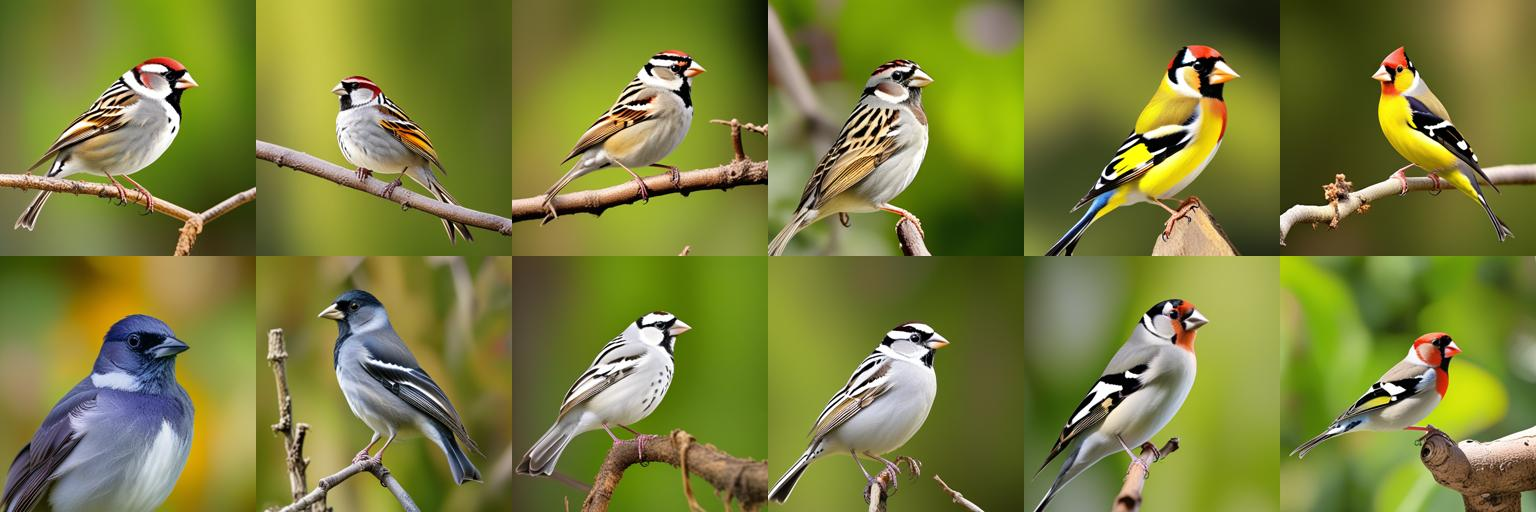

In [ ]:
STEPS = 20  # @param {type:"integer"}
GUIDANCE_SCALE = 4.5  # @param {type:"number"}
IMAGES_PER_PROMPT = 2  # @param {type:"integer"}
MAX_GENERATION_PROMPTS = 12  # @param {type:"integer"}
EVAL_SEED = 0


def grid(images, path, columns=6):
    tiles = [im.resize((256, 256)) for im in images]
    rows = (len(tiles) + columns - 1) // columns
    sheet = Image.new('RGB', (256 * columns, 256 * rows), 'white')
    for i, tile in enumerate(tiles):
        sheet.paste(tile, (256 * (i % columns), 256 * (i // columns)))
    sheet.save(path)
    return path


reset_to_pretrained()
scorer = ClipScorer(weights_dir=SCORER_WEIGHTS_DIR, device=pipe.device)
t0 = time.perf_counter()
frozen_val = pipe.evaluate(val_records, seed=EVAL_SEED)
frozen_test = pipe.evaluate(test_records, seed=EVAL_SEED)
print({'frozen_denoising_mse': {'validation': frozen_val['denoising_mse'], 'test': frozen_test['denoising_mse']}, 'by_timestep_test': frozen_test['by_timestep'], 'adapted': frozen_test['adapted'], 'seconds': round(time.perf_counter() - t0, 1)})

if len(prompts) > MAX_GENERATION_PROMPTS:
    print({'warning': f'{len(prompts)} distinct training captions: generating for the first {MAX_GENERATION_PROMPTS} only (each image takes several seconds per model on a T4). Raise MAX_GENERATION_PROMPTS to score more.'})
generation_prompts = [p for p in prompts[:MAX_GENERATION_PROMPTS] for _ in range(IMAGES_PER_PROMPT)]
frozen_generation = pipe.generate(generation_prompts, seed=1000, steps=STEPS, guidance_scale=GUIDANCE_SCALE)
print({'generated': len(frozen_generation['images']), 'steps': frozen_generation['steps'], 'guidance_scale': frozen_generation['guidance_scale'], 'seconds': frozen_generation['seconds'], 'adapted': frozen_generation['model']['adapted']})
frozen_scores = score_generations(scorer, frozen_generation['images'], references=test_records)
# The real held-out photographs scored the same way, LEAVE-ONE-OUT: each photo's reference is the other test photos of
# its caption, never itself. A reference line to read the generations against, not a ceiling.
real_reference = real_photo_reference(scorer, test_records)
print({'frozen_generations': {k: frozen_scores[k] for k in ('clip_prompt_similarity', 'label_accuracy', 'reference_similarity')}, 'chance_label_accuracy': round(1 / len(set(generation_prompts)), 3)})
print({'real_photo_reference_leave_one_out': {k: real_reference.get(k) for k in ('clip_prompt_similarity', 'label_accuracy', 'reference_similarity')}, 'photos_without_a_reference': real_reference['n_without_reference']})
for entry in frozen_scores['per_image'][::IMAGES_PER_PROMPT]:
    print({'prompt': entry['prompt'][:42], 'clip': entry['clip_prompt_similarity'], 'nearest': entry['nearest_prompt'][13:40], 'correct': entry['correct'], 'reference_similarity': entry.get('reference_similarity')})
frozen_grid = grid([g['image'] for g in frozen_generation['images']], 'outputs/pixart_sigma_generation_frozen_grid.jpg')
print({'grid': str(frozen_grid), 'order': 'generation prompts in the order printed above, IMAGES_PER_PROMPT images each', 'gpu_memory_gb': gpu_memory_gb()})
display(Image.open(frozen_grid))

## 7. Bounded LoRA fine-tuning

**What to notice (Section 6):** the frozen generations next to the real-photo reference line, metric by metric, and the per-species rows: which birds did CLIP name correctly, against a chance level of 1 in 6?

<details><summary>Check your reasoning</summary>Below on prompt similarity, above on reference similarity. In the recorded Colab T4 run of blob `4cf243c1` (commit `a61c09b`, 8 October 2026, not re-run here) the frozen generations scored prompt similarity 26.79 against the real photographs' 30.25, but reference similarity 65.57 against a leave-one-out real-photo value of 57.72; label accuracy was 0.50 (chance 0.17) against the real photos' 0.917. The Kaggle T4 run of the earlier blob `99829b51` (19 September 2026, not re-run here) printed 88.66 for the real photos' reference similarity because each photo was then included in its own reference; this version excludes it. So the reference line is not a ceiling: on reference similarity the generations, compared with a two-photo mean, sit above real photographs compared with one other photo.</details>

`pipe.adapt` trains the 448 LoRA tensors (rank 8, 4,128,768 parameters — 0.7 % of the transformer) that `peft` attached to the query, key, value and output projections of the self- and cross-attention of every block, and nothing else; the transformer, the VAE and the text encoder are frozen. Each step takes one training photograph's latent (VAE-encoded once, seeded), draws a timestep uniformly from the 1,000-step schedule and a noise tensor (both seeded), adds the noise, and minimises the MSE between the predicted and the true noise; AdamW at a fixed learning rate, gradient-norm clipping at 1.0, float16 autocast with loss scaling on CUDA. Epoch 0 records the frozen model's validation loss, and the epoch with the lowest validation denoising loss is kept. `reset_to_pretrained()` runs first, so re-running this cell with a different `EPOCHS` or `LEARNING_RATE` trains again from the pretrained base (`adapt` refuses to continue from an already trained adapter).

Watch the validation denoising MSE from epoch 0; four epochs over 36 images (144 steps) took about two minutes on a T4 in the recorded Colab T4 run of blob `4cf243c1` (commit `a61c09b`, 8 October 2026, not re-run here). The training loss is a noisy per-step average over random timesteps and is not the quality signal — the paired held-out numbers in Section 8 are.

**Predict before running:** will the validation loss fall at every epoch? Will the training loss?

In [ ]:
EPOCHS = 4  # @param {type:"integer"}
LEARNING_RATE = 1e-4  # @param {type:"number"}
BATCH_SIZE = 1  # @param {type:"integer"}


def report(entry):
    row = {'epoch': entry['epoch'], 'train_loss': None if entry['train_loss'] is None else round(entry['train_loss'], 4), 'val_denoising_mse': entry['val_loss']}
    if 'note' in entry:
        row['note'] = entry['note']
    print(row)


# A re-run (an optional experiment) starts again from the pretrained base, so epoch 0 is the frozen model.
reset_to_pretrained()
t0 = time.perf_counter()
adapt_result = pipe.adapt(train_records, val_records, epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE, seed=EVAL_SEED, progress=report)
adapt_seconds = round(time.perf_counter() - t0, 1)
print({'trainable_parameters': adapt_result['n_trainable'], 'total_parameters': adapt_result['n_total'], 'steps': adapt_result['n_steps'], 'best_epoch': adapt_result['best_epoch'], 'precision': adapt_result['precision'], 'seconds': adapt_seconds, 'gpu_memory_gb': gpu_memory_gb()})

{'epoch': 0, 'train_loss': None, 'val_denoising_mse': 0.109093, 'note': 'frozen model (LoRA at initialisation: B = 0)'}


{'epoch': 1, 'train_loss': 0.1151, 'val_denoising_mse': 0.108994}


{'epoch': 2, 'train_loss': 0.1614, 'val_denoising_mse': 0.108949}


{'epoch': 3, 'train_loss': 0.0699, 'val_denoising_mse': 0.10893}


{'epoch': 4, 'train_loss': 0.0847, 'val_denoising_mse': 0.108926}
{'trainable_parameters': 4128768, 'total_parameters': 614984864, 'steps': 144, 'best_epoch': 4, 'precision': 'float16 autocast + GradScaler', 'seconds': 112.6, 'gpu_memory_gb': 2.22}


## 8. Held-out evaluation: the paired comparison

**What to notice (Section 7):** the validation loss per epoch, the kept epoch and the size of the change.

<details><summary>Check your reasoning</summary>In the recorded Colab T4 run of blob `4cf243c1` (commit `a61c09b`, 8 October 2026, not re-run here) the validation loss fell at every epoch (0.109093 → 0.108991 → 0.108946 → 0.108929 → 0.108927) and epoch 4 was kept, while the training loss went 0.115 → 0.161 → 0.070 → 0.085: up, down, up. Each training step draws its own random timestep, and the loss depends strongly on it (Section 6 prints the per-timestep loss: about 0.36 at t = 100 and 0.0002 at t = 900), so a per-epoch training average is noisy; the validation loss uses the same fixed noise every time and is the signal used to choose the epoch. Note how small the change is: about 0.1 % of the frozen value. Training took 119.9 s.</details>

The test photographs were never used for training or epoch selection. The adapted model is scored exactly as the frozen model was in Section 6 — the same seed, so the same latents, noise and timesteps, and the same prompt/seed pairs for generation — and the table puts the frozen, the adapted and the real-photo reference numbers side by side. The cell asserts only what the procedure guarantees — the kept epoch's validation loss is no higher than the frozen model's (epoch 0) and the re-scored validation loss matches the history — and prints the test comparison without a directional assertion: a lower test denoising MSE is what to look for, not what is promised. The frozen and adapted images are displayed side by side (top row frozen, bottom row adapted; each column one prompt and seed). Twelve images per model from one seeded run give no dispersion estimate; these are sample-sanity numbers that show the adaptation contract works, not a benchmark, and CLIP agreement is not a human judgement of quality.

**Predict before running:** will every species' reference similarity rise after adaptation? Will label accuracy?

{'denoising_mse_validation': {'frozen': 0.109093, 'adapted': 0.108926}}
{'denoising_mse_test': {'frozen': 0.105983, 'adapted': 0.105809}}
{'denoising_mse_test_by_timestep': {'100': {'frozen': 0.358295, 'adapted': 0.357987}, '300': {'frozen': 0.141291, 'adapted': 0.140997}, '500': {'frozen': 0.027073, 'adapted': 0.026877}, '700': {'frozen': 0.003065, 'adapted': 0.003018}, '900': {'frozen': 0.000189, 'adapted': 0.000168}}}
{'clip_prompt_similarity': {'frozen': 26.785, 'adapted': 28.022, 'real_photo_reference': 30.25}}
{'label_accuracy': {'frozen': 0.5, 'adapted': 0.5, 'real_photo_reference': 0.9167}}
{'reference_similarity': {'frozen': 65.57, 'adapted': 68.224, 'real_photo_reference': 57.722}}
{'real_photo_reference': 'leave-one-out real-photo reference', 'reading': {'clip_prompt_similarity': 'not an upper bound: a generator conditioned on the prompt can match it more closely than a photograph does', 'label_accuracy': 'a reference: real photographs of these species are what the captions 

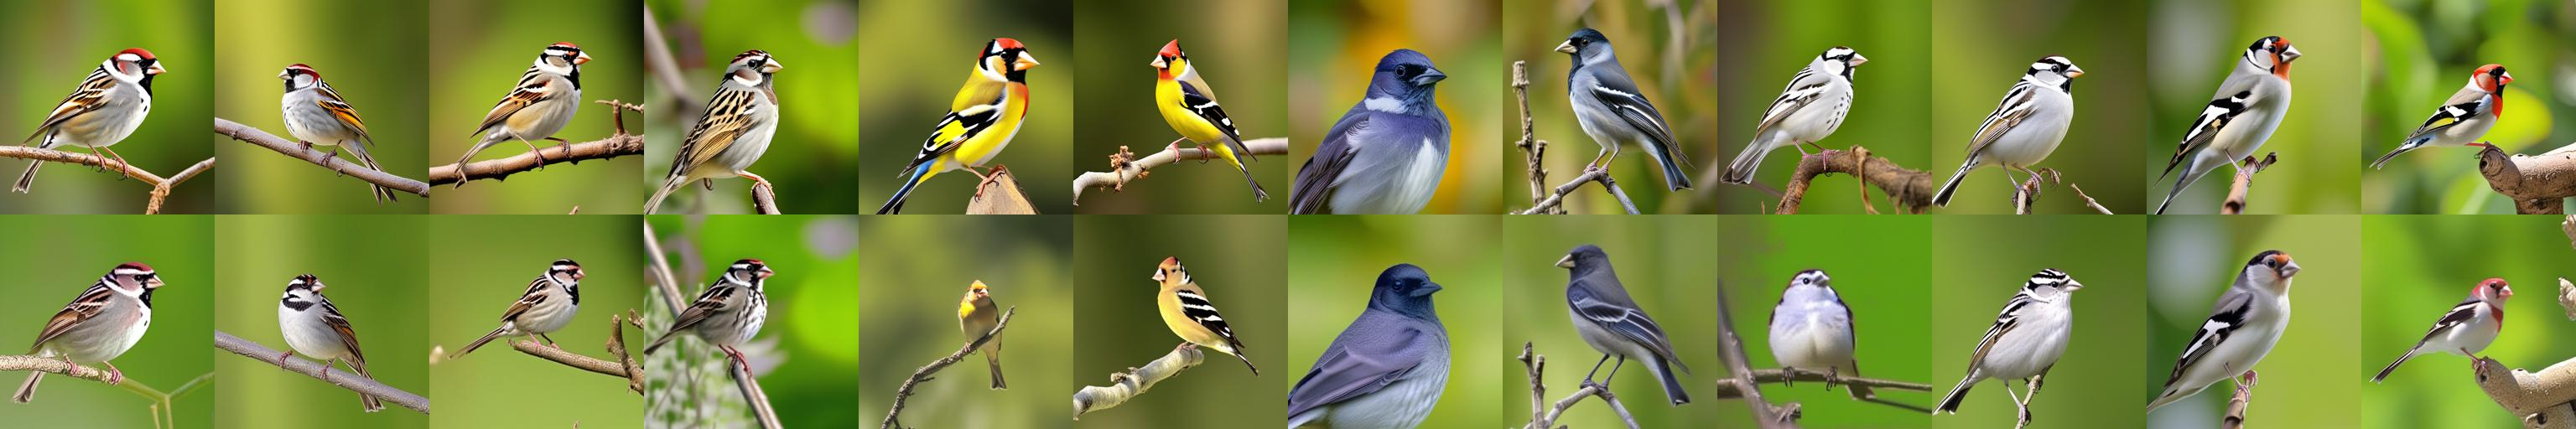

{'test_denoising_mse_change': -0.000174, 'note': 'held-out observation, not asserted'}
{'report': 'outputs/pixart_sigma_generation_evaluation_report.json'}


In [ ]:
if pipe.adapter is None:
    raise RuntimeError('Section 8 compares the adapted model with the frozen one, and no adapted model is in memory: run Section 7 first (Section 10 returns the pipeline to the pretrained base).')
adapted_val = pipe.evaluate(val_records, seed=EVAL_SEED)
adapted_test = pipe.evaluate(test_records, seed=EVAL_SEED)
adapted_generation = pipe.generate(generation_prompts, seed=1000, steps=STEPS, guidance_scale=GUIDANCE_SCALE)
adapted_scores = score_generations(scorer, adapted_generation['images'], references=test_records)
comparison = {
    'denoising_mse_validation': {'frozen': frozen_val['denoising_mse'], 'adapted': adapted_val['denoising_mse']},
    'denoising_mse_test': {'frozen': frozen_test['denoising_mse'], 'adapted': adapted_test['denoising_mse']},
    'denoising_mse_test_by_timestep': {t: {'frozen': frozen_test['by_timestep'][t], 'adapted': adapted_test['by_timestep'][t]} for t in adapted_test['by_timestep']},
    'clip_prompt_similarity': {'frozen': frozen_scores['clip_prompt_similarity'], 'adapted': adapted_scores['clip_prompt_similarity'], 'real_photo_reference': real_reference['clip_prompt_similarity']},
    'label_accuracy': {'frozen': frozen_scores['label_accuracy'], 'adapted': adapted_scores['label_accuracy'], 'real_photo_reference': real_reference['label_accuracy']},
    'reference_similarity': {'frozen': frozen_scores.get('reference_similarity'), 'adapted': adapted_scores.get('reference_similarity'), 'real_photo_reference': real_reference.get('reference_similarity')},
}
for name, row in comparison.items():
    print({name: row})
print({'real_photo_reference': real_reference['reference_kind'], 'reading': real_reference['reading']})
for before, after in zip(frozen_scores['per_image'][::IMAGES_PER_PROMPT], adapted_scores['per_image'][::IMAGES_PER_PROMPT]):
    print({'prompt': before['prompt'][:42], 'reference_similarity': {'frozen': before.get('reference_similarity'), 'adapted': after.get('reference_similarity')}, 'correct': {'frozen': before['correct'], 'adapted': after['correct']}})
adapted_grid = grid([g['image'] for g in adapted_generation['images']], 'outputs/pixart_sigma_generation_adapted_grid.jpg')
pair_grid = grid([g['image'] for g in frozen_generation['images']] + [g['image'] for g in adapted_generation['images']], 'outputs/pixart_sigma_generation_frozen_vs_adapted.jpg', columns=len(generation_prompts))
print({'grid': str(adapted_grid), 'side_by_side': str(pair_grid), 'rows': 'top: frozen, bottom: adapted; same prompt and seed in each column'})
display(Image.open(pair_grid))
evaluation_report = {
    'model': {'id': MODEL_ID, 'revision': MODEL_REVISION, 'key': MODEL_KEY},
    'components': {'id': BASE_ID, 'revision': BASE_REVISION},
    'scorer': frozen_scores['scorer'],
    'data_source': data_source,
    'dataset': dataset_report,
    'generation': {'steps': STEPS, 'guidance_scale': GUIDANCE_SCALE, 'images_per_prompt': IMAGES_PER_PROMPT, 'prompts': len(generation_prompts) // IMAGES_PER_PROMPT, 'seed': 1000},
    'frozen': {'validation': frozen_val, 'test': frozen_test, 'generations': frozen_scores},
    'adapted': {'validation': adapted_val, 'test': adapted_test, 'generations': adapted_scores},
    'real_photo_reference': real_reference,
    'comparison': comparison,
    'adaptation': {k: v for k, v in adapt_result.items() if k not in ('history', 'trainable_names')},
    'history': adapt_result['history'],
    'adaptation_seconds': adapt_seconds,
}
with open('outputs/pixart_sigma_generation_evaluation_report.json', 'w', encoding='utf-8') as f:
    json.dump(evaluation_report, f, indent=2)
best = adapt_result['history'][adapt_result['best_epoch']]
assert best['val_loss'] <= adapt_result['history'][0]['val_loss']
assert abs(adapted_val['denoising_mse'] - best['val_loss']) < 1e-4
print({'test_denoising_mse_change': round(adapted_test['denoising_mse'] - frozen_test['denoising_mse'], 6), 'note': 'held-out observation, not asserted'})
print({'report': 'outputs/pixart_sigma_generation_evaluation_report.json'})

## 9. A new prompt, artifact export and fresh reload

**What to notice (Section 8):** the per-species rows, not only the means — and whether the bottom row of the side-by-side grid looks more like the photographs of each species than the top row.

<details><summary>Check your reasoning</summary>Not every one. In the recorded Colab T4 run of blob `4cf243c1` (commit `a61c09b`, 8 October 2026, not re-run here) the test denoising MSE fell from 0.105983 to 0.105811 (−0.000172, about 0.16 %) and was lower at all five timesteps; the mean reference similarity rose from 65.57 to 69.27 and prompt similarity from 26.79 to 28.40; label accuracy moved from 0.50 to 0.58, one of twelve images (in the Kaggle T4 run of the earlier blob `99829b51` (19 September 2026, not re-run here) it stayed at 0.50), and two of the six printed rows moved the other way (American Goldfinch 80.33 → 74.82, Dark-eyed Junco 62.12 → 61.67). With two images per species and one seed, a single image can move a species' number either way; the paired loss on 12 photographs at five timesteps is the steadier evidence, and even it changed by a fraction of a percent.</details>

The adapted model renders `NEW_PROMPT` — a composition that appears in no training caption — at two seeds; the CLIP prompt similarity is printed as a sanity check, not an evaluation, and both images are displayed.

`pipe.save_artifact` writes the 448 trained tensors (about 16 MB) as `adapter.safetensors` with a `manifest.json` recording the artifact format, the transformer's id and revision, the component snapshot's id and revision, the LoRA configuration, the tensor names, the file size and SHA-256, the training configuration and the epoch history (OUT8). `PixArtSigmaPipeline.from_artifact` re-verifies both snapshots, checks the manifest, the LoRA scope and the digest **before** deserialising, loads a fresh transformer with the adapter attached and overlays the tensors — a new object from files, not the in-memory model (VER2). The fresh pipeline adopts the prompt embeddings already encoded (so the text encoder is not loaded again), and the cell asserts that it reproduces the same held-out denoising loss and the same image for the same prompt and seed (VER4: a mean absolute pixel difference below 1 on the 0..255 scale — same device, same kernels). Once parity is checked the reloaded pipeline is **released**, so it does not stay resident for a later pass. The result file records the per-module SHA-256 of the carried code next to the source revision.

**Predict before running:** will the reloaded pipeline reproduce the adapted model's numbers exactly, or only closely?

{'new_prompt': 'a photo of a House Finch (Haemorhous mexicanus) perched on a snow-covered branch in winter', 'clip_prompt_similarity': 26.095, 'seconds': 11.74, 'note': 'sanity check, not an evaluation'}


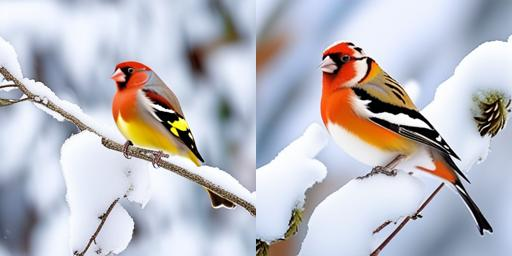

{'artifact': 'outputs/pixart_sigma_generation_adapter', 'format': 'org.valcorza.pixart-sigma-generation.adapter.v1', 'tensors': 448, 'bytes': 16570800, 'sha256': 'ce3c39ed813463ef...'}


{'reload_parity': {'denoising_mse_diff': 0.0, 'mean_abs_pixel_diff': 0.0}, 'reloaded_best_epoch': 4, 'gpu_memory_gb_with_reloaded': 3.8}


{'reloaded_pipeline_released': True, 'gpu_memory_gb': 2.22}
outputs/:
  - outputs/pixart_sigma_generation_adapted_grid.jpg (73.5 KB)
  - outputs/pixart_sigma_generation_adapter/adapter.safetensors (16182.4 KB)
  - outputs/pixart_sigma_generation_adapter/manifest.json (29.5 KB)
  - outputs/pixart_sigma_generation_evaluation_report.json (23.5 KB)
  - outputs/pixart_sigma_generation_frozen_grid.jpg (95.3 KB)
  - outputs/pixart_sigma_generation_frozen_vs_adapted.jpg (168.3 KB)
  - outputs/pixart_sigma_generation_new_prompt_0.png (295.4 KB)
  - outputs/pixart_sigma_generation_new_prompt_1.png (299.8 KB)
  - outputs/pixart_sigma_generation_new_prompt_grid.jpg (19.5 KB)
  - outputs/pixart_sigma_generation_result.json (4.8 KB)
  - outputs/pixart_sigma_generation_sample_captions.csv (2.3 KB)


In [ ]:
import platform
import shutil

if pipe.adapter is None:
    raise RuntimeError('Section 9 exports the adapted model, and no adapted model is in memory: run Section 7 (and Section 8) first.')
new_generation = pipe.generate([NEW_PROMPT, NEW_PROMPT], seed=2000, steps=STEPS, guidance_scale=GUIDANCE_SCALE)
new_scores = score_generations(scorer, new_generation['images'])
print({'new_prompt': NEW_PROMPT, 'clip_prompt_similarity': new_scores['clip_prompt_similarity'], 'seconds': new_generation['seconds'], 'note': 'sanity check, not an evaluation'})
for i, entry in enumerate(new_generation['images']):
    entry['image'].save(f'outputs/pixart_sigma_generation_new_prompt_{i}.png')
display(Image.open(grid([g['image'] for g in new_generation['images']], 'outputs/pixart_sigma_generation_new_prompt_grid.jpg', columns=2)))

artifact_dir = Path('outputs/pixart_sigma_generation_adapter')
shutil.rmtree(artifact_dir, ignore_errors=True)
pipe.save_artifact(artifact_dir, metadata={'tutorial': 'pixart_sigma_generation', 'data_source': data_source})
artifact_manifest = json.loads((artifact_dir / 'manifest.json').read_text(encoding='utf-8'))
print({'artifact': str(artifact_dir), 'format': artifact_manifest['format'], 'tensors': len(artifact_manifest['tensors']), 'bytes': artifact_manifest['files'][0]['bytes'], 'sha256': artifact_manifest['files'][0]['sha256'][:16] + '...'})

reloaded = PixArtSigmaPipeline.from_artifact(artifact_dir, weights_dir=WEIGHTS_DIR, base_dir=BASE_WEIGHTS_DIR, device=pipe.device)
reloaded.import_prompt_cache(pipe.export_prompt_cache())
reloaded_test = reloaded.evaluate(test_records, seed=EVAL_SEED)
before = pipe.generate([prompts[0]], seed=3000, steps=STEPS, guidance_scale=GUIDANCE_SCALE)['images'][0]['image']
after = reloaded.generate([prompts[0]], seed=3000, steps=STEPS, guidance_scale=GUIDANCE_SCALE)['images'][0]['image']
parity = {'denoising_mse_diff': round(abs(reloaded_test['denoising_mse'] - adapted_test['denoising_mse']), 8), 'mean_abs_pixel_diff': round(float(np.abs(np.asarray(before, dtype=np.float32) - np.asarray(after, dtype=np.float32)).mean()), 4)}
reloaded_best_epoch = reloaded.adapter['best_epoch']
print({'reload_parity': parity, 'reloaded_best_epoch': reloaded_best_epoch, 'gpu_memory_gb_with_reloaded': gpu_memory_gb()})
assert parity['denoising_mse_diff'] < 1e-6 and parity['mean_abs_pixel_diff'] < 1.0
# The parity check is done: release the reloaded pipeline so nothing extra stays resident for a later pass (a BYOD
# re-run loads the 9.5 GB text encoder in Section 5 beside `pipe`).
del reloaded
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print({'reloaded_pipeline_released': True, 'gpu_memory_gb': gpu_memory_gb()})

result_payload = {
    'notebook_source': NOTEBOOK_SOURCE,
    'repository_revision': NOTEBOOK_SOURCE['repository_revision'],
    'module_sha256_per_file': NOTEBOOK_SOURCE['module_sha256_per_file'],
    'model': {**evaluation_report['model'], 'model_license': MODEL_LICENSE, 'device': pipe.device, 'precision': str(pipe.dtype).replace('torch.', ''), 'source': pipe.source},
    'components': {**evaluation_report['components'], 'license': BASE_LICENSE},
    'scorer': {**evaluation_report['scorer'], 'license': SCORER_LICENSE},
    'provenance': {
        'snapshots': {'transformer': len(MANIFEST['files']), 'components': len(BASE_MANIFEST['files']), 'scorer': len(SCORER_MANIFEST['files'])},
        'safetensors_only': True,
        'remote_code_executed': False,
        'text_encoder_released_before_training': released,
        'data_base_url': CORPUS_BASE_URL,
        'data_license': CORPUS_LICENSE,
    },
    'runtime': {'python': platform.python_version(), 'torch': torch.__version__, 'diffusers': diffusers.__version__, 'transformers': transformers.__version__, 'peft': peft.__version__, 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},
    'data_source': data_source,
    'comparison': comparison,
    'real_photo_reference': {'kind': real_reference['reference_kind'], 'reading': real_reference['reading']},
    'artifact': {'dir': str(artifact_dir), 'sha256': artifact_manifest['files'][0]['sha256'], 'bytes': artifact_manifest['files'][0]['bytes']},
    'reload_parity': parity,
    'reloaded_best_epoch': reloaded_best_epoch,
}
with open('outputs/pixart_sigma_generation_result.json', 'w', encoding='utf-8') as f:
    json.dump(result_payload, f, indent=2)

print('outputs/:')
for path in sorted(Path('outputs').rglob('*')):
    if path.is_file():
        print(f'  - {path.as_posix()} ({path.stat().st_size / 1024:.1f} KB)')

## 10. Your turn — change one thing: the guidance scale

**What to notice (Section 9):** the reload parity line, the GPU memory with the reloaded pipeline and after its release, and the list of files under `outputs/`.

<details><summary>Check your reasoning</summary>Exactly, on the same runtime. In the recorded Colab T4 run of blob `4cf243c1` (commit `a61c09b`, 8 October 2026, not re-run here) both differences were 0.0: the same bytes, the same embeddings and the same kernels give the same arithmetic. On a different GPU, driver or library build the numbers would differ slightly, which is why parity is checked in one session. Releasing the reloaded pipeline brought GPU memory back from 3.8 GB to 2.22 GB in that run.</details>

**Predict → Change one thing → Run → Observe → Explain.**

1. **Predict:** classifier-free guidance runs the transformer twice per step — with the prompt and with the empty negative prompt — and pushes the prediction away from the unconditioned one by the guidance scale. With guidance 1.0 (no guidance) or 9.0 instead of 4.5, will the CLIP prompt similarity and the label accuracy of the pretrained model's images go up, down or stay put? And the time per image? Write your guess down.
2. **Change one thing:** set `RUN_ACTIVITY = True` in the cell below and nothing else. It renders the Section 6 prompts with the same seeds and steps at guidance 1.0, 4.5 and 9.0 with the **pretrained base** (`reset_to_pretrained()` runs first).
3. **Run:** run this cell only (about three to four minutes on a T4). It writes only under `outputs/activity/` and changes no earlier result; afterwards the in-memory adapter is reset, so run Section 7 again before re-running Sections 8 or 9 (the exported artifact on disk is unchanged).
4. **Observe:** one row per guidance scale — prompt similarity, label accuracy, reference similarity and seconds — and a grid with one row per guidance scale, each column one prompt and seed.
5. **Explain:** what did guidance buy on each reading, what did it cost in time, and how far apart must two rows be before twelve images make the difference believable?

<details><summary>Check your reasoning</summary>No run of this activity is recorded yet, so compare your prediction with what the cell printed rather than with a number here. Two things to check either way: the 4.5 row should reproduce Section 6's frozen numbers (same model, prompts, seeds, steps and guidance) when the runtime is the same, which makes it the control row; and guidance 1.0 should take roughly half the time of the others, because the pipeline skips the unconditioned pass when the scale is 1. With twelve images per row, one image changing its nearest caption moves label accuracy by 0.083.</details>

In [ ]:
RUN_ACTIVITY = False  # @param {type:"boolean"}
ACTIVITY_GUIDANCE = (1.0, 4.5, 9.0)

if not RUN_ACTIVITY:
    print('Activity not run: set RUN_ACTIVITY = True and run this cell. It writes only under outputs/activity/ and changes no earlier result.')
else:
    reset_to_pretrained()
    activity_dir = Path('outputs/activity')
    activity_dir.mkdir(parents=True, exist_ok=True)
    activity_rows = {}
    activity_images = []
    for guidance in ACTIVITY_GUIDANCE:
        generation = pipe.generate(generation_prompts, seed=1000, steps=STEPS, guidance_scale=guidance)
        scores = score_generations(scorer, generation['images'], references=test_records)
        activity_rows[guidance] = {'clip_prompt_similarity': scores['clip_prompt_similarity'], 'label_accuracy': scores['label_accuracy'], 'reference_similarity': scores.get('reference_similarity'), 'seconds': generation['seconds'], 'adapted': generation['model']['adapted']}
        activity_images += [g['image'] for g in generation['images']]
        print({'guidance_scale': guidance, **activity_rows[guidance]})
    activity_grid = grid(activity_images, activity_dir / 'pixart_sigma_generation_guidance.jpg', columns=len(generation_prompts))
    print({'grid': str(activity_grid), 'rows': [f'guidance {g}' for g in ACTIVITY_GUIDANCE], 'model': 'the pretrained base (LoRA B = 0)', 'real_photo_reference': {k: real_reference.get(k) for k in ('clip_prompt_similarity', 'label_accuracy', 'reference_similarity')}})
    display(Image.open(activity_grid))
    with open(activity_dir / 'pixart_sigma_generation_guidance.json', 'w', encoding='utf-8') as f:
        json.dump({'model': 'pretrained base, LoRA B = 0', 'seed': 1000, 'steps': STEPS, 'prompts': generation_prompts, 'rows': {str(k): v for k, v in activity_rows.items()}}, f, indent=2)

Activity not run: set RUN_ACTIVITY = True and run this cell. It writes only under outputs/activity/ and changes no earlier result.


## Interpretation and limits

**What to notice (Section 10):** if you ran the activity, whether the 4.5 row matches Section 6 and how the readings and the seconds changed with the guidance scale.

Read your own Section 8 before concluding; the claim below is what the run is designed to test, not a result stated in advance. If the test denoising loss fell and the generations moved towards the held-out photographs for most species, a LoRA of four million parameters trained for a few minutes on 36 photographs has taught the diffusion transformer something about a narrow visual domain from a handful of captioned images, measured on identical inputs before and after, and the artifact that carries the change is 16 MB. Check the size and the per-species rows: in the recorded run of the previous version the test loss fell by 0.14 %, label accuracy did not change, and two of the six printed species rows fell while the mean reference similarity rose.

The numbers are sample-sanity evidence. A denoising loss is the training objective, not a quality score; CLIP similarity and CLIP's nearest-caption vote are a frozen model's opinion, not a human judgement, and CLIP itself has biases about what a species name looks like; twelve images per model from one seeded run give no dispersion estimate; and nothing here measures aesthetics, diversity, artefacts or prompt fidelity beyond the six captions. The real photographs are a **reference line, not a ceiling**: generated images can score above them on reference similarity (they did in the recorded run), so a generation that beats a photograph on a CLIP reading is not a better bird picture. Fine-tuning on a narrow domain can also erode the model elsewhere — the new prompt in Section 9 is a sanity check on one composition, not a test of generality.

**Pretraining overlap.** The 60 photographs are public iNaturalist images. Photographs like them — possibly these ones — may be in the web-scale data behind PixArt-Σ and behind the LAION-2B CLIP scorer, so both the frozen generator's and the scorer's familiarity with these species can be inflated; nothing here measures that.

**Run-to-run variability.** The seeds fix the data split, the noise, the timesteps and the generation seeds, not the arithmetic: float16 matrix multiplications, attention and autocast are not bit-reproducible across GPU models, drivers and library builds. A run on another runtime gives slightly different losses, images and CLIP readings — enough to flip a borderline nearest-caption vote, and of the same order as the 0.14 % test-loss change — while reload parity within one session stays exact.

Three things to carry to real data. **Captions are the contract:** the adapter learns the association between the caption text and the images; a caption that does not describe its image, or one caption for very different images, teaches noise. **Stratify by caption; keep near-duplicates together:** the split is stratified within each caption, so every held-out caption also appears in training and the held-out loss measures generalisation to new photographs of known captions, not to new captions; a caption with fewer than three images is used for training only, and photos of one individual or one burst belong on the same side of the split. **Licences travel with the outputs:** the Σ weights are Open RAIL++-M, the training photographs here are CC0 — with your own data, the rights to the images and to what the adapter produces are yours to establish.

A successful default run **proves** that the pipeline modules carried in this standalone notebook (their per-module SHA-256 values are in the result file) can stage and digest-verify three pinned safetensors snapshots, fetch and validate digest-pinned real photographs, encode prompts and release the encoder, execute bounded LoRA fine-tuning, evaluate the frozen and the adapted model on identical held-out inputs beside a leave-one-out real-photo reference, and emit the shown machine-readable artifacts — without the repository being reachable. It does **not** establish benchmark superiority, production fitness, or image quality beyond the checks shown.

**Next experiments** (each starts after the default Run all; Sections 6 and 7 always start again from the pretrained base):

1. **Guidance scale:** the Section 10 activity (`RUN_ACTIVITY = True`), run that cell only.
2. **Training length or rate:** in Section 7 set `EPOCHS` or `LEARNING_RATE`, then select Section 7 and choose **Runtime → Run after** (Sections 7–10 are recomputed; the frozen numbers of Section 6 stay valid). Watch the validation loss for the epoch where it turns.
3. **Guidance for the whole comparison:** in Section 6 set `GUIDANCE_SCALE`, then **Run after** from Section 6. The frozen and adapted models are both scored at that scale.
4. **A less noisy label accuracy:** in Section 6 set `IMAGES_PER_PROMPT = 4`, then **Run after** from Section 6.
5. **Your own captioned photographs:** in Section 4 set `USE_BYOD = True` (upload, or set `BYOD_PATH`), then **Run after** from Section 4. Section 5 frees the GPU first and Section 6 resets the adapter; compare the adapted numbers with your photographs' leave-one-out reference line.

## Troubleshooting

- **Section 1 stops with "needs a Linux x86_64 runtime".** The locked environment is built from manylinux wheels; use Colab, Kaggle or a Linux Jupyter server with a CUDA GPU.
- **Section 1 fails to download `uv`, Python or a package.** The runtime needs `pypi.org`, `files.pythonhosted.org` and the python-build-standalone release host. Re-run the cell; a size or SHA-256 mismatch is refused on purpose.
- **Section 3 is slow or stops while downloading.** It fetches about 22 GB from the Hub; an anonymous download can be rate-limited. Run Section 3 again: files already staged and verified are not fetched twice. A size or SHA-256 mismatch is refused; delete the named file under `weights/` and run Section 3 again.
- **"No space left on device".** The snapshots need about 25 GB and the isolated environment several more; free disk or use a runtime with more of it.
- **"The isolated environment's Python process exited".** Usually out of host or GPU memory. Restart the session and choose **Run all** again.
- **CUDA out of memory.** The encoder (Section 5) and a training graph never share the GPU. Re-run from Section 5 (**Run after**), which releases the reloaded pipeline and the scorer first; if it persists, restart the session and choose **Run all**. Keep `BATCH_SIZE = 1` on a 16 GB GPU.
- **Section 4: "Upload exactly one .zip … (got 0 files)".** The upload was cancelled or empty. Run Section 4 again and pick one zip, or set `BYOD_PATH`.
- **Section 4 refuses a BYOD dataset.** The message names the file or the rule — a member missing from the zip, an unreadable image, a side outside 256..4096 px, a missing column, or too few images for the split (six distinct images, one caption with three or more). Fix the zip and run Section 4 again.
- **Section 8 or 9: "no adapted model is in memory".** Section 10 (or a re-run of Section 6) returned the pipeline to the pretrained base; run Section 7 first (**Run after** from Section 7).
- **Section 9's parity assertion fails.** The export or reload is broken; do not use that artifact. Run Sections 7–9 again.

## Glossary

- **Latent / VAE:** the SDXL VAE compresses a 512 × 512 image to a 4-channel 64 × 64 latent and decodes it back; the transformer works on latents, not pixels.
- **Timestep / noise prediction:** training noises a latent to a chosen timestep t (t = 0 clean, t = 999 almost pure noise); the transformer predicts the noise that was added.
- **Denoising loss (MSE):** the mean squared error between the predicted and the true noise; the training objective, here also measured on held-out photographs at five fixed timesteps.
- **Classifier-free guidance:** each sampling step runs the transformer with the prompt and with an empty prompt and moves the prediction away from the empty one by the guidance scale; 1.0 means no guidance.
- **DPM-Solver++:** the multistep sampler that turns noise into a latent in 20 steps.
- **LoRA:** low-rank matrices A and B added beside frozen weight matrices; only A and B are trained, and B starts at zero.
- **CLIP prompt similarity:** the cosine (× 100) between a CLIP image embedding and the CLIP text embedding of its prompt.
- **Zero-shot label accuracy / chance level:** the share of images whose nearest caption, by CLIP cosine among the dataset's captions, is their own (an argmax, no threshold); guessing among six captions gives 1 in 6.
- **Reference similarity:** the cosine (× 100) between an image and the mean embedding of the held-out real photographs of its caption.
- **Leave-one-out reference:** the same readings on the real photographs, each compared with the others of its caption and never with itself; a reference line, not an upper bound.
- **Held-out / paired comparison:** photographs never used for training or epoch selection, scored before and after with identical latents, noise and timesteps.
- **Adapter / safetensors / reload parity:** the saved trained tensors / a code-free tensor file format / the check that base + adapter reproduces the in-memory model's loss and image.
- **Isolated environment:** the separate Python environment Section 1 builds from hash-locked packages, where every later cell runs.

## Conclusion (your notes)

Fill in from the numbers this run printed; keep each claim to what the evidence shows.

- **Task:** which photographs, which captions, which split sizes?
- **Principal result:** the test denoising MSE before and after, with `n` photographs and five timesteps — and the size of the change.
- **Instrument readings:** prompt similarity, label accuracy (against chance) and reference similarity, frozen and adapted, beside the leave-one-out real-photo reference line. Which reading moved, and on how many images?
- **Uncertainty or failure mode:** which species moved the other way? What did your Section 10 run change?
- **Limitations:** what does this run *not* show (see Interpretation and limits)?

## References

References follow the IEEE style.

[1] J. Chen, C. Ge, E. Xie *et al.*, "PixArt-Σ: Weak-to-strong training of diffusion transformer for 4K text-to-image generation," in *Proc. Eur. Conf. Comput. Vis. (ECCV)*, 2024. [Online]. Available: https://arxiv.org/abs/2403.04692

[2] J. Ho and T. Salimans, "Classifier-free diffusion guidance," arXiv:2207.12598, 2022. [Online]. Available: https://arxiv.org/abs/2207.12598

[3] E. J. Hu *et al.*, "LoRA: Low-rank adaptation of large language models," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2022. [Online]. Available: https://arxiv.org/abs/2106.09685

[4] M. Cherti *et al.*, "Reproducible scaling laws for contrastive language-image learning," in *Proc. IEEE/CVF Conf. Comput. Vis. Pattern Recognit. (CVPR)*, 2023 (the LAION CLIP scorer). [Online]. Available: https://arxiv.org/abs/2212.07143

[5] PixArt-alpha, "PixArt-alpha/PixArt-Sigma-XL-2-512-MS," Hugging Face model repository, revision `76fb7eb5a9314bc1e4e479d2f13447517fca9be4`. [Online]. Available: https://huggingface.co/PixArt-alpha/PixArt-Sigma-XL-2-512-MS

[6] K. Valcorza, "pixart-sigma-generation-pipeline: README," GitHub. [Online]. Available: https://github.com/kurtvalcorza/pixart-sigma-generation-pipeline/blob/main/README.md

[7] K. Valcorza, "pixart-sigma-generation-pipeline: model card," GitHub. [Online]. Available: https://github.com/kurtvalcorza/pixart-sigma-generation-pipeline/blob/main/MODEL_CARD.md

[8] K. Valcorza, "pixart-sigma-generation-pipeline: weights notes," GitHub. [Online]. Available: https://github.com/kurtvalcorza/pixart-sigma-generation-pipeline/blob/main/docs/WEIGHTS.md

[9] DIMER, "DIMER Notebook Specification 2.5 and Model Card Specification 1.1," fleet specifications in the ml-worker repository.